# Analysis Exploration — WorldBench Main Analysis Notebook

**Paper sections covered:** §5 (Dataset Geography Analysis) — Figures 2, 3, 4 and Tables 3, 4

**Role in pipeline:** Final step — all paper figures and numerical results are produced here.
  Reads from  (built by ).

**Figures produced:**
- Figure 1: World map of dataset coverage (choropleth)
- Figure 2: Country × task heatmap (59.7% empty, log scale)
- Figure 3: Producer vs. content self-representation scatter plot (4 regimes)
- Figure 4: Dataset availability vs. research infrastructure (income group + university count)

**Tables produced:**
- Table 3: Producer-content asymmetry examples (domestic share, self-focus)
- Table 4: Country-level task portfolio types (generalist vs. specialist)

**Key analyses:**
- Country-task coverage matrix and sparsity statistics
- Long-tail distribution of dataset counts per country
- Producer vs. representation asymmetry (Section 5.2)
- Infrastructure alignment — income group and university count correlations (Section 5.3)
- Task portfolio diversity — task breadth and top-3 concentration (Section 5.4)


In [1]:
#!pip install seaborn

#### Key Figures/Ideas

- Country-task imbalance
- Infrastructure vs output
- Producer vs representation asymmetry

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly

In [2]:
input_csv_path = '/home/jnwatu/Worldbench/compiled_ACL/task_matrix_construction/unified_worldbench_views/worldbench_country_task_expanded.csv'
df_expanded = pd.read_csv(input_csv_path)

#/home/jnwatu/Worldbench/compiled_ACL/task_matrix_construction/worldbench_matrix_outputs/language_audit_outputs/automated_full_set_with_audited_languages.csv

In [3]:
df_gold = pd.read_csv('/home/jnwatu/Worldbench/compiled_ACL/task_matrix_construction/worldbench_matrix_outputs/language_audit_outputs/human_validated_set_with_audited_languages.csv')
df_gold.head()

,Assigned country,Country resource level,Dataset name,Task Category,Country Attribution Method,Year created,Languages covered (separate using semicolon),Language coverage type,Dataset Link (URL),Paper Link (URL),...,Validation Status (reviewers only),Verified By (reviewers only),Reviewer Row ID,Reviewer,Row Source,Validation Priority,Unnamed: 27,audited_language_list,audited_languages,num_audited_languages
0,Qatar,Low,Gumar Corpus,Language Modeling,Explicit (metadata or creator affiliation)),2016,Arabic,Monolingual,https://nyuad.nyu.edu/en/research/faculty-labs...,https://ar5iv.labs.arxiv.org/html/1609.02960,...,Done,NaN,1.0,reviewer_01,human_compiled,Light,NaN,['Arabic'],Arabic,1
1,Haiti,Low,CMU Haitian Creole Speech and Text Dataset,"Speech recognition, text-to-speech, and spoken...",Explicit (metadata or creator affiliation)),2010,Haitian Creole; English,Multilingual,http://www.speech.cs.cmu.edu/haitian/,NaN,...,Done,NaN,2.0,reviewer_01,human_compiled,Light,NaN,"['English', 'Haitian Creole']",English; Haitian Creole,2
2,Gabon,Low,francais_nord_gabon,"Speech recognition, text-to-speech, and spoken...",Explicit (metadata or creator affiliation)),2014,French,Monolingual,https://www.ortolang.fr/market/corpora/sldr000869,NaN,...,Done,NaN,3.0,reviewer_01,human_compiled,Light,NaN,['French'],French,1
3,Philippines,High,Philippines_spam_SMS,NLP Applications,Explicit (metadata or creator affiliation)),2025,Tagalog; English,Multilingual,https://www.kaggle.com/datasets/bwandowando/ph...,NaN,...,Done,NaN,4.0,reviewer_01,human_compiled,Light,NaN,"['English', 'Tagalog']",English; Tagalog,2
4,Greece,Medium,Gorman’s Treebank,"Hierarchical Structure Prediction, Syntax, and...",Inferred (by language),2020,(Ancient) Greek,Monolingual,https://github.com/vgorman1/Greek-Dependency-T...,https://openhumanitiesdata.metajnl.com/article...,...,Done,NaN,5.0,reviewer_01,human_compiled,Light,NaN,['Ancient Greek'],Ancient Greek,1


In [4]:


len(df_expanded)

21361

In [5]:
df_expanded.head()
# year, synthetic?, academic or industry or individual, 

,Assigned country,Country resource level,Dataset already in the matrix?,Dataset name,Task Category,Country Attribution Method,Year created,Languages covered (separate using semicolon),Language coverage type,Dataset Link (URL),...,producer_country_source_used,author_affiliation_type_final,author_affiliation_type_final_source,producer_countries,num_producer_countries,has_producer_country,matrix_compatible,languages_in_dataset,content_country_exploded,language_exploded
0,NaN,NaN,NaN,Not stated,"Human-AI Interaction / Cooperation, Human-Cent...",Not stated,2025,Not stated,Monolingual,Not stated,...,author_countries_final,academia,regex,Japan,1.0,True,True,NaN,True,False
1,NaN,NaN,NaN,Tiny-Cloze Benchmark,Natural Language Generation,Not stated,2025,English,Monolingual,https://github.com/msh2481/,...,author_countries_final,academia,regex,Germany,1.0,True,True,English,True,False
2,NaN,NaN,NaN,Synthetic Dataset of Wikipedia Abstracts,"Information Extraction, Retrieval, and Text Mi...",Explicit (metadata or creator affiliation)),2025,English,Monolingual,https://github.com/nicpopovic/docie-xllm25,...,author_countries_final,academia,llm_fallback,Germany,1.0,True,True,English,True,False
3,NaN,NaN,NaN,Custom ISL Gesture Dataset,NLP Applications,Explicit (metadata or creator affiliation)),2025,"Odia, Indian Sign Language",Multilingual,https://drive.google.com/file/d/1fNnwoOIQP1iE6...,...,author_countries_final,mixed,regex,India; South Korea,2.0,True,True,Odia; Indian Sign Language,True,False
4,NaN,NaN,NaN,Spanish-Mexican Sign Language (MSL) gloss corpus,Machine Translation,Explicit (metadata or creator affiliation)),2025,"Spanish, Mexican Sign Language",Multilingual,Not stated,...,author_countries_final,academia,regex,Germany; Mexico,2.0,True,True,Spanish; Mexican sign Language,True,False


In [6]:

df_expanded.columns

Index(['Assigned country', 'Country resource level',
       'Dataset already in the matrix?', 'Dataset name', 'Task Category',
       'Country Attribution Method', 'Year created',
       'Languages covered (separate using semicolon)',
       'Language coverage type', 'Dataset Link (URL)', 'Paper Link (URL)',
       'Is the dataset multimodal?', 'Is dataset in multiple choice format?',
       'Short description about dataset', 'License', 'Origin Type',
       'Synthetic?', 'Synthetic notes (e.g. machine translated?)',
       'Multi Country?',
       'All Countries Covered (you can select multiple countries)',
       'Have you added your entry to the matrix? (if it wasn't there before)',
       'Notes', 'Validation Status (reviewers only)',
       'Verified By  (reviewers only)', 'Normalized Countries',
       'Normalized Languages', 'Primary Modality', 'Validation Flags',
       'Candidate Country From Language', 'Review Tier',
       'Needs Machine Followup', 'Needs Human Review', 'Mul

In [7]:

df_expanded['content_country'].nunique()


191

In [8]:
len(df_expanded)

21361

In [9]:
df_expanded['Task Category'].nunique()

30

In [10]:


df_expanded.columns

Index(['Assigned country', 'Country resource level',
       'Dataset already in the matrix?', 'Dataset name', 'Task Category',
       'Country Attribution Method', 'Year created',
       'Languages covered (separate using semicolon)',
       'Language coverage type', 'Dataset Link (URL)', 'Paper Link (URL)',
       'Is the dataset multimodal?', 'Is dataset in multiple choice format?',
       'Short description about dataset', 'License', 'Origin Type',
       'Synthetic?', 'Synthetic notes (e.g. machine translated?)',
       'Multi Country?',
       'All Countries Covered (you can select multiple countries)',
       'Have you added your entry to the matrix? (if it wasn't there before)',
       'Notes', 'Validation Status (reviewers only)',
       'Verified By  (reviewers only)', 'Normalized Countries',
       'Normalized Languages', 'Primary Modality', 'Validation Flags',
       'Candidate Country From Language', 'Review Tier',
       'Needs Machine Followup', 'Needs Human Review', 'Mul

In [11]:


df_gold.columns

Index(['Assigned country', 'Country resource level', 'Dataset name',
       'Task Category', 'Country Attribution Method', 'Year created',
       'Languages covered (separate using semicolon)',
       'Language coverage type', 'Dataset Link (URL)', 'Paper Link (URL)',
       'Is the dataset multimodal?', 'Is dataset in multiple choice format?',
       'Short description about dataset', 'License', 'Origin Type',
       'Synthetic?', 'Synthetic notes (e.g. machine translated?)',
       'Multi Country?',
       'All Countries Covered (you can select multiple countries)', 'Notes ',
       'Supplementary', 'Validation Status (reviewers only)',
       'Verified By  (reviewers only)', 'Reviewer Row ID', 'Reviewer',
       'Row Source', 'Validation Priority', 'Unnamed: 27',
       'audited_language_list', 'audited_languages', 'num_audited_languages'],
      dtype='object')

In [12]:
# --------------------------------------------------
# Deduplicate datasets
# --------------------------------------------------

df_unique = df_gold.drop_duplicates(
    subset=["Dataset name"]
).copy()

total_datasets = len(df_unique)

print("Total datasets:", total_datasets)

# --------------------------------------------------
# Multilingual datasets
# --------------------------------------------------

multilingual_count = (
    df_unique["Language coverage type"]
    .astype(str)
    .str.contains("multilingual", case=False, na=False)
    .sum()
)

# --------------------------------------------------
# Multimodal datasets
# --------------------------------------------------

multimodal_count = (
    df_unique["Is the dataset multimodal?"]
    .astype(str)
    .str.lower()
    .isin(["yes", "true"])
    .sum()
)

# --------------------------------------------------
# Synthetic datasets
# --------------------------------------------------

synthetic_count = (
    df_unique["Synthetic?"]
    .astype(str)
    .str.lower()
    .isin(["yes", "true"])
    .sum()
)

# --------------------------------------------------
# Multiple-choice datasets
# --------------------------------------------------

mcq_count = (
    df_unique["Is dataset in multiple choice format?"]
    .astype(str)
    .str.lower()
    .isin(["yes", "true"])
    .sum()
)

# --------------------------------------------------
# Print summary
# --------------------------------------------------

summary = pd.DataFrame({
    "Category": [
        "Multilingual",
        "Multimodal",
        "Synthetic",
        "Multiple-choice"
    ],
    "Count": [
        multilingual_count,
        multimodal_count,
        synthetic_count,
        mcq_count
    ]
})

summary["Percent"] = (
    100 * summary["Count"] / total_datasets
).round(1)

print(summary)

Total datasets: 1113
          Category  Count  Percent
0     Multilingual    441     39.6
1       Multimodal    149     13.4
2        Synthetic    100      9.0
3  Multiple-choice     91      8.2


In [13]:
matrixg = (
    df_gold
    .groupby(['Assigned country', 'Task Category'])
    .size()
    .reset_index(name='count')
)



pivotg = matrixg.pivot(
    index="Assigned country",
    columns="Task Category",
    values="count"
).fillna(0)

In [14]:
valid_countries  = pd.read_csv('/home/jnwatu/Worldbench/compiled_ACL/task_matrix_construction/valid_countries.csv', encoding = 'latin-1')
VALID_COUNTRIES = valid_countries['country'].to_list()

In [15]:
all_countries = set(VALID_COUNTRIES)
present_countries = set(pivotg.index)



missing = all_countries - present_countries
print("Missing countries:", missing)

Missing countries: {'Micronesia', 'Saint Vincent and the Grenadines', 'Nauru', 'Saint Kitts and Nevis', 'Grenada', 'Solomon Islands'}


In [16]:

all_countries = set(VALID_COUNTRIES)
present_countries = set(pivot.index)

missing = all_countries - present_countries
print("Missing countries:", missing)

NameError: name 'pivot' is not defined

In [17]:
# --------------------------------------------------
# Deduplicate datasets
# --------------------------------------------------

df_unique = df_expanded.drop_duplicates(
    subset=["Dataset name"]
).copy()

total_datasets = len(df_unique)

print("Total datasets:", total_datasets)

# --------------------------------------------------
# Multilingual datasets
# --------------------------------------------------

multilingual_count = (
    df_unique["Language coverage type"]
    .astype(str)
    .str.contains("multilingual", case=False, na=False)
    .sum()
)

# --------------------------------------------------
# Multimodal datasets
# --------------------------------------------------

multimodal_count = (
    df_unique["Is the dataset multimodal?"]
    .astype(str)
    .str.lower()
    .isin(["yes", "true"])
    .sum()
)

# --------------------------------------------------
# Synthetic datasets
# --------------------------------------------------

synthetic_count = (
    df_unique["Synthetic?"]
    .astype(str)
    .str.lower()
    .isin(["yes", "true"])
    .sum()
)

# --------------------------------------------------
# Multiple-choice datasets
# --------------------------------------------------

mcq_count = (
    df_unique["Is dataset in multiple choice format?"]
    .astype(str)
    .str.lower()
    .isin(["yes", "true"])
    .sum()
)

# --------------------------------------------------
# Print summary
# --------------------------------------------------

summary = pd.DataFrame({
    "Category": [
        "Multilingual",
        "Multimodal",
        "Synthetic",
        "Multiple-choice"
    ],
    "Count": [
        multilingual_count,
        multimodal_count,
        synthetic_count,
        mcq_count
    ]
})

summary["Percent"] = (
    100 * summary["Count"] / total_datasets
).round(1)

print(summary)

Total datasets: 11072
          Category  Count  Percent
0     Multilingual   3149     28.4
1       Multimodal   1239     11.2
2        Synthetic    971      8.8
3  Multiple-choice    625      5.6


In [18]:
df_ground = pd.read_csv('/home/jnwatu/Worldbench/compiled_ACL/task_matrix_construction/unified_worldbench_views/worldbench_base_ground_truth.csv')
df_ground.head()

,Assigned country,Country resource level,Dataset already in the matrix?,Dataset name,Task Category,Country Attribution Method,Year created,Languages covered (separate using semicolon),Language coverage type,Dataset Link (URL),...,num_languages,num_content_countries,producer_country_list,producer_country_source_used,author_affiliation_type_final,author_affiliation_type_final_source,producer_countries,num_producer_countries,has_producer_country,matrix_compatible
0,NaN,NaN,NaN,Not stated,"Human-AI Interaction / Cooperation, Human-Cent...",Not stated,2025,Not stated,Monolingual,Not stated,...,0,1,['Japan'],author_countries_final,academia,regex,Japan,1.0,True,True
1,NaN,NaN,NaN,Wiki-NFQA,Question Answering,Not stated,2025,English,Monolingual,Not stated,...,1,0,['South Korea'],author_countries_final,mixed,regex,South Korea,1.0,True,False
2,NaN,NaN,NaN,SEAM US,Summarization,Not stated,2025,English,Monolingual,https://github.com/wgantt/SEAMuS,...,1,0,['United States'],author_countries_final,academia,regex,United States,1.0,True,False
3,NaN,NaN,NaN,Tiny-Cloze Benchmark,Natural Language Generation,Not stated,2025,English,Monolingual,https://github.com/msh2481/,...,1,1,['Germany'],author_countries_final,academia,regex,Germany,1.0,True,True
4,NaN,NaN,NaN,Universal Embedding Benchmark,Multilinguality and Language Diversity,Not stated,2025,"English, Chinese, Arabic, Indonesian, Java",Multilingual,Not stated,...,5,0,['China'],author_countries_final,academia,regex,China,1.0,True,False


In [19]:
len(df_ground)

18035

In [20]:
df_unique = df_ground
total_datasets = len(df_unique)

print("Total datasets:", total_datasets)

# --------------------------------------------------
# Multilingual datasets
# --------------------------------------------------

multilingual_count = (
    df_unique["Language coverage type"]
    .astype(str)
    .str.contains("multilingual", case=False, na=False)
    .sum()
)

# --------------------------------------------------
# Multimodal datasets
# --------------------------------------------------

multimodal_count = (
    df_unique["Is the dataset multimodal?"]
    .astype(str)
    .str.lower()
    .isin(["yes", "true"])
    .sum()
)

# --------------------------------------------------
# Synthetic datasets
# --------------------------------------------------

synthetic_count = (
    df_unique["Synthetic?"]
    .astype(str)
    .str.lower()
    .isin(["yes", "true"])
    .sum()
)

# --------------------------------------------------
# Multiple-choice datasets
# --------------------------------------------------

mcq_count = (
    df_unique["Is dataset in multiple choice format?"]
    .astype(str)
    .str.lower()
    .isin(["yes", "true"])
    .sum()
)

# --------------------------------------------------
# Print summary
# --------------------------------------------------

summary = pd.DataFrame({
    "Category": [
        "Multilingual",
        "Multimodal",
        "Synthetic",
        "Multiple-choice"
    ],
    "Count": [
        multilingual_count,
        multimodal_count,
        synthetic_count,
        mcq_count
    ]
})

summary["Percent"] = (
    100 * summary["Count"] / total_datasets
).round(1)

print(summary)

Total datasets: 18035
          Category  Count  Percent
0     Multilingual   4492     24.9
1       Multimodal   2329     12.9
2        Synthetic   1958     10.9
3  Multiple-choice   1115      6.2


## Adding continent and university count


In [21]:
continent_df = pd.read_csv('/home/jnwatu/Worldbench/compiled_ACL/task_matrix_construction/unified_worldbench_views/country_income_uni.csv')

In [22]:
continent_df.head()

,Country,Continent,Income,No of Universities
0,Afghanistan,Asia,L,84
1,Albania,Europe,UM,27
2,Algeria,Africa,UM,63
3,Andorra,Europe,H,1
4,Angola,Africa,LM,20


In [23]:
# Clean columns (important to avoid mismatch issues)
continent_df["Country"] = continent_df["Country"].str.strip()

country2continent = dict(zip(continent_df["Country"], continent_df["Continent"]))
country2income = dict(zip(continent_df["Country"], continent_df["Income"]))
country2unis = dict(zip(continent_df["Country"], continent_df["No of Universities"]))

In [24]:
df_expanded["continent"] = df_expanded["content_country"].map(country2continent)
df_expanded["income"] = df_expanded["content_country"].map(country2income)
df_expanded["num_universities"] = df_expanded["content_country"].map(country2unis)

In [25]:
missing_meta = df_expanded[df_expanded["continent"].isna()]["content_country"].unique()
print("Missing mappings:", missing_meta[:20], len(missing_meta))

Missing mappings: [] 0


In [26]:
df_expanded.head(2)

,Assigned country,Country resource level,Dataset already in the matrix?,Dataset name,Task Category,Country Attribution Method,Year created,Languages covered (separate using semicolon),Language coverage type,Dataset Link (URL),...,producer_countries,num_producer_countries,has_producer_country,matrix_compatible,languages_in_dataset,content_country_exploded,language_exploded,continent,income,num_universities
0,NaN,NaN,NaN,Not stated,"Human-AI Interaction / Cooperation, Human-Cent...",Not stated,2025,Not stated,Monolingual,Not stated,...,Japan,1.0,True,True,NaN,True,False,Asia,H,636
1,NaN,NaN,NaN,Tiny-Cloze Benchmark,Natural Language Generation,Not stated,2025,English,Monolingual,https://github.com/msh2481/,...,Germany,1.0,True,True,English,True,False,Europe,H,312


## Raw Heatmap

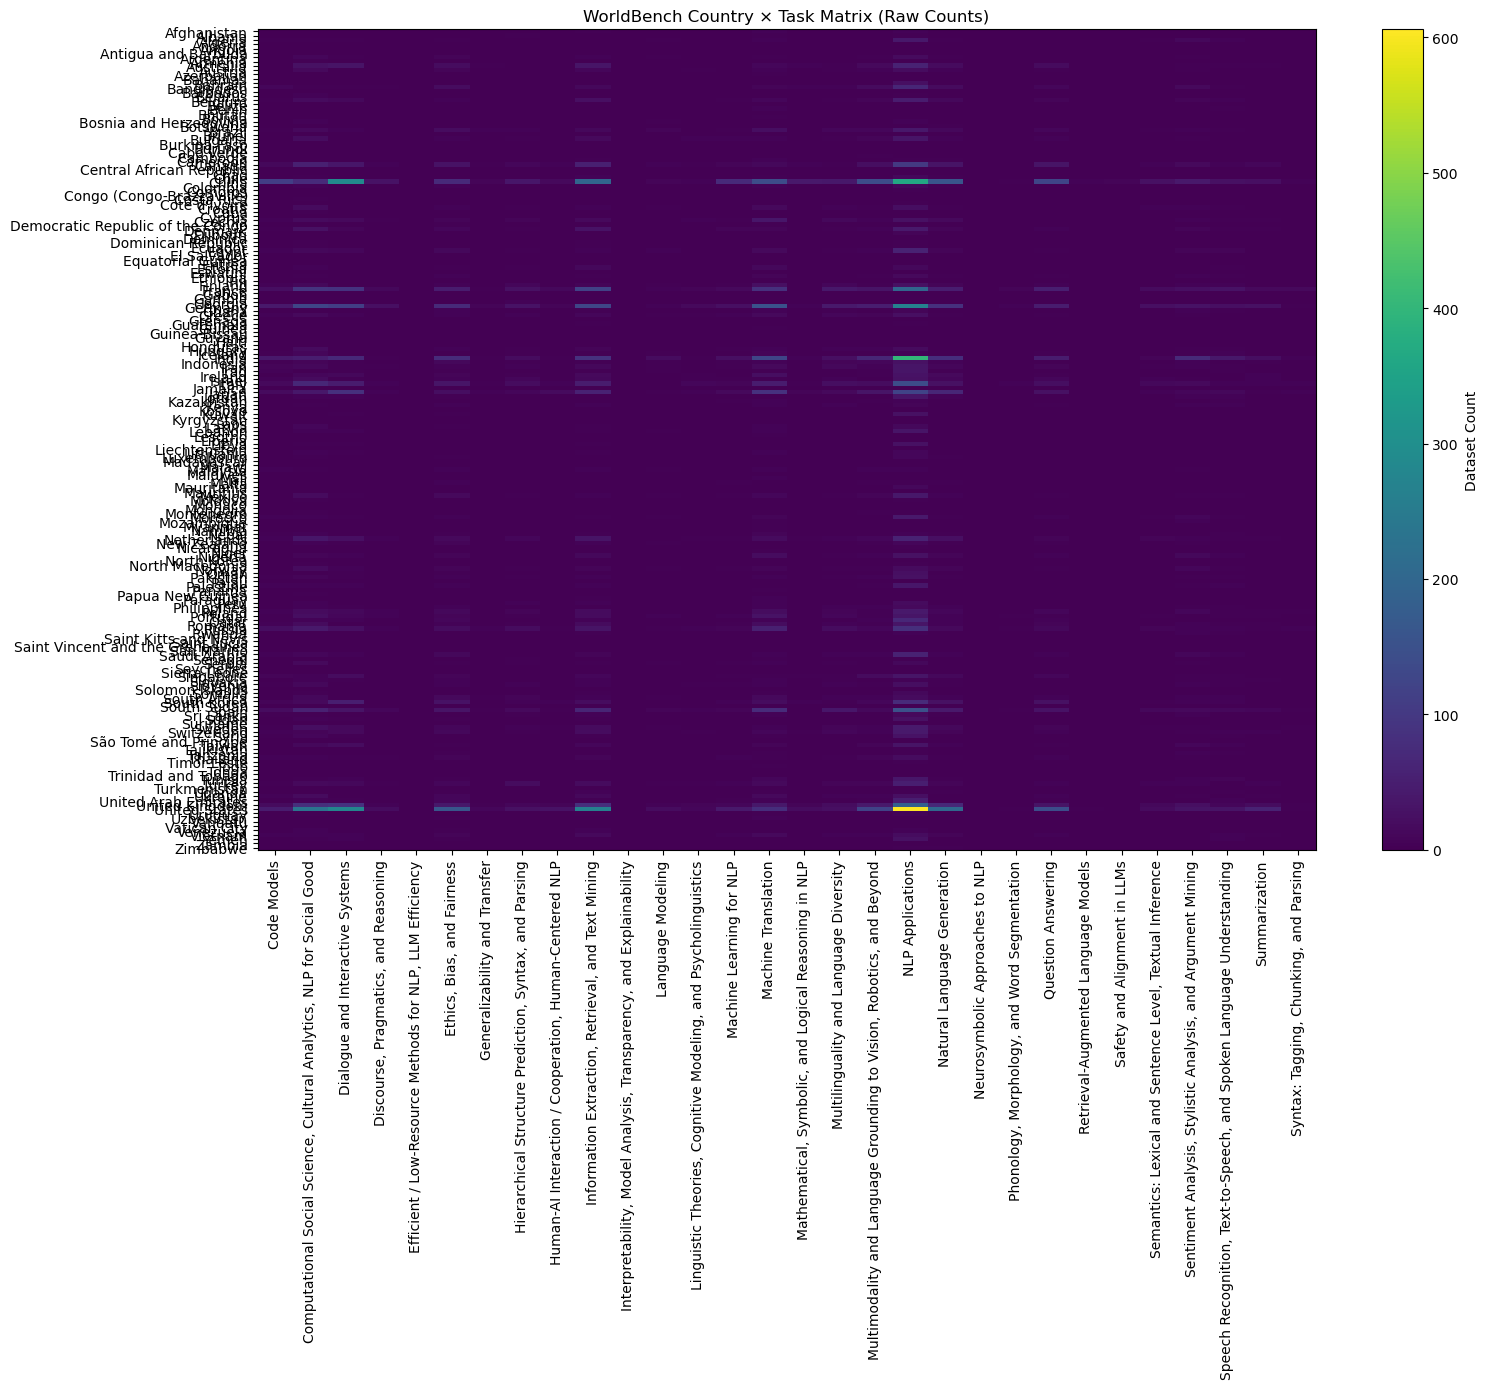

In [27]:
# --- Build matrix ---
matrix = (
    df_expanded
    .groupby(['content_country', 'Task Category'])
    .size()
    .reset_index(name='count')
)

pivot = matrix.pivot(
    index='content_country',
    columns='Task Category',
    values='count'
).fillna(0)

# --- Option 1: raw counts ---
plt.figure(figsize=(16, 14))
plt.imshow(pivot, aspect='auto')
plt.colorbar(label="Dataset Count")

plt.xticks(range(len(pivot.columns)), pivot.columns, rotation=90)
plt.yticks(range(len(pivot.index)), pivot.index)

plt.title("WorldBench Country × Task Matrix (Raw Counts)")
plt.tight_layout()
plt.show()

## Choloropleth

In [29]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

# ============================================================
# 1. Count datasets per content country from ACL-derived auto set
# ============================================================

country_counts = (
    df_expanded
    .groupby("content_country")
    .size()
    .reset_index(name="dataset_count")
)

country_counts["content_country"] = (
    country_counts["content_country"]
    .astype(str)
    .str.strip()
)

country_counts = country_counts[
    country_counts["content_country"].notna()
    & (country_counts["content_country"] != "")
    & (country_counts["content_country"].str.lower() != "nan")
    & (country_counts["content_country"].str.lower() != "not stated")
].copy()


# ============================================================
# 2. Bucket counts
# ============================================================

bins = [-1, 0, 5, 10, 25, 100, 250, 500, np.inf]

bucket_labels = [
    "0",
    "1–5",
    "6–10",
    "11–25",
    "26–100",
    "101–250",
    "251–500",
    "500+"
]

country_counts["coverage_bucket"] = pd.cut(
    country_counts["dataset_count"],
    bins=bins,
    labels=bucket_labels
)

bucket_to_value = {bucket: i for i, bucket in enumerate(bucket_labels)}

country_counts["bucket_value"] = (
    country_counts["coverage_bucket"]
    .map(bucket_to_value)
    .astype(int)
)


# ============================================================
# 3. Colorblind-safer palette: low coverage purple, high coverage orange
# ============================================================



bucket_colors = {
    "0": "#E66101",       # strong orange (extreme low)
    "1–5": "#FDB863",
    "6–10": "#FEE08B",
    "11–25": "#D9EF8B",
    "26–100": "#ABD9E9",  # lighter blue start
    "101–250": "#74ADD1",
    "251–500": "#4575B4",
    "500+": "#313695"     # darker navy → strong dominance
}


colorscale = [
    [i / (len(bucket_labels) - 1), bucket_colors[bucket]]
    for i, bucket in enumerate(bucket_labels)
]


# ============================================================
# 4. Annotation values
# ============================================================

top_countries = (
    country_counts
    .sort_values("dataset_count", ascending=False)
    .head(1)
)

n_leq_10 = (country_counts["dataset_count"] <= 10).sum()
n_leq_25 = (country_counts["dataset_count"] <= 25).sum()
n_countries = country_counts["content_country"].nunique()

coverage_text = (
    "<b>Highest coverage</b><br>"
    + "<br>".join(
        f"{row['content_country']}: {int(row['dataset_count'])}"
        for _, row in top_countries.iterrows()
    )
    + "<br><br><b>Sparse coverage</b><br>"
    + f"{n_leq_10} countries have ≤10<br>"
    + f"{n_leq_25} countries have ≤25<br>"
)


# ============================================================
# 5. Build choropleth
# ============================================================

fig = go.Figure()

fig.add_trace(go.Choropleth(
    locations=country_counts["content_country"],
    locationmode="country names",
    z=country_counts["bucket_value"],
    text=country_counts["content_country"],
    customdata=np.stack([
        country_counts["dataset_count"],
        country_counts["coverage_bucket"].astype(str)
    ], axis=-1),
    colorscale=colorscale,
    zmin=0,
    zmax=len(bucket_labels) - 1,
    showscale=False,  # hide vertical colorbar; custom legend added below
    marker_line_color="white",
    marker_line_width=0.35,
    hovertemplate=(
        "<b>%{text}</b><br>"
        "Dataset count: %{customdata[0]}<br>"
        "Bucket: %{customdata[1]}"
        "<extra></extra>"
    )
))


# ============================================================
# 6. Layout: square-ish single-column friendly
# ============================================================

fig.update_layout(
    width=700,
    height=690,
    margin=dict(l=5, r=5, t=85, b=95),
#     #title=dict(
#         text="NLP dataset coverage by country",
#         x=0.5,
#         xanchor="center",
#         y=0.985,
#         font=dict(size=18)
#     ),
    geo=dict(
    domain=dict(x=[0.00, 1.00], y=[0.18, 0.90]),
    showframe=False,
    showcoastlines=False,
    projection_type="natural earth",
    bgcolor="white",
    showland=True,
    landcolor="#E6E6E6"
    ),
    font=dict(
        family="Arial",
        size=11
    )
)


# ============================================================
#7.  Compact custom legend with non-uniform spacing
# ============================================================

legend_y = 0.90
box_w = 0.018
box_h = 0.025

# Manually tuned x positions for each bucket
legend_x = {
    "0": 0.08,
    "1–5": 0.14,
    "6–10": 0.23,
    "11–25": 0.33,
    "26–100": 0.44,
    "101–250": 0.575,
    "251–500": 0.725,
    "500+": 0.870,
}

fig.add_annotation(
    x=0.5,
    y=0.985,
    xref="paper",
    yref="paper",
    text="<b>NLP Dataset count per country</b>",
    showarrow=False,
    font=dict(size=16)
)

for bucket in bucket_labels:
    x0 = legend_x[bucket]
    x1 = x0 + box_w

    fig.add_shape(
        type="rect",
        xref="paper",
        yref="paper",
        x0=x0,
        x1=x1,
        y0=legend_y,
        y1=legend_y + box_h,
        line=dict(color="rgba(0,0,0,0.3)", width=0.4),
        fillcolor=bucket_colors[bucket]
    )

    fig.add_annotation(
        x=x1 + 0.004,
        y=legend_y + box_h / 2,
        xref="paper",
        yref="paper",
        text=bucket,
        showarrow=False,
        xanchor="left",
        yanchor="middle",
        font=dict(size=17)
    )



# ============================================================
# 8. Coverage inset below map
# ============================================================

fig.add_annotation(
    x=0.02,
    y=0.02,
    xref="paper",
    yref="paper",
    text=coverage_text,
    showarrow=False,
    align="left",
    bgcolor="rgba(255,255,255,0.92)",
    bordercolor="rgba(80,80,80,0.35)",
    borderwidth=1,
    borderpad=6,
    font=dict(size=16)
)



# ============================================================
# 9. Save
# ============================================================

fig.show()

fig.write_html("worldbench_acl_country_coverage_bucketed_square.html")
fig.write_image("worldbench_acl_country_coverage_bucketed_square.png", scale=3)
fig.write_image("worldbench_acl_country_coverage_bucketed_square.pdf")

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px

# --- Country-level dataset counts ---
country_counts = (
    df_expanded
    .groupby("content_country")
    .size()
    .reset_index(name="dataset_count")
)

country_counts["log_dataset_count"] = np.log1p(country_counts["dataset_count"])

# --- Choropleth map ---
fig = px.choropleth(
    country_counts,
    locations="content_country",
    locationmode="country names",
    color="log_dataset_count",
    hover_name="content_country",
    hover_data={
        "dataset_count": True,
        "log_dataset_count": False,
        "content_country": False,
    },
    color_continuous_scale="Viridis",
    labels={
        "log_dataset_count": "log(1 + dataset count)",
        "dataset_count": "Dataset count",
    },
    title="Global NLP Dataset Coverage in WorldBench"
)

fig.update_geos(
    showframe=False,
    showcoastlines=True,
    projection_type="natural earth"
)

fig.update_layout(
    width=1100,
    height=600,
    margin=dict(l=0, r=0, t=50, b=0),
    coloraxis_colorbar=dict(
        title="log(1 + count)"
    )
)

fig.show()

/tmp/ipykernel_2324340/1372949882.py:16: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px

country_counts = (
    df_expanded
    .groupby("content_country")
    .size()
    .reset_index(name="dataset_count")
)

country_counts["log_dataset_count"] = np.log1p(country_counts["dataset_count"])

fig = px.choropleth(
    country_counts,
    locations="content_country",
    locationmode="country names",
    color="log_dataset_count",
    hover_name="content_country",
    hover_data={
        "dataset_count": True,
        "log_dataset_count": False,
        "content_country": False,
    },
    color_continuous_scale="YlGnBu",
    labels={"log_dataset_count": "Dataset count, log scale"},
)

fig.update_geos(
    showframe=False,
    showcoastlines=True,
    showcountries=True,
    projection_type="natural earth",
    landcolor="lightgray",
    bgcolor="white"
)

fig.update_layout(
    width=1100,
    height=620,
    margin=dict(l=0, r=0, t=0, b=0),
    paper_bgcolor="white",
    plot_bgcolor="white",
    coloraxis_colorbar=dict(
        title="log(1 + count)",
        thickness=14,
        len=0.75
    )
)

fig.show()

fig.write_image("worldbench_country_coverage_map.pdf", scale=3)
fig.write_image("worldbench_country_coverage_map.png", scale=3)

/tmp/ipykernel_2324340/1678491859.py:14: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


ValueError: 
Image export using the "kaleido" engine requires the Kaleido package,
which can be installed using pip:

    $ pip install --upgrade kaleido


In [ ]:
country_counts = (
    df_expanded
    .groupby("content_country")
    .size()
    .reset_index(name="dataset_count")
)

country_counts["log_dataset_count"] = np.log1p(country_counts["dataset_count"])

fig = px.choropleth(
    country_counts,
    locations="content_country",
    locationmode="country names",
    color="log_dataset_count",
    hover_name="content_country",
    hover_data={
        "dataset_count": True,
        "log_dataset_count": False,
        "content_country": False,
    },
    color_continuous_scale="Blues",
    labels={"log_dataset_count": "Dataset count, log scale"},
)

fig.update_geos(
    showframe=False,
    showcoastlines=True,
    showcountries=True,
    projection_type="natural earth",
    landcolor="lightgray",
    bgcolor="white"
)

fig.update_layout(
    width=1100,
    height=620,
    margin=dict(l=0, r=0, t=0, b=0),
    paper_bgcolor="white",
    plot_bgcolor="white",
    coloraxis_colorbar=dict(
        title="log(1 + count)",
        thickness=14,
        len=0.75
    )
)

fig.show()

fig.write_image("worldbench_country_coverage_map.pdf", scale=3)
fig.write_image("worldbench_country_coverage_map.png", scale=3)

## Log scale Heatmap

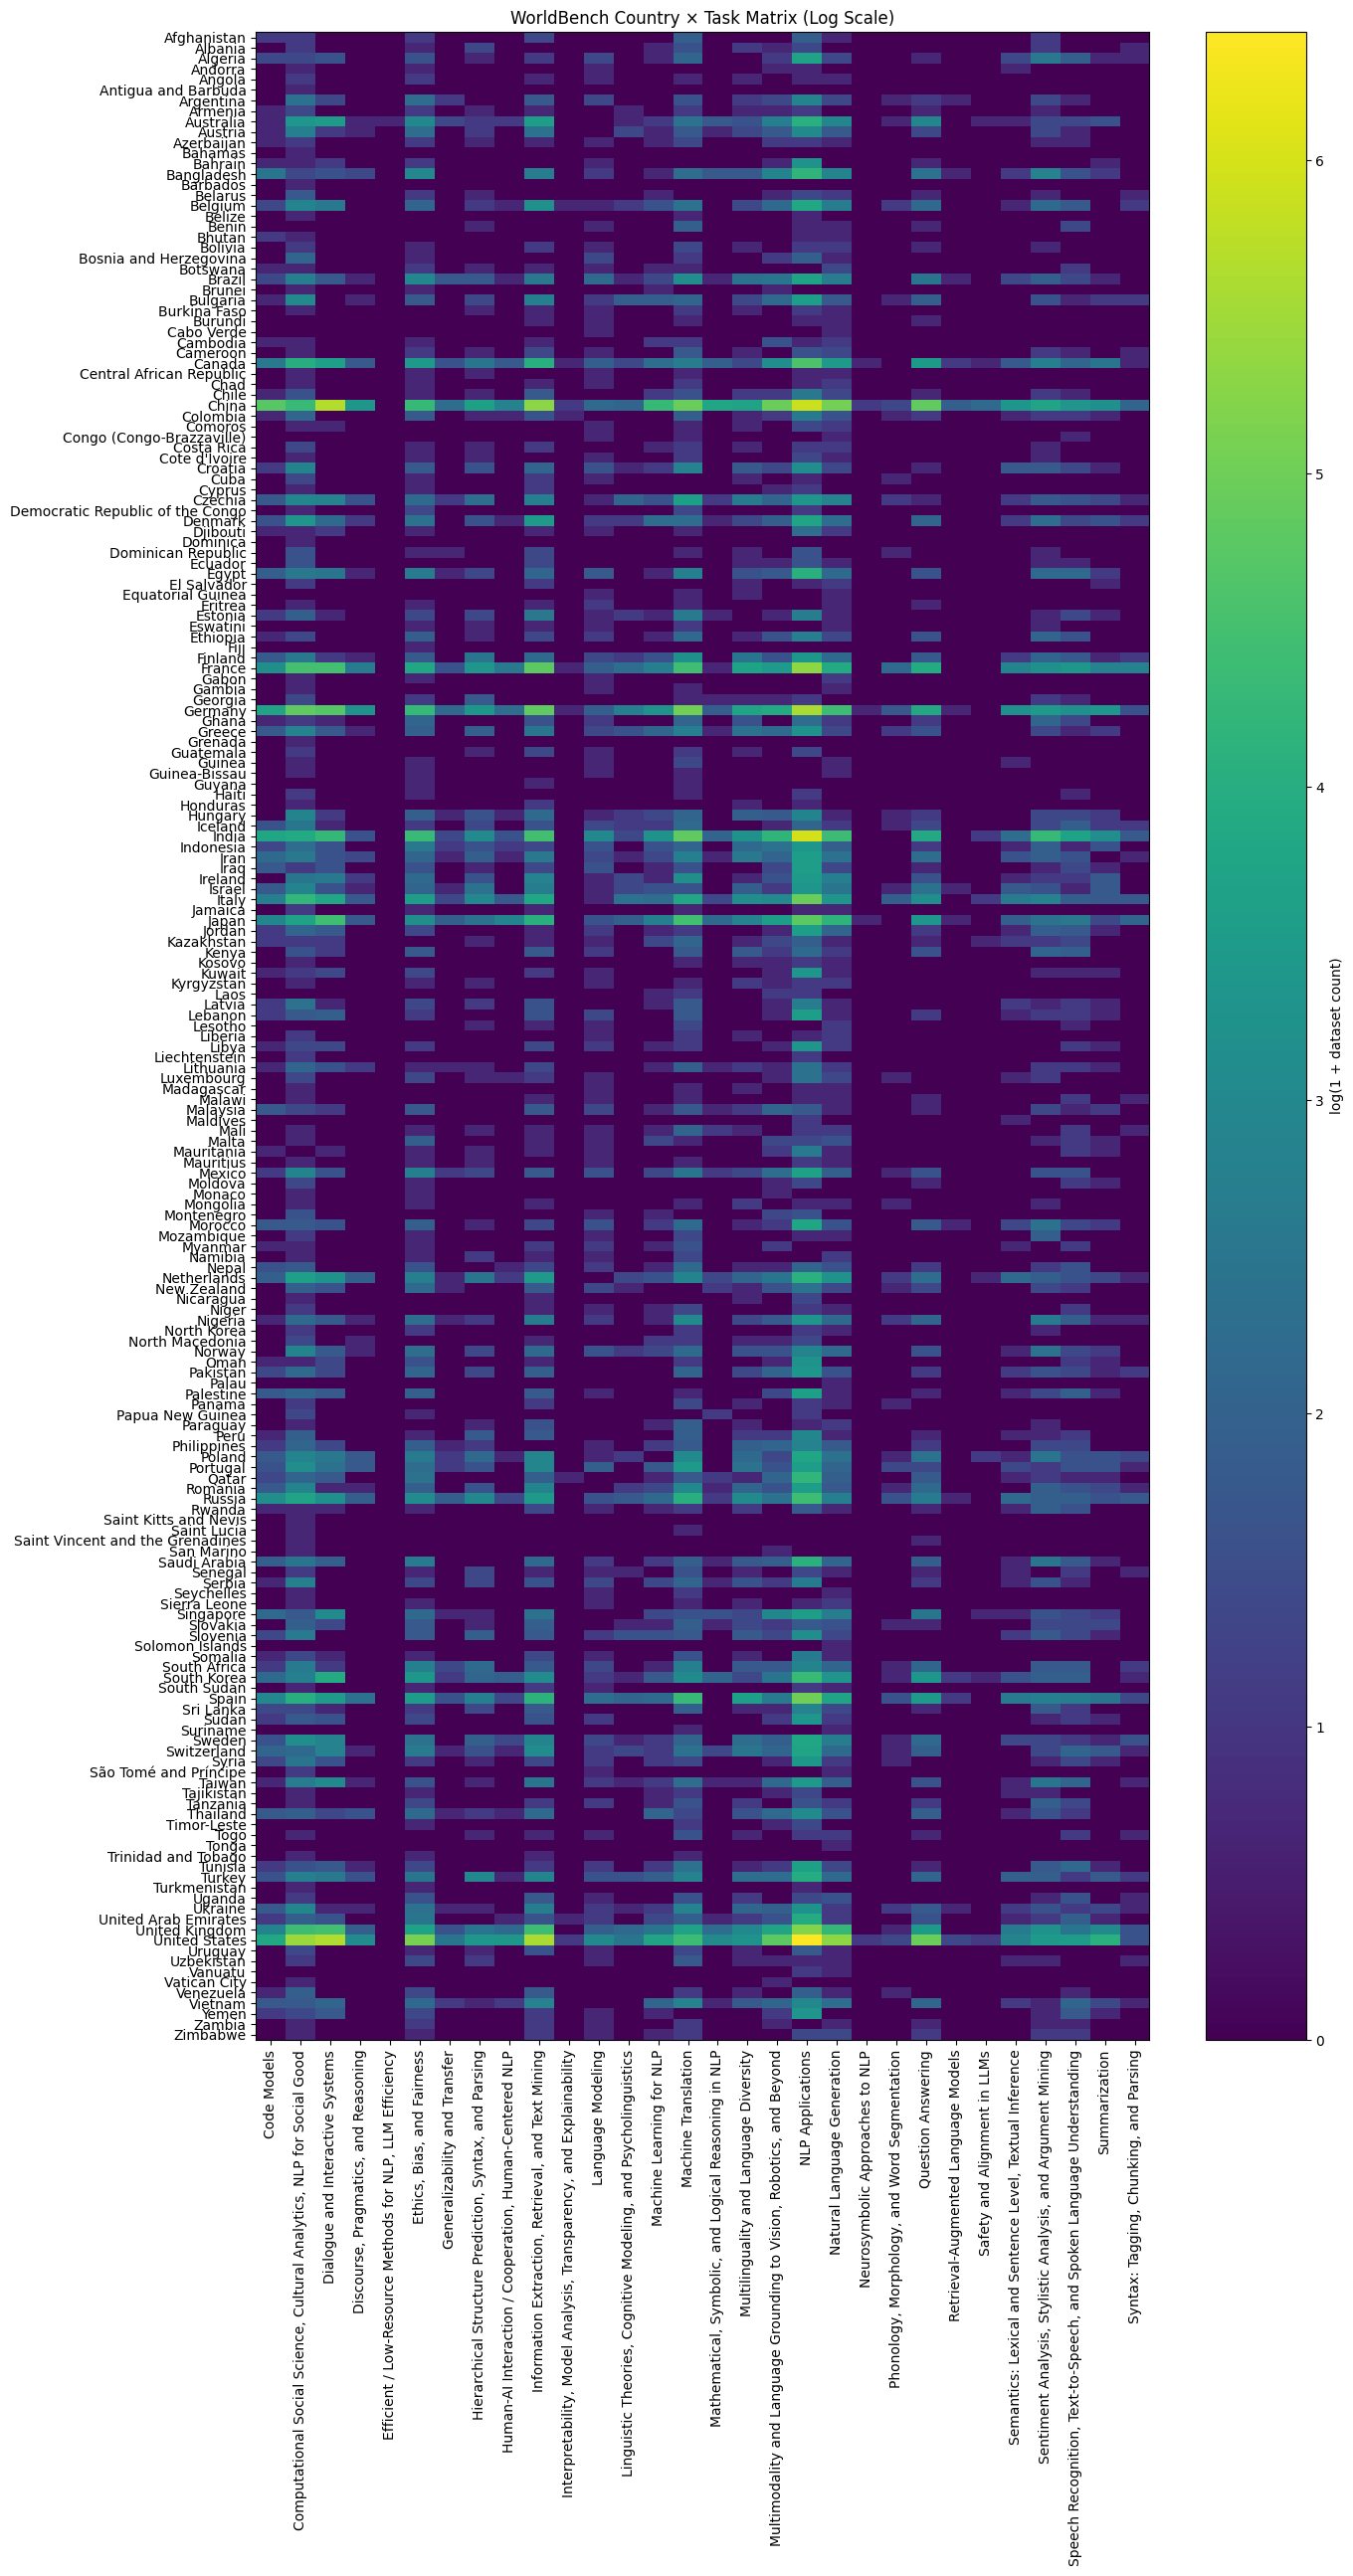

In [29]:
pivot_log = np.log1p(pivot)

plt.figure(figsize=(14, 26))
plt.imshow(pivot_log, aspect='auto')
plt.colorbar(label="log(1 + dataset count)")

plt.xticks(range(len(pivot.columns)), pivot.columns, rotation=90)
plt.yticks(range(len(pivot.index)), pivot.index)

plt.title("WorldBench Country × Task Matrix (Log Scale)")
plt.tight_layout()
plt.savefig('all_log_scale.png')
plt.savefig('all_log_scale.pdf')
plt.show()


Country-task matrix shape: (191, 30)
Zero country-task cells: 59.7%


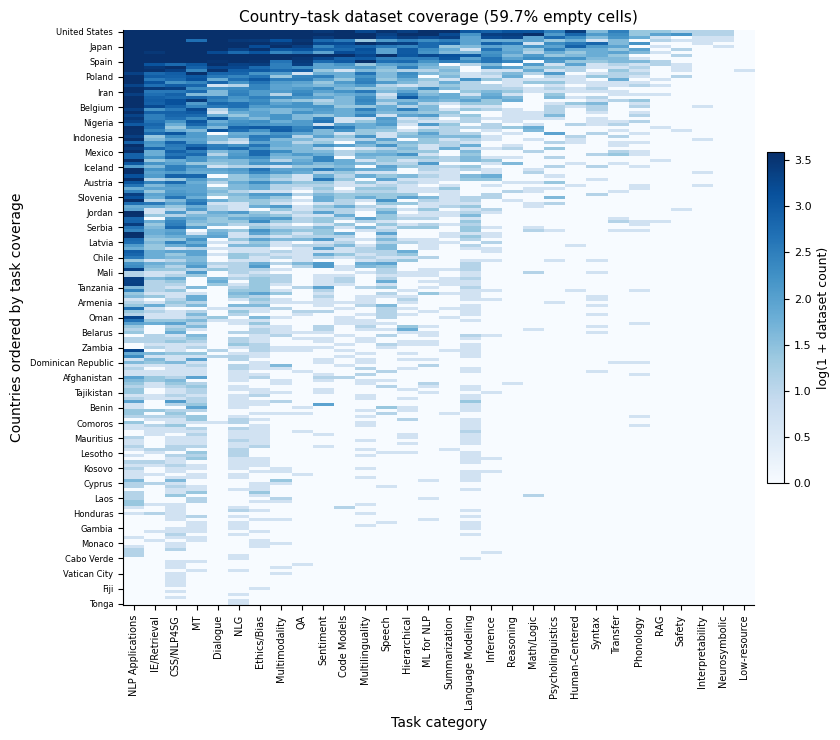

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Build country × task matrix ---
matrix = (
    df_expanded
    .groupby(["content_country", "Task Category"])
    .size()
    .reset_index(name="count")
)

pivot = matrix.pivot(
    index="content_country",
    columns="Task Category",
    values="count"
).fillna(0)

# --- Short task names for visualization ---
task_short = {
    'Human-AI Interaction / Cooperation, Human-Centered NLP': 'Human-Centered',
    'Phonology, Morphology, and Word Segmentation': 'Phonology',
    'Linguistic Theories, Cognitive Modeling, and Psycholinguistics': 'Psycholinguistics',
    'Safety and Alignment in LLMs': 'Safety',
    'Semantics: Lexical and Sentence Level, Textual Inference': 'Inference',
    'Mathematical, Symbolic, and Logical Reasoning in NLP': 'Math/Logic',
    'Retrieval-Augmented Language Models': 'RAG',
    'Neurosymbolic Approaches to NLP': 'Neurosymbolic',
    'Computational Social Science, Cultural Analytics, NLP for Social Good': "CSS/NLP4SG",
    "Dialogue and Interactive Systems": "Dialogue",
    "Discourse, Pragmatics, and Reasoning": "Reasoning",
    "Efficient / Low-Resource Methods for NLP, LLM Efficiency": "Low-resource",
    "Ethics, Bias, and Fairness": "Ethics/Bias",
    "Generalizability and Transfer": "Transfer",
    "Information Extraction, Retrieval, and Text Mining": "IE/Retrieval",
    "Interpretability, Model Analysis, Transparency, and Explainability": "Interpretability",
    "Machine Learning for NLP": "ML for NLP",
    "Machine Translation": "MT",
    "Natural Language Generation": "NLG",
    "Question Answering": "QA",
    'Multimodality and Language Grounding to Vision, Robotics, and Beyond': "Multimodality",
    "Sentiment Analysis, Stylistic Analysis, and Argument Mining": "Sentiment",
    'Speech Recognition, Text-to-Speech, and Spoken Language Understanding': "Speech",
    'Hierarchical Structure Prediction, Syntax, and Parsing': "Hierarchical",
    'Multilinguality and Language Diversity': "Multilinguality",
    'Syntax: Tagging, Chunking, and Parsing': 'Syntax'
}

# --- Order countries by task coverage, then dataset count ---
task_coverage = (pivot > 0).sum(axis=1)
dataset_counts = pivot.sum(axis=1)

country_order = (
    pd.DataFrame({
        "task_coverage": task_coverage,
        "dataset_count": dataset_counts
    })
    .sort_values(["task_coverage", "dataset_count"], ascending=False)
    .index
)

pivot_ordered = pivot.loc[country_order]

# --- Order tasks by total dataset count ---
task_order = pivot_ordered.sum(axis=0).sort_values(ascending=False).index
pivot_ordered = pivot_ordered[task_order]

# --- Shorten task names AFTER ordering ---
pivot_ordered = pivot_ordered.rename(columns=task_short)

# --- Sparsity statistic ---
num_cells = pivot_ordered.shape[0] * pivot_ordered.shape[1]
num_zero_cells = (pivot_ordered == 0).sum().sum()
zero_pct = 100 * num_zero_cells / num_cells

print(f"Country-task matrix shape: {pivot_ordered.shape}")
print(f"Zero country-task cells: {zero_pct:.1f}%")

# --- Log transform for visualization ---
heatmap_values = np.log1p(pivot_ordered.values)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8.5, 7.5))

im = ax.imshow(
    heatmap_values,
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
    vmax=np.percentile(heatmap_values, 98)
)

cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("log(1 + dataset count)", fontsize=9)
cbar.ax.tick_params(labelsize=8)

# X-axis task labels
ax.set_xticks(np.arange(len(pivot_ordered.columns)))
ax.set_xticklabels(
    pivot_ordered.columns,
    rotation=90,
    ha="center",
    fontsize=7
)

# Label every nth country to avoid clutter
n_countries = len(pivot_ordered.index)
step = max(1, n_countries // 35)

yticks = np.arange(0, n_countries, step)
ax.set_yticks(yticks)
ax.set_yticklabels(
    pivot_ordered.index[yticks],
    fontsize=6
)

ax.set_xlabel("Task category")
ax.set_ylabel("Countries ordered by task coverage")
ax.set_title(
    f"Country–task dataset coverage ({zero_pct:.1f}% empty cells)",
    fontsize=11
)

# Clean style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig("fig_country_task_sparsity_heatmap.pdf", bbox_inches="tight")
plt.savefig("fig_country_task_sparsity_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

In [35]:
pivot_explicit = pd.read_csv("pivot_explicit.csv")
pivot_sensitivity = pd.read_csv("pivot_sensitivity.csv")

pivot_sensitivity.head()

,content_country,Code Models,"Computational Social Science, Cultural Analytics, NLP for social good",Dialogue and Interactive Systems,"Discourse, Pragmatics and Reasoning","Efficient/Low-Resource Methods for NLP, LLM Efficiency","Ethics, Bias, and Fairness",Generalizability and Transfer,"Hierarchical Structure Prediction, Syntax, and Parsing","Human-AI Interaction/Cooperation, Human Centered NLP",...,Neurosymbolic approaches to NLP,"Phonology, morphology, and word segmentation",Question Answering,Retrieval Augmented Language Models,Safety and Alignment in LLMs,"Semantics: Lexical and Sentence Level, Textual Inference","Sentiment Analysis, Stylistic Analysis, and Argument Mining","Speech recognition, text-to-speech, and spoken language understanding",Summarization,"Syntax: Tagging, Chunking, and Parsing"
0,Afghanistan,0,1,0,0,0,1,0,0,0,...,0,0,1,0,0,0,1,0,0,0
1,Albania,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
2,Algeria,2,1,2,0,0,1,0,0,0,...,0,0,1,0,0,2,4,5,1,1
3,Andorra,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Angola,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [37]:
pivot_explicit = pd.read_csv("pivot_explicit.csv")
pivot_sensitivity = pd.read_csv("pivot_sensitivity.csv")

pivot = pivot_sensitivity

# matrix = (
#     df_expanded
#     .groupby(["content_country", "Task Category"])
#     .size()
#     .reset_index(name="count")
# )

# pivot = matrix.pivot(
#     index="content_country",
#     columns="Task Category",
#     values="count"
# ).fillna(0)

# # --- Short task names for visualization ---
task_short = {
    'Human-AI Interaction/Cooperation, Human Centered NLP': 'Human-Centered',
    'Phonology, morphology, and word segmentation': 'Phonology',
    'Linguistic Theories, Cognitive Modeling, and Psycholinguistics': 'Psycholinguistics',
    'Safety and Alignment in LLMs': 'Safety',
    'Semantics: Lexical and Sentence Level, Textual Inference': 'Inference',
    'Mathematical, Symbolic, and Logical Reasoning in NLP': 'Math/Logic',
    'Retrieval Augmented Language Models': 'RAG',
    'Neurosymbolic approaches to NLP': 'Neurosymbolic',
    'Computational Social Science, Cultural Analytics, NLP for social good': 'CSS/NLP4SG',
    'Dialogue and Interactive Systems': 'Dialogue',
    'Discourse, Pragmatics and Reasoning': 'Reasoning',
    'Efficient/Low-Resource Methods for NLP, LLM Efficiency': 'Low-resource',
    'Ethics, Bias, and Fairness': 'Ethics/Bias',
    'Generalizability and Transfer': 'Transfer',
    'Information Extraction, Retrieval, and Text Mining': 'IE/Retrieval',
    'Interpretability, Model Analysis, Transparency, and Explainability': 'Interpretability',
    'Machine Learning for NLP': 'ML for NLP',
    'Machine Translation': 'MT',
    'Natural Language Generation': 'NLG',
    'Question Answering': 'QA',
    'Multimodality and Language Grounding to Vision, Robotics and Beyond': 'Multimodality',
    'Sentiment Analysis, Stylistic Analysis, and Argument Mining': 'Sentiment',
    'Speech recognition, text-to-speech, and spoken language understanding': 'Speech',
    'Hierarchical Structure Prediction, Syntax, and Parsing': 'Hierarchical',
    'Multilinguality and Language Diversity': 'Multilinguality',
    'Syntax: Tagging, Chunking, and Parsing': 'Syntax',
}

# --- Order countries by task coverage, then dataset count ---
task_coverage = (pivot > 0).sum(axis=1)
dataset_counts = pivot.sum(axis=1)

country_order = (
    pd.DataFrame({
        "task_coverage": task_coverage,
        "dataset_count": dataset_counts
    })
    .sort_values(["task_coverage", "dataset_count"], ascending=False)
    .index
)

pivot_ordered = pivot.loc[country_order]

# --- Order tasks by total dataset count ---
task_order = pivot_ordered.sum(axis=0).sort_values(ascending=False).index
pivot_ordered = pivot_ordered[task_order]

# --- Shorten task names AFTER ordering ---
pivot_ordered = pivot_ordered.rename(columns=task_short)

# --- Sparsity statistic ---
num_cells = pivot_ordered.shape[0] * pivot_ordered.shape[1]
num_zero_cells = (pivot_ordered == 0).sum().sum()
zero_pct = 100 * num_zero_cells / num_cells

print(f"Country-task matrix shape: {pivot_ordered.shape}")
print(f"Zero country-task cells: {zero_pct:.1f}%")

# --- Log transform for visualization ---
heatmap_values = np.log1p(pivot_ordered.values)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8.5, 7.5))

im = ax.imshow(
    heatmap_values,
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
    vmax=np.percentile(heatmap_values, 98)
)

cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("log(1 + dataset count)", fontsize=9)
cbar.ax.tick_params(labelsize=8)

# X-axis task labels
ax.set_xticks(np.arange(len(pivot_ordered.columns)))
ax.set_xticklabels(
    pivot_ordered.columns,
    rotation=90,
    ha="center",
    fontsize=7
)

# Label every nth country to avoid clutter
n_countries = len(pivot_ordered.index)
step = max(1, n_countries // 35)

yticks = np.arange(0, n_countries, step)
ax.set_yticks(yticks)
ax.set_yticklabels(
    pivot_ordered.index[yticks],
    fontsize=6
)

ax.set_xlabel("Task category")
ax.set_ylabel("Countries ordered by task coverage")
ax.set_title(
    f"Country–task dataset coverage ({zero_pct:.1f}% empty cells)",
    fontsize=11
)

# Clean style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig("afig2_country_task_sparsity_heatmap.pdf", bbox_inches="tight")
plt.savefig("afig_2country_task_sparsity_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

TypeError: '>' not supported between instances of 'str' and 'int'

Country-task matrix shape: (191, 30)
Zero country-task cells: 59.7%


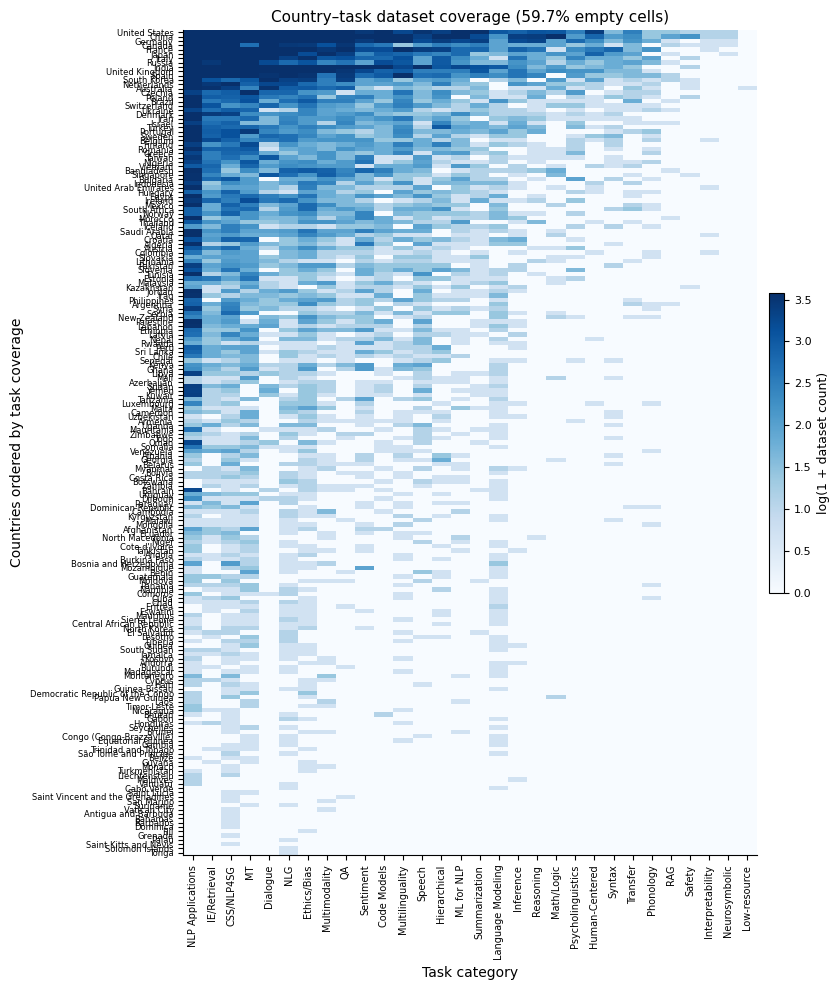

In [31]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# --- Build country × task matrix ---
matrix = (
    df_expanded
    .groupby(["content_country", "Task Category"])
    .size()
    .reset_index(name="count")
)

pivot = matrix.pivot(
    index="content_country",
    columns="Task Category",
    values="count"
).fillna(0)

# --- Short task names for visualization ---
task_short = {
    'Human-AI Interaction / Cooperation, Human-Centered NLP': 'Human-Centered',
    'Phonology, Morphology, and Word Segmentation': 'Phonology',
    'Linguistic Theories, Cognitive Modeling, and Psycholinguistics': 'Psycholinguistics',
    'Safety and Alignment in LLMs': 'Safety',
    'Semantics: Lexical and Sentence Level, Textual Inference': 'Inference',
    'Mathematical, Symbolic, and Logical Reasoning in NLP': 'Math/Logic',
    'Retrieval-Augmented Language Models': 'RAG',
    'Neurosymbolic Approaches to NLP': 'Neurosymbolic',
    'Computational Social Science, Cultural Analytics, NLP for Social Good': "CSS/NLP4SG",
    "Dialogue and Interactive Systems": "Dialogue",
    "Discourse, Pragmatics, and Reasoning": "Reasoning",
    "Efficient / Low-Resource Methods for NLP, LLM Efficiency": "Low-resource",
    "Ethics, Bias, and Fairness": "Ethics/Bias",
    "Generalizability and Transfer": "Transfer",
    "Information Extraction, Retrieval, and Text Mining": "IE/Retrieval",
    "Interpretability, Model Analysis, Transparency, and Explainability": "Interpretability",
    "Machine Learning for NLP": "ML for NLP",
    "Machine Translation": "MT",
    "Natural Language Generation": "NLG",
    "Question Answering": "QA",
    'Multimodality and Language Grounding to Vision, Robotics, and Beyond': "Multimodality",
    "Sentiment Analysis, Stylistic Analysis, and Argument Mining": "Sentiment",
    'Speech Recognition, Text-to-Speech, and Spoken Language Understanding': "Speech",
    'Hierarchical Structure Prediction, Syntax, and Parsing': "Hierarchical",
    'Multilinguality and Language Diversity': "Multilinguality",
    'Syntax: Tagging, Chunking, and Parsing': 'Syntax'
}

# --- Order countries by task coverage, then dataset count ---
task_coverage = (pivot > 0).sum(axis=1)
dataset_counts = pivot.sum(axis=1)

country_order = (
    pd.DataFrame({
        "task_coverage": task_coverage,
        "dataset_count": dataset_counts
    })
    .sort_values(["task_coverage", "dataset_count"], ascending=False)
    .index
)

pivot_ordered = pivot.loc[country_order]

# --- Order tasks by total dataset count ---
task_order = pivot_ordered.sum(axis=0).sort_values(ascending=False).index
pivot_ordered = pivot_ordered[task_order]

# --- Shorten task names AFTER ordering ---
pivot_ordered = pivot_ordered.rename(columns=task_short)

# --- Sparsity statistic ---
num_cells = pivot_ordered.shape[0] * pivot_ordered.shape[1]
num_zero_cells = (pivot_ordered == 0).sum().sum()
zero_pct = 100 * num_zero_cells / num_cells

print(f"Country-task matrix shape: {pivot_ordered.shape}")
print(f"Zero country-task cells: {zero_pct:.1f}%")

# --- Log transform for visualization ---
heatmap_values = np.log1p(pivot_ordered.values)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8.5, 10))

im = ax.imshow(
    heatmap_values,
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
    vmax=np.percentile(heatmap_values, 98)
)

cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("log(1 + dataset count)", fontsize=9)
cbar.ax.tick_params(labelsize=8)

# X-axis task labels
ax.set_xticks(np.arange(len(pivot_ordered.columns)))
ax.set_xticklabels(
    pivot_ordered.columns,
    rotation=90,
    ha="center",
    fontsize=7
)

# Label every nth country to avoid clutter
n_countries = len(pivot_ordered.index)
step = max(1, n_countries // 191)
yticks = np.arange(0, n_countries, step)
ax.set_yticks(yticks)
ax.set_yticklabels(
    pivot_ordered.index[yticks],
    fontsize=6
)

ax.set_xlabel("Task category")
ax.set_ylabel("Countries ordered by task coverage")
ax.set_title(
    f"Country–task dataset coverage ({zero_pct:.1f}% empty cells)",
    fontsize=11
)

# Clean style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig("fig_full_country_task_sparsity_heatmap.pdf", bbox_inches="tight")
plt.savefig("fig_full_country_task_sparsity_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

Country-task matrix shape: (191, 30)
Zero country-task cells: 59.7%
Top panel countries: 95
Bottom panel countries: 96


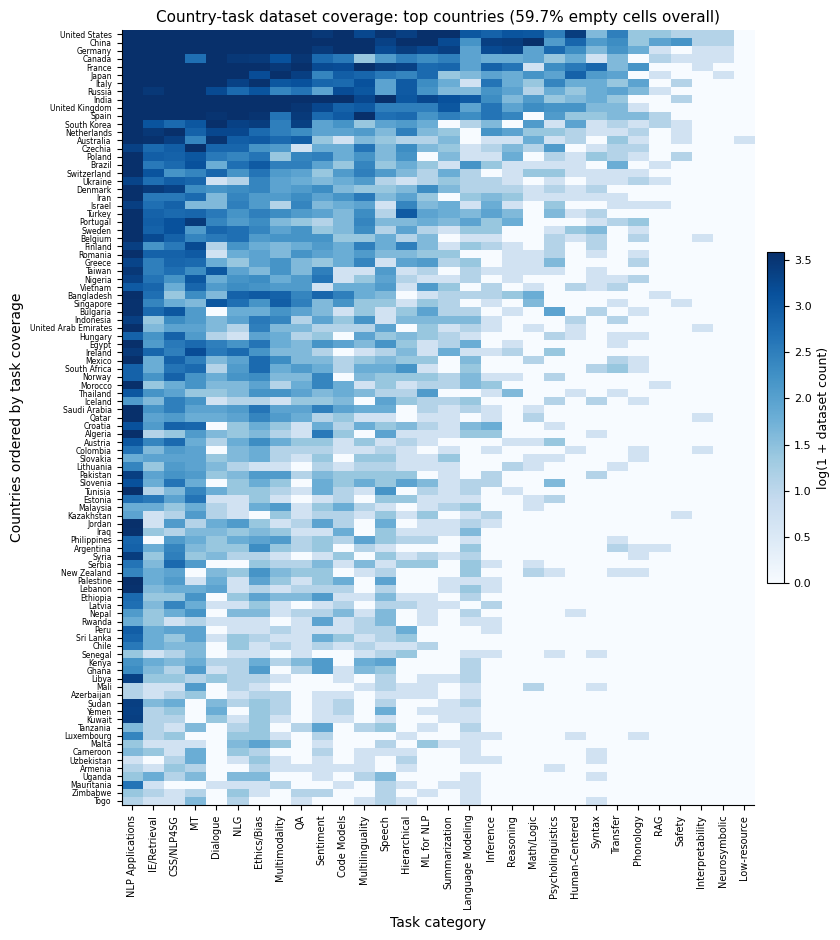

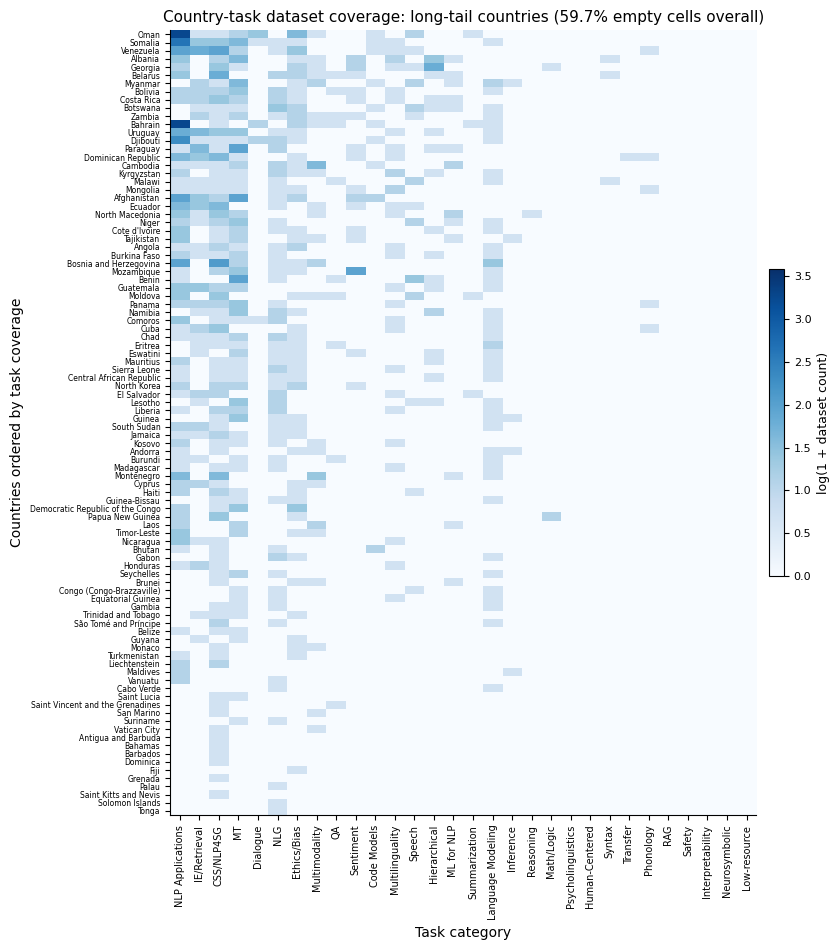

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# Build country × task matrix
# ==================================================

matrix = (
    df_expanded
    .groupby(["content_country", "Task Category"])
    .size()
    .reset_index(name="count")
)

pivot = matrix.pivot(
    index="content_country",
    columns="Task Category",
    values="count"
).fillna(0)

# ==================================================
# Short task names
# ==================================================

task_short = {
    'Human-AI Interaction / Cooperation, Human-Centered NLP': 'Human-Centered',
    'Phonology, Morphology, and Word Segmentation': 'Phonology',
    'Linguistic Theories, Cognitive Modeling, and Psycholinguistics': 'Psycholinguistics',
    'Safety and Alignment in LLMs': 'Safety',
    'Semantics: Lexical and Sentence Level, Textual Inference': 'Inference',
    'Mathematical, Symbolic, and Logical Reasoning in NLP': 'Math/Logic',
    'Retrieval-Augmented Language Models': 'RAG',
    'Neurosymbolic Approaches to NLP': 'Neurosymbolic',
    'Computational Social Science, Cultural Analytics, NLP for Social Good': "CSS/NLP4SG",
    "Dialogue and Interactive Systems": "Dialogue",
    "Discourse, Pragmatics, and Reasoning": "Reasoning",
    "Efficient / Low-Resource Methods for NLP, LLM Efficiency": "Low-resource",
    "Ethics, Bias, and Fairness": "Ethics/Bias",
    "Generalizability and Transfer": "Transfer",
    "Information Extraction, Retrieval, and Text Mining": "IE/Retrieval",
    "Interpretability, Model Analysis, Transparency, and Explainability": "Interpretability",
    "Machine Learning for NLP": "ML for NLP",
    "Machine Translation": "MT",
    "Natural Language Generation": "NLG",
    "Question Answering": "QA",
    'Multimodality and Language Grounding to Vision, Robotics, and Beyond': "Multimodality",
    "Sentiment Analysis, Stylistic Analysis, and Argument Mining": "Sentiment",
    'Speech Recognition, Text-to-Speech, and Spoken Language Understanding': "Speech",
    'Hierarchical Structure Prediction, Syntax, and Parsing': "Hierarchical",
    'Multilinguality and Language Diversity': "Multilinguality",
    'Syntax: Tagging, Chunking, and Parsing': 'Syntax'
}

# ==================================================
# Order countries by task coverage, then dataset count
# ==================================================

task_coverage = (pivot > 0).sum(axis=1)
dataset_counts = pivot.sum(axis=1)

country_order = (
    pd.DataFrame({
        "task_coverage": task_coverage,
        "dataset_count": dataset_counts
    })
    .sort_values(["task_coverage", "dataset_count"], ascending=False)
    .index
)

pivot_ordered = pivot.loc[country_order]

# ==================================================
# Order tasks by total dataset count
# ==================================================

task_order = pivot_ordered.sum(axis=0).sort_values(ascending=False).index
pivot_ordered = pivot_ordered[task_order]

# Shorten task names AFTER ordering
pivot_ordered = pivot_ordered.rename(columns=task_short)

# ==================================================
# Sparsity statistic
# ==================================================

num_cells = pivot_ordered.shape[0] * pivot_ordered.shape[1]
num_zero_cells = (pivot_ordered == 0).sum().sum()
zero_pct = 100 * num_zero_cells / num_cells

print(f"Country-task matrix shape: {pivot_ordered.shape}")
print(f"Zero country-task cells: {zero_pct:.1f}%")

# ==================================================
# Log transform + shared color scale
# ==================================================

heatmap_df = np.log1p(pivot_ordered)

# Use same vmax for both split figures
shared_vmax = np.percentile(heatmap_df.values, 98)

# ==================================================
# Split countries into two panels
# ==================================================

# Option 1: split evenly
split_idx = len(heatmap_df) // 2

# Option 2: manually choose split, e.g. top 95 countries
# split_idx = 95

heatmap_top = heatmap_df.iloc[:split_idx]
heatmap_bottom = heatmap_df.iloc[split_idx:]

print("Top panel countries:", heatmap_top.shape[0])
print("Bottom panel countries:", heatmap_bottom.shape[0])

# ==================================================
# Plot helper
# ==================================================

def plot_country_task_heatmap(
    data,
    title,
    filename_base,
    show_xlabel=True,
    show_colorbar=True
):
    n_countries = data.shape[0]
    n_tasks = data.shape[1]

    # Dynamic height: appendix-friendly but readable
    fig_height = max(6, min(11, n_countries * 0.1))
    fig, ax = plt.subplots(figsize=(8.5, fig_height))

    im = ax.imshow(
        data.values,
        aspect="auto",
        interpolation="nearest",
        cmap="Blues",
        vmin=0,
        vmax=shared_vmax
    )

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
        cbar.set_label("log(1 + dataset count)", fontsize=9)
        cbar.ax.tick_params(labelsize=8)

    # X-axis task labels
    ax.set_xticks(np.arange(n_tasks))
    ax.set_xticklabels(
        data.columns,
        rotation=90,
        ha="center",
        fontsize=7
    )

    # For appendix, show all country labels if split is readable
    ax.set_yticks(np.arange(n_countries))
    ax.set_yticklabels(
        data.index,
        fontsize=5.5
    )

    ax.set_xlabel("Task category" if show_xlabel else "")
    ax.set_ylabel("Countries ordered by task coverage")
    ax.set_title(title, fontsize=11)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    plt.savefig(f"{filename_base}.pdf", bbox_inches="tight")
    plt.savefig(f"{filename_base}.png", dpi=300, bbox_inches="tight")
    plt.show()


# ==================================================
# Plot split heatmaps
# ==================================================

plot_country_task_heatmap(
    heatmap_top,
    title=f"Country-task dataset coverage: top countries ({zero_pct:.1f}% empty cells overall)",
    filename_base="fig_country_task_sparsity_heatmap_top",
    show_xlabel=True,
    show_colorbar=True
)

plot_country_task_heatmap(
    heatmap_bottom,
    title=f"Country-task dataset coverage: long-tail countries ({zero_pct:.1f}% empty cells overall)",
    filename_base="fig_country_task_sparsity_heatmap_bottom",
    show_xlabel=True,
    show_colorbar=True
)

In [33]:
# 'Human-AI Interaction / Cooperation, Human-Centered NLP'
# 'Phonology, Morphology, and Word Segmentation'
# 'Linguistic Theories, Cognitive Modeling, and Psycholinguistics'
# 'Safety and Alignment in LLMs'
# 'Semantics: Lexical and Sentence Level, Textual Inference'
# 'Mathematical, Symbolic, and Logical Reasoning in NLP'
# 'Neurosymbolic Approaches to NLP'
# 'Computational Social Science, Cultural Analytics, NLP for Social Good'
# "Dialogue and Interactive Systems"
# "Discourse, Pragmatics, and Reasoning"
# "Efficient / Low-Resource Methods for NLP, LLM Efficiency"
# "Ethics, Bias, and Fairness"
# "Generalizability and Transfer"
# "Information Extraction, Retrieval, and Text Mining"
# "Interpretability, Model Analysis, Transparency, and Explainability"
# "Machine Learning for NLP"
# "Machine Translation"
# "Natural Language Generation"
# "Question Answering"
# 'Multimodality and Language Grounding to Vision, Robotics, and Beyond'
# "Sentiment Analysis, Stylistic Analysis, and Argument Mining"
# 'Speech Recognition, Text-to-Speech, and Spoken Language Understanding'
# 'Hierarchical Structure Prediction, Syntax, and Parsing'
# 'Multilinguality and Language Diversity'
# 'Syntax: Tagging, Chunking, and Parsing'
# 'Raw Corpus'

Country-task matrix shape: (191, 30)
Zero country-task cells: 59.7%


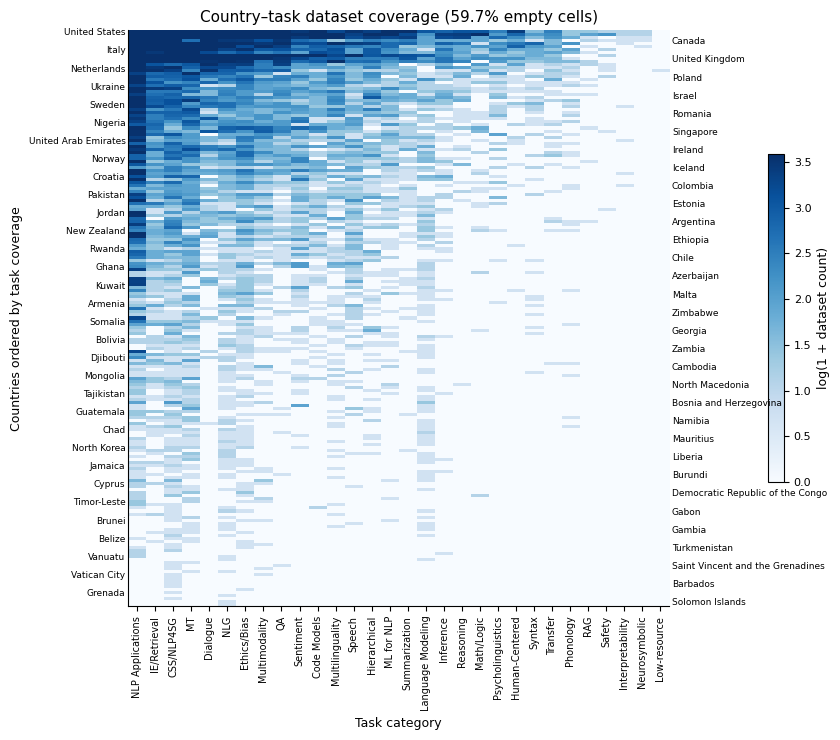

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# Build country × task matrix
# --------------------------------------------------

matrix = (
    df_expanded
    .groupby(["content_country", "Task Category"])
    .size()
    .reset_index(name="count")
)

pivot = matrix.pivot(
    index="content_country",
    columns="Task Category",
    values="count"
).fillna(0)

# --------------------------------------------------
# Short task names for visualization
# --------------------------------------------------

task_short = {
    'Human-AI Interaction / Cooperation, Human-Centered NLP': 'Human-Centered',
    'Phonology, Morphology, and Word Segmentation': 'Phonology',
    'Linguistic Theories, Cognitive Modeling, and Psycholinguistics': 'Psycholinguistics',
    'Safety and Alignment in LLMs': 'Safety',
    'Semantics: Lexical and Sentence Level, Textual Inference': 'Inference',
    'Mathematical, Symbolic, and Logical Reasoning in NLP': 'Math/Logic',
    'Retrieval-Augmented Language Models': 'RAG',
    'Neurosymbolic Approaches to NLP': 'Neurosymbolic',
    'Computational Social Science, Cultural Analytics, NLP for Social Good': "CSS/NLP4SG",
    "Dialogue and Interactive Systems": "Dialogue",
    "Discourse, Pragmatics, and Reasoning": "Reasoning",
    "Efficient / Low-Resource Methods for NLP, LLM Efficiency": "Low-resource",
    "Ethics, Bias, and Fairness": "Ethics/Bias",
    "Generalizability and Transfer": "Transfer",
    "Information Extraction, Retrieval, and Text Mining": "IE/Retrieval",
    "Interpretability, Model Analysis, Transparency, and Explainability": "Interpretability",
    "Machine Learning for NLP": "ML for NLP",
    "Machine Translation": "MT",
    "Natural Language Generation": "NLG",
    "Question Answering": "QA",
    'Multimodality and Language Grounding to Vision, Robotics, and Beyond': "Multimodality",
    "Sentiment Analysis, Stylistic Analysis, and Argument Mining": "Sentiment",
    'Speech Recognition, Text-to-Speech, and Spoken Language Understanding': "Speech",
    'Hierarchical Structure Prediction, Syntax, and Parsing': "Hierarchical",
    'Multilinguality and Language Diversity': "Multilinguality",
    'Syntax: Tagging, Chunking, and Parsing': 'Syntax'
}

# --------------------------------------------------
# Order countries by task coverage, then dataset count
# --------------------------------------------------

task_coverage = (pivot > 0).sum(axis=1)
dataset_counts = pivot.sum(axis=1)

country_order = (
    pd.DataFrame({
        "task_coverage": task_coverage,
        "dataset_count": dataset_counts
    })
    .sort_values(["task_coverage", "dataset_count"], ascending=False)
    .index
)

pivot_ordered = pivot.loc[country_order]

# --------------------------------------------------
# Order tasks by total dataset count
# --------------------------------------------------

task_order = pivot_ordered.sum(axis=0).sort_values(ascending=False).index
pivot_ordered = pivot_ordered[task_order]

# Shorten task names after ordering
pivot_ordered = pivot_ordered.rename(columns=task_short)

# --------------------------------------------------
# Sparsity statistic
# --------------------------------------------------

num_cells = pivot_ordered.shape[0] * pivot_ordered.shape[1]
num_zero_cells = (pivot_ordered == 0).sum().sum()
zero_pct = 100 * num_zero_cells / num_cells

print(f"Country-task matrix shape: {pivot_ordered.shape}")
print(f"Zero country-task cells: {zero_pct:.1f}%")

# --------------------------------------------------
# Log transform
# --------------------------------------------------

heatmap_values = np.log1p(pivot_ordered.values)

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8.5, 7.5))

im = ax.imshow(
    heatmap_values,
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
    vmax=np.percentile(heatmap_values, 98)
)

# Colorbar
cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.15)
cbar.set_label("log(1 + dataset count)", fontsize=9)
cbar.ax.tick_params(labelsize=8)

# --------------------------------------------------
# X-axis task labels
# --------------------------------------------------

ax.set_xticks(np.arange(len(pivot_ordered.columns)))
ax.set_xticklabels(
    pivot_ordered.columns,
    rotation=90,
    ha="center",
    fontsize=7
)

# --------------------------------------------------
# Y-axis country labels on BOTH left and right
# Alternates labels to show more countries without overcrowding
# --------------------------------------------------

n_countries = len(pivot_ordered.index)

# Try 60 first. Increase to 70/75 if still readable.
target_total_labels = 60
step = max(1, n_countries // target_total_labels)

yticks_all = np.arange(0, n_countries, step)

# Alternate labels across sides
yticks_left = yticks_all[::2]
yticks_right = yticks_all[1::2]

# Left labels
ax.set_yticks(yticks_left)
ax.set_yticklabels(
    pivot_ordered.index[yticks_left],
    fontsize=6.5
)

# Right labels
ax_right = ax.twinx()
ax_right.set_ylim(ax.get_ylim())

ax_right.set_yticks(yticks_right)
ax_right.set_yticklabels(
    pivot_ordered.index[yticks_right],
    fontsize=6.5
)

# Clean tick marks
ax.tick_params(axis="y", length=0, pad=2)
ax_right.tick_params(axis="y", length=0, pad=2)

# --------------------------------------------------
# Labels and title
# --------------------------------------------------

ax.set_xlabel("Task category", fontsize=9)
ax.set_ylabel("Countries ordered by task coverage", fontsize=9)

ax.set_title(
    f"Country–task dataset coverage ({zero_pct:.1f}% empty cells)",
    fontsize=11
)

# --------------------------------------------------
# Clean style
# --------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax_right.spines["top"].set_visible(False)
ax_right.spines["right"].set_visible(False)
ax_right.spines["left"].set_visible(False)
ax_right.spines["bottom"].set_visible(False)

# --------------------------------------------------
# Layout and save
# --------------------------------------------------

plt.tight_layout()

plt.savefig(
    "fig_country_task_sparsity_heatmap.pdf",
    bbox_inches="tight",
    pad_inches=0.05
)

plt.savefig(
    "fig_country_task_sparsity_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

1. Are some countries “horizontal bars”?

👉 meaning:

active across MANY tasks

Likely:

US
China
Germany
2. Are some countries “single-column spikes”?

👉 meaning:

only appear in 1–2 tasks

That’s functional underrepresentation

3. Are some tasks globally distributed?

Look at columns:

Machine Translation → likely broad
Dialogue → likely concentrated
4. Are there “dead zones”?

Entire rows near zero.

👉 These are:

nominally “covered” countries
but not meaningfully represented

## Top-K countries

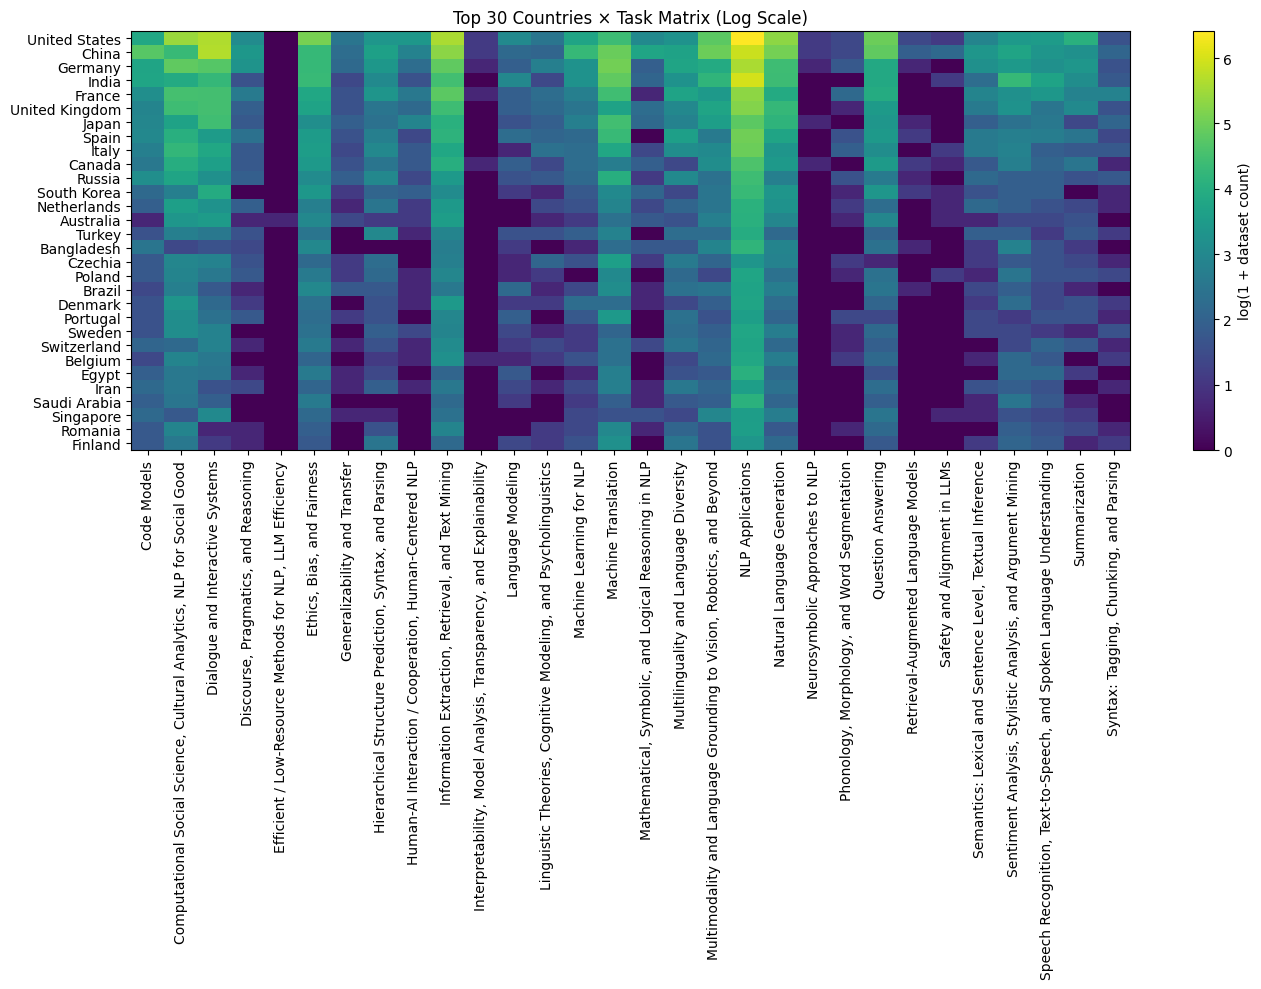

In [35]:

# Top 30 countries by total datasets
top_countries = pivot.sum(axis=1).sort_values(ascending=False).head(30).index

pivot_top = pivot.loc[top_countries]

pivot_top_log = np.log1p(pivot_top)

plt.figure(figsize=(14, 10))
plt.imshow(pivot_top_log, aspect='auto')
plt.colorbar(label="log(1 + dataset count)")

# plt.yticks(range(len(pivot_top.columns)), pivot_top.columns)
# plt.xticks(range(len(pivot_top.index)), pivot_top.index, rotation=90)

plt.xticks(range(len(pivot_top.columns)), pivot_top.columns, rotation=90)
plt.yticks(range(len(pivot_top.index)), pivot_top.index)

plt.title("Top 30 Countries × Task Matrix (Log Scale)")
plt.tight_layout()
plt.savefig('top_30_log_scale.png')
plt.savefig('top_30_log_scale.pdf')
plt.show()


In [36]:
df_expanded['Task Category'].unique()

<ArrowStringArray>
[               'Human-AI Interaction / Cooperation, Human-Centered NLP',
                                           'Natural Language Generation',
                    'Information Extraction, Retrieval, and Text Mining',
                                                      'NLP Applications',
                                                   'Machine Translation',
                          'Phonology, Morphology, and Word Segmentation',
                                            'Ethics, Bias, and Fairness',
 'Computational Social Science, Cultural Analytics, NLP for Social Good',
           'Sentiment Analysis, Stylistic Analysis, and Argument Mining',
  'Multimodality and Language Grounding to Vision, Robotics, and Beyond',
                                                    'Question Answering',
                                      'Dialogue and Interactive Systems',
                                                         'Summarization',
                   

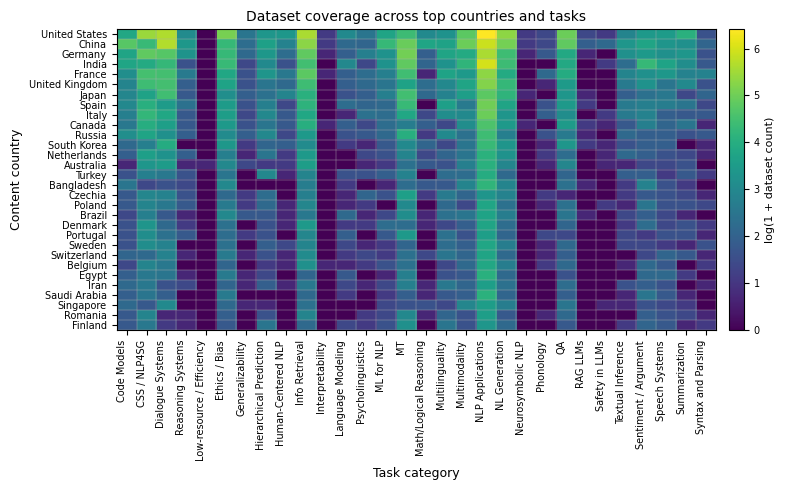

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import textwrap

# Top countries and tasks
top_countries = pivot.sum(axis=1).sort_values(ascending=False).head(30).index
top_tasks = pivot.sum(axis=0).head(30).index

pivot_main = pivot.loc[top_countries, top_tasks]
pivot_main_log = np.log1p(pivot_main)

# Optional: shorter labels
task_short = {
    'Human-AI Interaction / Cooperation, Human-Centered NLP': 'Human-Centered NLP',
   'Phonology, Morphology, and Word Segmentation':'Phonology',
   'Linguistic Theories, Cognitive Modeling, and Psycholinguistics': 'Psycholinguistics',
   'Safety and Alignment in LLMs': 'Safety in LLMs', 
   'Semantics: Lexical and Sentence Level, Textual Inference': 'Textual Inference',
   'Mathematical, Symbolic, and Logical Reasoning in NLP': 'Math/Logical Reasoning',
   'Retrieval-Augmented Language Models': 'RAG LLMs',
   'Neurosymbolic Approaches to NLP': 'Neurosymbolic NLP',
    'Computational Social Science, Cultural Analytics, NLP for Social Good': "CSS / NLP4SG",
    "Dialogue and Interactive Systems": "Dialogue Systems",
    "Discourse, Pragmatics, and Reasoning": "Reasoning Systems",
    "Efficient / Low-Resource Methods for NLP, LLM Efficiency": "Low-resource / Efficiency",
    "Ethics, Bias, and Fairness": "Ethics / Bias",
    "Generalizability and Transfer": "Generalizability",
    "Information Extraction, Retrieval, and Text Mining": "Info Retrieval",
    "Interpretability, Model Analysis, Transparency, and Explainability": "Interpretability",
    "Machine Learning for NLP": "ML for NLP",
    "Machine Translation": "MT",
    "Natural Language Generation": "NL Generation",
    "Question Answering": "QA",
    'Multimodality and Language Grounding to Vision, Robotics, and Beyond': "Multimodality",
    "Sentiment Analysis, Stylistic Analysis, and Argument Mining": "Sentiment / Argument",
    'Speech Recognition, Text-to-Speech, and Spoken Language Understanding': "Speech Systems",
    'Hierarchical Structure Prediction, Syntax, and Parsing': "Hierarchical Prediction",
    'Multilinguality and Language Diversity': "Multilinguality",
    'Syntax: Tagging, Chunking, and Parsing': 'Syntax and Parsing'
}

xlabels = [task_short.get(t, t) for t in pivot_main.columns]

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(pivot_main_log, aspect="auto")

cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("log(1 + dataset count)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

ax.set_xticks(np.arange(len(xlabels)))
ax.set_xticklabels(xlabels, rotation=90, ha="right", fontsize=7)

ax.set_yticks(np.arange(len(pivot_main.index)))
ax.set_yticklabels(pivot_main.index, fontsize=7)

ax.set_xlabel("Task category", fontsize=9)
ax.set_ylabel("Content country", fontsize=9)
ax.set_title("Dataset coverage across top countries and tasks", fontsize=10)

# Light gridlines for readability
ax.set_xticks(np.arange(-0.5, len(xlabels), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(pivot_main.index), 1), minor=True)
ax.grid(which="minor", linewidth=0.3)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.savefig("fig_country_task_heatmap_main.pdf", bbox_inches="tight")
plt.savefig("fig_country_task_heatmap_main.png", dpi=300, bbox_inches="tight")
plt.show()

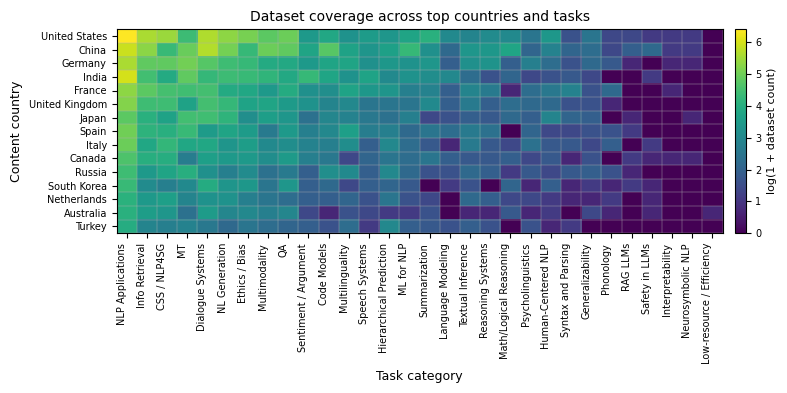

In [38]:
from matplotlib.colors import ListedColormap

cmap = plt.cm.viridis.copy()
cmap.set_under(color='white')  # zeros appear white

im = ax.imshow(pivot_main_log, cmap=cmap, vmin=0.01)

mask = pivot_main == 0
ax.imshow(mask, cmap="gray", alpha=0.1)

# Top countries and tasks
top_countries = pivot.sum(axis=1).sort_values(ascending=False).head(15).index
top_tasks = pivot.sum(axis=0).sort_values(ascending=False).index
pivot_main = pivot.loc[top_countries, top_tasks]
pivot_main_log = np.log1p(pivot_main)

# Optional: shorter labels
task_short = {
    'Human-AI Interaction / Cooperation, Human-Centered NLP': 'Human-Centered NLP',
   'Phonology, Morphology, and Word Segmentation':'Phonology',
   'Linguistic Theories, Cognitive Modeling, and Psycholinguistics': 'Psycholinguistics',
   'Safety and Alignment in LLMs': 'Safety in LLMs', 
   'Semantics: Lexical and Sentence Level, Textual Inference': 'Textual Inference',
   'Mathematical, Symbolic, and Logical Reasoning in NLP': 'Math/Logical Reasoning',
   'Retrieval-Augmented Language Models': 'RAG LLMs',
   'Neurosymbolic Approaches to NLP': 'Neurosymbolic NLP',
    'Computational Social Science, Cultural Analytics, NLP for Social Good': "CSS / NLP4SG",
    "Dialogue and Interactive Systems": "Dialogue Systems",
    "Discourse, Pragmatics, and Reasoning": "Reasoning Systems",
    "Efficient / Low-Resource Methods for NLP, LLM Efficiency": "Low-resource / Efficiency",
    "Ethics, Bias, and Fairness": "Ethics / Bias",
    "Generalizability and Transfer": "Generalizability",
    "Information Extraction, Retrieval, and Text Mining": "Info Retrieval",
    "Interpretability, Model Analysis, Transparency, and Explainability": "Interpretability",
    "Machine Learning for NLP": "ML for NLP",
    "Machine Translation": "MT",
    "Natural Language Generation": "NL Generation",
    "Question Answering": "QA",
    'Multimodality and Language Grounding to Vision, Robotics, and Beyond': "Multimodality",
    "Sentiment Analysis, Stylistic Analysis, and Argument Mining": "Sentiment / Argument",
    'Speech Recognition, Text-to-Speech, and Spoken Language Understanding': "Speech Systems",
    'Hierarchical Structure Prediction, Syntax, and Parsing': "Hierarchical Prediction",
    'Multilinguality and Language Diversity': "Multilinguality",
    'Syntax: Tagging, Chunking, and Parsing': 'Syntax and Parsing'
}

xlabels = [task_short.get(t, t) for t in pivot_main.columns]

fig, ax = plt.subplots(figsize=(8, 4))

cmap = "viridis"   # safe default
#cmap = "magma"   # stronger contrast
#cmap = "cividis" # colorblind-friendly
#cmap = "plasma" # colorblind-friendly

im = ax.imshow(pivot_main_log,cmap=cmap, aspect="auto")

cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("log(1 + dataset count)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

ax.set_xticks(np.arange(len(xlabels)))
ax.set_xticklabels(xlabels, rotation=90, ha="right", fontsize=7)

ax.set_yticks(np.arange(len(pivot_main.index)))
ax.set_yticklabels(pivot_main.index, fontsize=7)

ax.set_xlabel("Task category", fontsize=9)
ax.set_ylabel("Content country", fontsize=9)
ax.set_title("Dataset coverage across top countries and tasks", fontsize=10)

# Light gridlines for readability
ax.set_xticks(np.arange(-0.5, len(xlabels), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(pivot_main.index), 1), minor=True)
ax.grid(which="minor", linewidth=0.3)
ax.tick_params(which="minor", bottom=False, left=False)

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

plt.tight_layout()
plt.savefig("fig_country_task_heatmap_main.pdf", bbox_inches="tight")
plt.savefig("fig_country_task_heatmap_main.png", dpi=300, bbox_inches="tight")
plt.show()

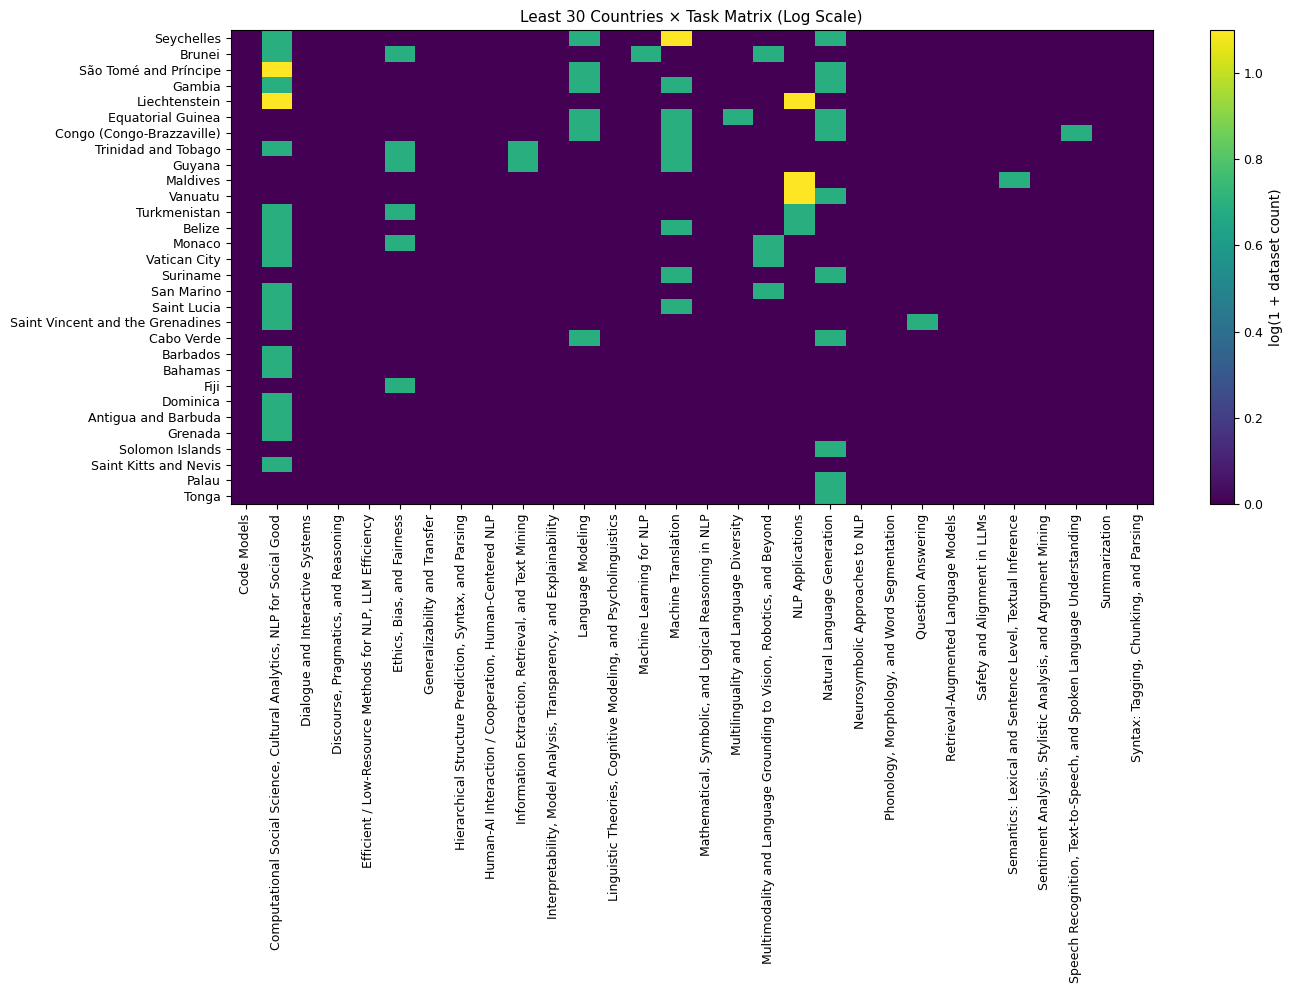

In [39]:
# least 30 countries by total datasets
least_countries = pivot.sum(axis=1).sort_values(ascending=False).tail(30).index

pivot_least = pivot.loc[least_countries]

pivot_least_log = np.log1p(pivot_least)

plt.figure(figsize=(14, 10))
plt.imshow(pivot_least_log, aspect='auto')
plt.colorbar(label="log(1 + dataset count)")

plt.xticks(range(len(pivot_least.columns)), pivot_least.columns, rotation=90)
plt.yticks(range(len(pivot_least.index)), pivot_least.index)

plt.title("Least 30 Countries × Task Matrix (Log Scale)")
plt.tight_layout()
plt.savefig('least_30_log_scale.png')
plt.savefig('least_30_log_scale.pdf')
plt.show()

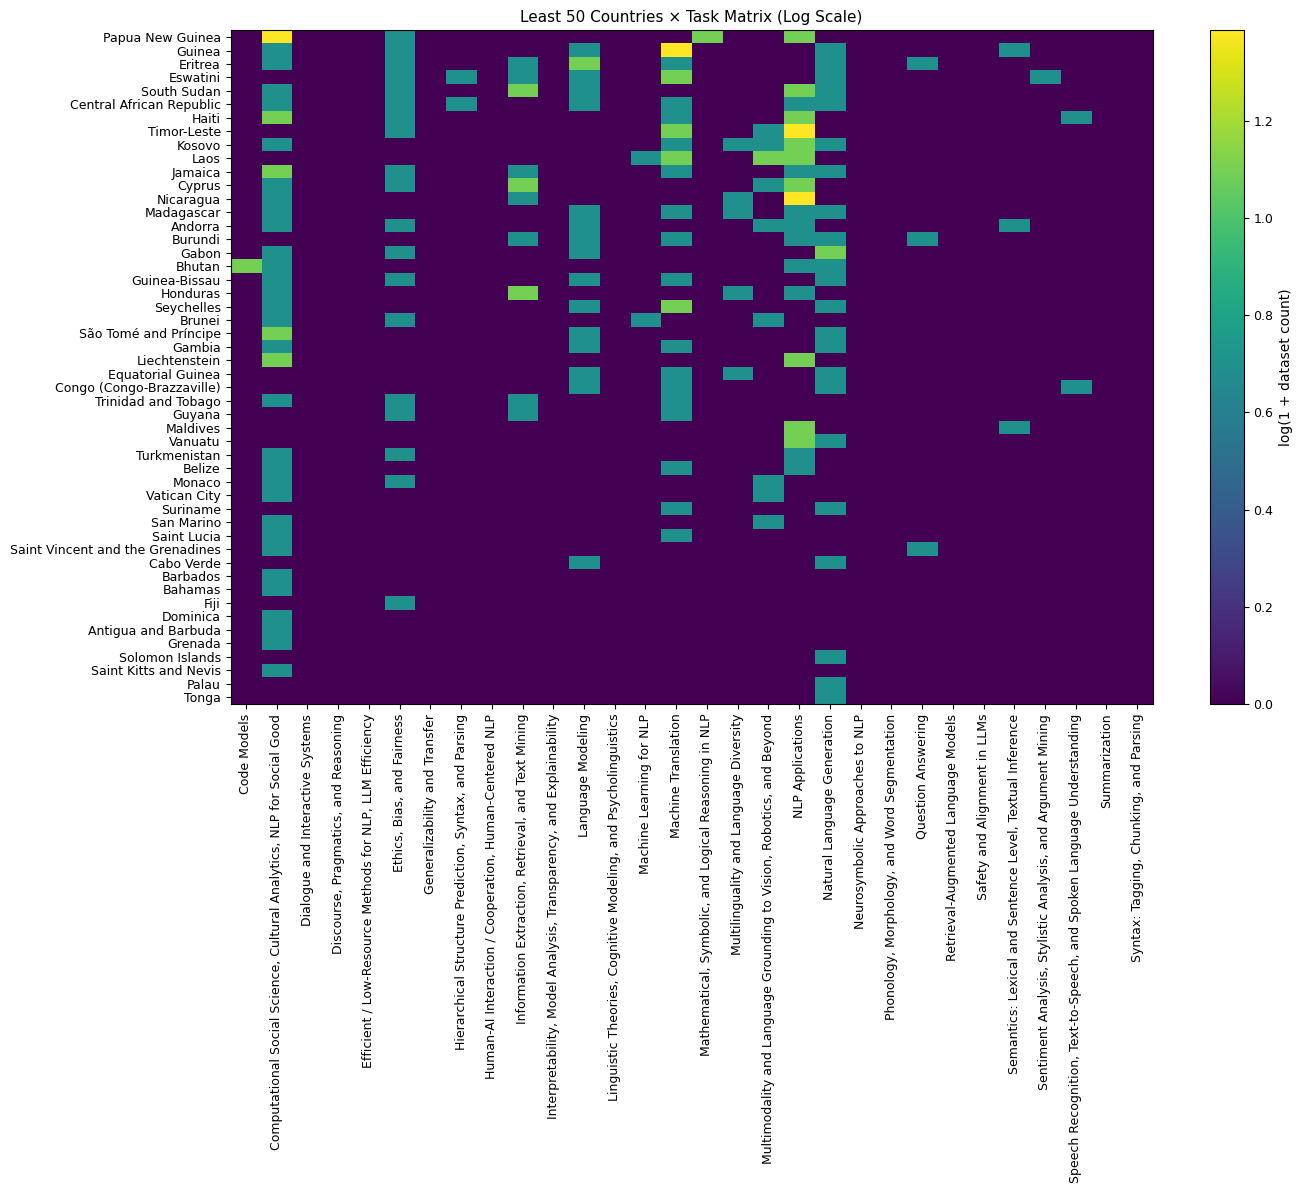

In [40]:
# least 30 countries by total datasets
least_countries = pivot.sum(axis=1).sort_values(ascending=False).tail(50).index

pivot_least = pivot.loc[least_countries]

pivot_least_log = np.log1p(pivot_least)

plt.figure(figsize=(14, 12))
plt.imshow(pivot_least_log, aspect='auto')
plt.colorbar(label="log(1 + dataset count)")

plt.xticks(range(len(pivot_least.columns)), pivot_least.columns, rotation=90)
plt.yticks(range(len(pivot_least.index)), pivot_least.index)

plt.title("Least 50 Countries × Task Matrix (Log Scale)")
plt.tight_layout()
plt.savefig('least_50_log_scale.png')
plt.savefig('least_50_log_scale.pdf')
plt.show()

In [41]:
#look into actual numbers, which tasks does low-resource focus on compared to high-resource

In [42]:
# general producers vs specific producers

In [43]:
tasks_per_country = (pivot > 0).sum(axis=1).sort_values(ascending=False)

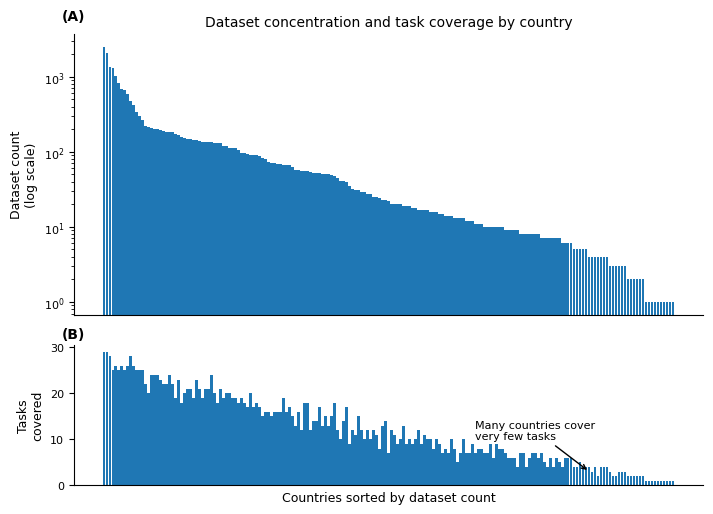

In [44]:
import numpy as np
import matplotlib.pyplot as plt

# Total datasets per country
dataset_counts = pivot.sum(axis=1).sort_values(ascending=False)

# Number of task categories with at least one dataset per country
task_coverage = (pivot > 0).sum(axis=1)

# Use same order for both
countries_ordered = dataset_counts.index
task_coverage_ordered = task_coverage.loc[countries_ordered]

# Option: show all countries if readable, or top 80
N = len(countries_ordered)   # or set N = 80
countries_plot = countries_ordered[:N]
dataset_plot = dataset_counts.loc[countries_plot]
task_plot = task_coverage_ordered.loc[countries_plot]

fig, axes = plt.subplots(
    2, 1,
    figsize=(7.2, 5.2),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

# Panel A: dataset counts
axes[0].bar(range(N), dataset_plot.values)
axes[0].set_yscale("log")
axes[0].set_ylabel("Datasets\n(log scale)", fontsize=9)
axes[0].set_title("Dataset concentration and task coverage by country", fontsize=10)
axes[0].tick_params(axis="y", labelsize=8)
axes[0].text(-0.02, 1.05, "(A)", transform=axes[0].transAxes, fontsize=10, fontweight="bold")
axes[0].set_ylabel("Dataset count\n(log scale)", fontsize=9)
axes[1].set_ylabel("Task categories\ncovered", fontsize=9)
axes[1].text(-0.02, 1.05, "(B)", transform=axes[1].transAxes, fontsize=10, fontweight="bold")

# Panel B: task coverage
axes[1].bar(range(N), task_plot.values)
axes[1].set_ylabel("Tasks\ncovered", fontsize=9)
axes[1].set_xlabel("Countries sorted by dataset count", fontsize=9)
axes[1].tick_params(axis="y", labelsize=8)
axes[1].annotate(
    "Many countries cover\nvery few tasks",
    xy=(int(N*0.85), 3),
    xytext=(int(N*0.65), 10),
    arrowprops=dict(arrowstyle="->"),
    fontsize=8
)

# Avoid unreadable country labels if showing many countries
axes[1].set_xticks([])

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    


plt.tight_layout()
plt.savefig("fig2_country_distribution_task_coverage.pdf", bbox_inches="tight")
plt.savefig("fig2_country_distribution_task_coverage.png", dpi=300, bbox_inches="tight")
plt.show()

In [45]:
dataset_counts = pivot.sum(axis=1).sort_values(ascending=False)
task_coverage = (pivot > 0).sum(axis=1).loc[dataset_counts.index]

n_countries = len(dataset_counts)

stats = {
    "countries_total": n_countries,
    "countries_lt_5_datasets": (dataset_counts <= 5).sum(),
    "countries_lt_10_datasets": (dataset_counts <= 10).sum(),
    "countries_lt_25_datasets": (dataset_counts <= 25).sum(),
    "countries_le_2_tasks": (task_coverage <= 2).sum(),
    "countries_le_5_tasks": (task_coverage <= 5).sum(),
}

stats

{'countries_total': 191,
 'countries_lt_5_datasets': np.int64(34),
 'countries_lt_10_datasets': np.int64(64),
 'countries_lt_25_datasets': np.int64(101),
 'countries_le_2_tasks': np.int64(19),
 'countries_le_5_tasks': np.int64(42)}

In [46]:
for k, v in stats.items():
    if k != "countries_total":
        print(f"{k}: {v} / {n_countries} ({100*v/n_countries:.1f}%)")

countries_lt_5_datasets: 34 / 191 (17.8%)
countries_lt_10_datasets: 64 / 191 (33.5%)
countries_lt_25_datasets: 101 / 191 (52.9%)
countries_le_2_tasks: 19 / 191 (9.9%)
countries_le_5_tasks: 42 / 191 (22.0%)


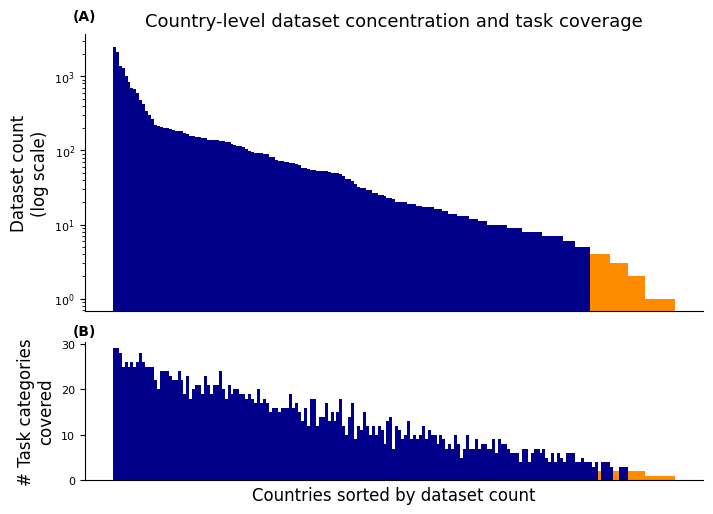

In [47]:
import numpy as np
import matplotlib.pyplot as plt

dataset_counts = pivot.sum(axis=1).sort_values(ascending=False)
task_coverage = (pivot > 0).sum(axis=1).loc[dataset_counts.index]

countries_ordered = dataset_counts.index
N = len(countries_ordered)

dataset_plot = dataset_counts.values
task_plot = task_coverage.values

dataset_tail_threshold = 5
task_tail_threshold = 2

dataset_colors = [
    "darkorange" if v < dataset_tail_threshold else "darkblue"
    for v in dataset_plot
]

task_colors = [
    "darkorange" if v <= task_tail_threshold else "darkblue"
    for v in task_plot
]

fig, axes = plt.subplots(
    2, 1,
    figsize=(7.2, 5.2),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}
)

x = np.arange(N)

axes[0].bar(x, dataset_plot, color=dataset_colors, width=1.0)
axes[0].set_yscale("log")
axes[0].set_ylabel("Dataset count\n(log scale)", fontsize=12)
axes[0].set_title("Country-level dataset concentration and task coverage", fontsize=13)

axes[1].bar(x, task_plot, color=task_colors, width=1.0)
axes[1].set_ylabel("# Task categories\ncovered", fontsize=12)
axes[1].set_xlabel("Countries sorted by dataset count", fontsize=12)

axes[0].text(-0.02, 1.05, "(A)", transform=axes[0].transAxes,
             fontsize=10, fontweight="bold")
axes[1].text(-0.02, 1.05, "(B)", transform=axes[1].transAxes,
             fontsize=10, fontweight="bold")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", labelsize=8)

axes[1].set_xticks([])


# plt.rcParams.update({
#     "font.size": 35,
#     "axes.titlesize": 35,
#     "axes.labelsize": 35,
#     "xtick.labelsize": 35,
#     "ytick.labelsize": 35,
# })

plt.tight_layout()
plt.savefig("fig2_country_distribution_task_coverage_colored.pdf", bbox_inches="tight")
plt.savefig("fig2_country_distribution_task_coverage_colored.png", dpi=300, bbox_inches="tight")
plt.show()

In [48]:
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})


In [49]:
all_countries = """
Nigeria
South Africa
Angola
Burkina Faso
Cabo Verde
Morocco
Egypt
Tunisia
Benin
Malawi
South Sudan
Democratic Republic of the Congo
Kenya
Algeria
Mozambique
Zambia
Guinea
Senegal
Madagascar
Cameroon
Cote d'Ivoire
Guinea-Bissau
São Tomé and Príncipe
Libya
Ethiopia
Uganda
Rwanda
Tanzania
Togo
Burundi
Ghana
Eritrea
Niger
Somalia
Zimbabwe
Djibouti
Mali
Central African Republic
Namibia
Sierra Leone
Comoros
Mauritius
Seychelles
Gambia
Liberia
Equatorial Guinea
Sudan
Gabon
Botswana
Chad
Congo (Congo-Brazzaville)
Eswatini
Lesotho
Mauritania
United States
Canada
Mexico
Brazil
Paraguay
Peru
Bolivia
Colombia
Chile
Guatemala
Ecuador
Argentina
Costa Rica
Cuba
Dominican Republic
El Salvador
Honduras
Nicaragua
Panama
Uruguay
Venezuela
Haiti
Jamaica
Suriname
Antigua and Barbuda
Bahamas
Barbados
Belize
Dominica
Grenada
Guyana
Saint Kitts and Nevis
Saint Lucia
Saint Vincent and the Grenadines
Trinidad and Tobago
India
Philippines
Singapore
China
Japan
South Korea
Myanmar
Indonesia
Vietnam
Turkey
Iraq
Saudi Arabia
Malaysia
Iran
Bangladesh
Pakistan
Taiwan
Thailand
Kazakhstan
Kyrgyzstan
Timor-Leste
Lebanon
Syria
Yemen
Bahrain
Jordan
Kuwait
Oman
Qatar
United Arab Emirates
Sri Lanka
Tajikistan
Afghanistan
Israel
Azerbaijan
Uzbekistan
Nepal
Brunei
Georgia
Cambodia
Armenia
Mongolia
Laos
Maldives
Turkmenistan
Bhutan
Cyprus
North Korea
Palestine
United Kingdom
Ireland
Spain
Italy
Germany
Russia
France
Switzerland
Poland
Netherlands
Latvia
Portugal
Romania
Greece
Slovenia
Serbia
Slovakia
Luxembourg
Belgium
Ukraine
Belarus
Austria
Czechia
Denmark
Sweden
Norway
Finland
Hungary
Bulgaria
Estonia
Iceland
Albania
Croatia
Lithuania
Malta
North Macedonia
Vatican City
Bosnia and Herzegovina
Moldova
Montenegro
Andorra
Kosovo
Liechtenstein
Monaco
San Marino
Australia
New Zealand
Papua New Guinea
Samoa
Fiji
Tonga
Vanuatu
Marshall Islands
Micronesia
Nauru
Solomon Islands
Palau
Kiribati
Tuvalu
""".strip().splitlines()

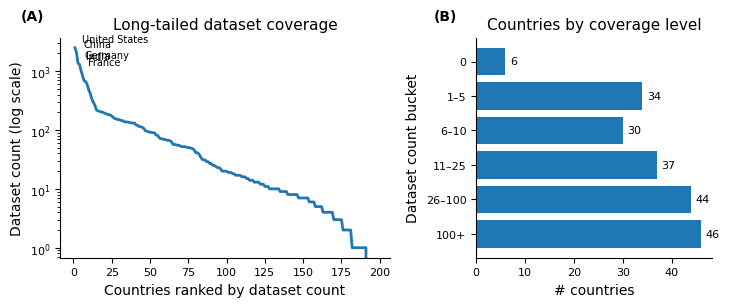

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Country-level dataset counts from pivot ---
# dataset_counts = pivot.sum(axis=1).sort_values(ascending=False)
dataset_counts = (
    pivot.sum(axis=1)
    .reindex(all_countries, fill_value=0)
    .sort_values(ascending=False)
)

# Optional: include countries with zero datasets if you have a full country list
# all_countries = [...]
# dataset_counts = dataset_counts.reindex(all_countries, fill_value=0).sort_values(ascending=False)

N = len(dataset_counts)
x = np.arange(1, N + 1)

# --- Scarcity buckets ---
bins = [-0.5, 0.5, 5.5, 10.5, 25.5, 100.5, np.inf]
labels = ["0", "1–5", "6–10", "11–25", "26–100", "100+"]

bucket_counts = pd.cut(
    dataset_counts,
    bins=bins,
    labels=labels
).value_counts().reindex(labels, fill_value=0)

# --- Plot ---
fig, axes = plt.subplots(
    1, 2,
    figsize=(7.4, 3.2),
    gridspec_kw={"width_ratios": [1.4, 1]}
)

# Panel A: rank-frequency plot
axes[0].plot(x, dataset_counts.values, linewidth=2)
axes[0].set_yscale("log")
axes[0].set_xlabel("Countries ranked by dataset count")
axes[0].set_ylabel("Dataset count (log scale)")
axes[0].set_title("Long-tailed dataset coverage", fontsize=11)

# Annotate top countries
top_k = 5
for i, (country, count) in enumerate(dataset_counts.head(top_k).items(), start=1):
    axes[0].annotate(
        country,
        xy=(i, count),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=7
    )

# Panel B: scarcity bucket chart
y_pos = np.arange(len(labels))
axes[1].barh(y_pos, bucket_counts.values)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(labels)
axes[1].invert_yaxis()
axes[1].set_xlabel("# countries")
axes[1].set_ylabel("Dataset count bucket")
axes[1].set_title("Countries by coverage level", fontsize=11)

# Add values at end of bars
for y, v in zip(y_pos, bucket_counts.values):
    axes[1].text(
        v + max(bucket_counts.values) * 0.02,
        y,
        str(v),
        va="center",
        fontsize=8
    )

# Panel labels
axes[0].text(
    -0.12, 1.08, "(A)",
    transform=axes[0].transAxes,
    fontsize=10,
    fontweight="bold"
)
axes[1].text(
    -0.18, 1.08, "(B)",
    transform=axes[1].transAxes,
    fontsize=10,
    fontweight="bold"
)

# Clean style
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig("fig_country_longtail_scarcity.pdf", bbox_inches="tight")
plt.savefig("fig_country_longtail_scarcity.png", dpi=300, bbox_inches="tight")
plt.show()

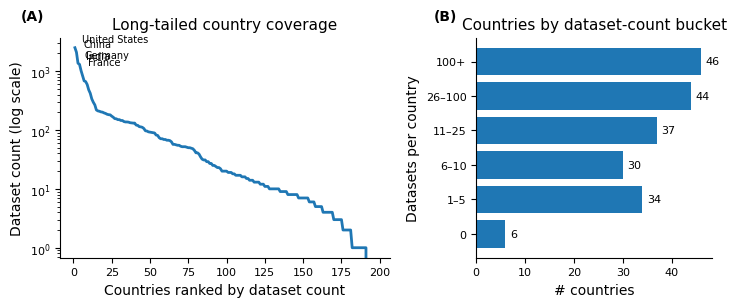

In [51]:
# --- Country-level dataset counts from pivot ---
# dataset_counts = pivot.sum(axis=1).sort_values(ascending=False)
dataset_counts = (
    pivot.sum(axis=1)
    .reindex(all_countries, fill_value=0)
    .sort_values(ascending=False)
)

# Optional: include countries with zero datasets if you have a full country list
# all_countries = [...]
# dataset_counts = dataset_counts.reindex(all_countries, fill_value=0).sort_values(ascending=False)

N = len(dataset_counts)
x = np.arange(1, N + 1)

# --- Scarcity buckets ---
bins = [-0.5, 0.5, 5.5, 10.5, 25.5, 100.5, np.inf]
labels = ["0", "1–5", "6–10", "11–25", "26–100", "100+"]

bucket_counts = pd.cut(
    dataset_counts,
    bins=bins,
    labels=labels
).value_counts().reindex(labels, fill_value=0)

# --- Plot ---
fig, axes = plt.subplots(
    1, 2,
    figsize=(7.4, 3.2),
    gridspec_kw={"width_ratios": [1.4, 1]}
)

# Panel A: rank-frequency plot
axes[0].plot(x, dataset_counts.values, linewidth=2)
axes[0].set_yscale("log")
axes[0].set_xlabel("Countries ranked by dataset count")
axes[0].set_ylabel("Dataset count (log scale)")
axes[0].set_title("Long-tailed dataset coverage", fontsize=11)

# Annotate top countries
top_k = 5
for i, (country, count) in enumerate(dataset_counts.head(top_k).items(), start=1):
    axes[0].annotate(
        country,
        xy=(i, count),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=7
    )

# Panel B: scarcity bucket chart
y_pos = np.arange(len(labels))
axes[1].barh(y_pos, bucket_counts.values)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(labels)
axes[1].invert_yaxis()
axes[1].set_xlabel("# countries")
axes[1].set_ylabel("Dataset count bucket")
axes[1].set_title("Countries by coverage level", fontsize=11)

# Add values at end of bars
for y, v in zip(y_pos, bucket_counts.values):
    axes[1].text(
        v + max(bucket_counts.values) * 0.02,
        y,
        str(v),
        va="center",
        fontsize=8
    )

# Panel labels
axes[0].text(
    -0.12, 1.08, "(A)",
    transform=axes[0].transAxes,
    fontsize=10,
    fontweight="bold"
)
axes[1].text(
    -0.18, 1.08, "(B)",
    transform=axes[1].transAxes,
    fontsize=10,
    fontweight="bold"
)

# Panel A title
axes[0].set_title("Long-tailed country coverage", fontsize=11)

# Remove top-country annotations entirely, or label only top 3
# Comment out the annotation block for now.

# Panel B title
axes[1].set_title("Countries by dataset-count bucket", fontsize=11)

# Better labels
axes[1].set_xlabel("# countries")
axes[1].set_ylabel("Datasets per country")

# Optional: reverse order so scarcity appears at bottom-to-top naturally
axes[1].invert_yaxis()

# Clean style
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig("fig_country_longtail_scarcity.pdf", bbox_inches="tight")
plt.savefig("fig_country_longtail_scarcity.png", dpi=300, bbox_inches="tight")
plt.show()






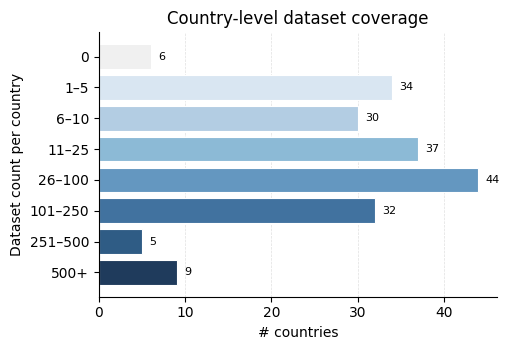

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Full country list for including zero-coverage countries
# ------------------------------------------------------------
all_countries = """
Nigeria
South Africa
Angola
Burkina Faso
Cabo Verde
Morocco
Egypt
Tunisia
Benin
Malawi
South Sudan
Democratic Republic of the Congo
Kenya
Algeria
Mozambique
Zambia
Guinea
Senegal
Madagascar
Cameroon
Cote d'Ivoire
Guinea-Bissau
São Tomé and Príncipe
Libya
Ethiopia
Uganda
Rwanda
Tanzania
Togo
Burundi
Ghana
Eritrea
Niger
Somalia
Zimbabwe
Djibouti
Mali
Central African Republic
Namibia
Sierra Leone
Comoros
Mauritius
Seychelles
Gambia
Liberia
Equatorial Guinea
Sudan
Gabon
Botswana
Chad
Congo (Congo-Brazzaville)
Eswatini
Lesotho
Mauritania
United States
Canada
Mexico
Brazil
Paraguay
Peru
Bolivia
Colombia
Chile
Guatemala
Ecuador
Argentina
Costa Rica
Cuba
Dominican Republic
El Salvador
Honduras
Nicaragua
Panama
Uruguay
Venezuela
Haiti
Jamaica
Suriname
Antigua and Barbuda
Bahamas
Barbados
Belize
Dominica
Grenada
Guyana
Saint Kitts and Nevis
Saint Lucia
Saint Vincent and the Grenadines
Trinidad and Tobago
India
Philippines
Singapore
China
Japan
South Korea
Myanmar
Indonesia
Vietnam
Turkey
Iraq
Saudi Arabia
Malaysia
Iran
Bangladesh
Pakistan
Taiwan
Thailand
Kazakhstan
Kyrgyzstan
Timor-Leste
Lebanon
Syria
Yemen
Bahrain
Jordan
Kuwait
Oman
Qatar
United Arab Emirates
Sri Lanka
Tajikistan
Afghanistan
Israel
Azerbaijan
Uzbekistan
Nepal
Brunei
Georgia
Cambodia
Armenia
Mongolia
Laos
Maldives
Turkmenistan
Bhutan
Cyprus
North Korea
Palestine
United Kingdom
Ireland
Spain
Italy
Germany
Russia
France
Switzerland
Poland
Netherlands
Latvia
Portugal
Romania
Greece
Slovenia
Serbia
Slovakia
Luxembourg
Belgium
Ukraine
Belarus
Austria
Czechia
Denmark
Sweden
Norway
Finland
Hungary
Bulgaria
Estonia
Iceland
Albania
Croatia
Lithuania
Malta
North Macedonia
Vatican City
Bosnia and Herzegovina
Moldova
Montenegro
Andorra
Kosovo
Liechtenstein
Monaco
San Marino
Australia
New Zealand
Papua New Guinea
Samoa
Fiji
Tonga
Vanuatu
Marshall Islands
Micronesia
Nauru
Solomon Islands
Palau
Kiribati
Tuvalu
""".strip().splitlines()

# ------------------------------------------------------------
# Country-level dataset counts
# ------------------------------------------------------------
# If pivot is country x task, this counts total rows across tasks.
# If you have a unique dataset id/name column, use the alternate version below.

dataset_counts = (
    pivot.sum(axis=1)
    .reindex(all_countries, fill_value=0)
    .sort_values(ascending=False)
)

# Alternate, preferred if df_expanded has a unique dataset identifier:
# dataset_counts = (
#     df_expanded.groupby("content_country")["dataset_name"]
#     .nunique()
#     .reindex(all_countries, fill_value=0)
#     .sort_values(ascending=False)
# )

# ------------------------------------------------------------
# Bucket countries by dataset count
# ------------------------------------------------------------
bins = [-0.5, 0.5, 5.5, 10.5, 25.5, 100.5, 250.5, 500.5, np.inf]

labels = [
    "0",
    "1–5",
    "6–10",
    "11–25",
    "26–100",
    "101–250",
    "251–500",
    "500+"
]

bucket_counts = (
    pd.cut(dataset_counts, bins=bins, labels=labels)
    .value_counts()
    .reindex(labels, fill_value=0)
)

# ------------------------------------------------------------
# Plot: scarcity bucket figure
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5.2, 3.6))

y_pos = np.arange(len(labels))

colors = [
    "#f0f0f0",  # 0
    "#d9e6f2",
    "#b3cde3",
    "#8cbad6",
    "#6497c0",
    "#41729f",
    "#2f5c85",
    "#1f3b5c"
]

bars = ax.barh(
    y_pos,
    bucket_counts.values,
    color=colors,
    edgecolor="white",
    linewidth=0.8
)

ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.set_xlabel("# countries")
#ax.set_ylabel("Datasets per country")
ax.set_ylabel("Dataset count per country")
ax.set_title("Country-level dataset coverage", fontsize=12)

# Add values at the end of bars
max_val = bucket_counts.values.max()

for y, v in zip(y_pos, bucket_counts.values):
    ax.text(
        v + max_val * 0.02,
        y,
        str(v),
        va="center",
        fontsize=8
    )

# Clean style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", labelsize=10)

# Add light x-grid for readability
ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig("fig_country_dataset_scarcity_buckets.pdf", bbox_inches="tight")
plt.savefig("fig_country_dataset_scarcity_buckets.png", dpi=300, bbox_inches="tight")

plt.show()

## Countries by total dataset count

Top 30 high-resource

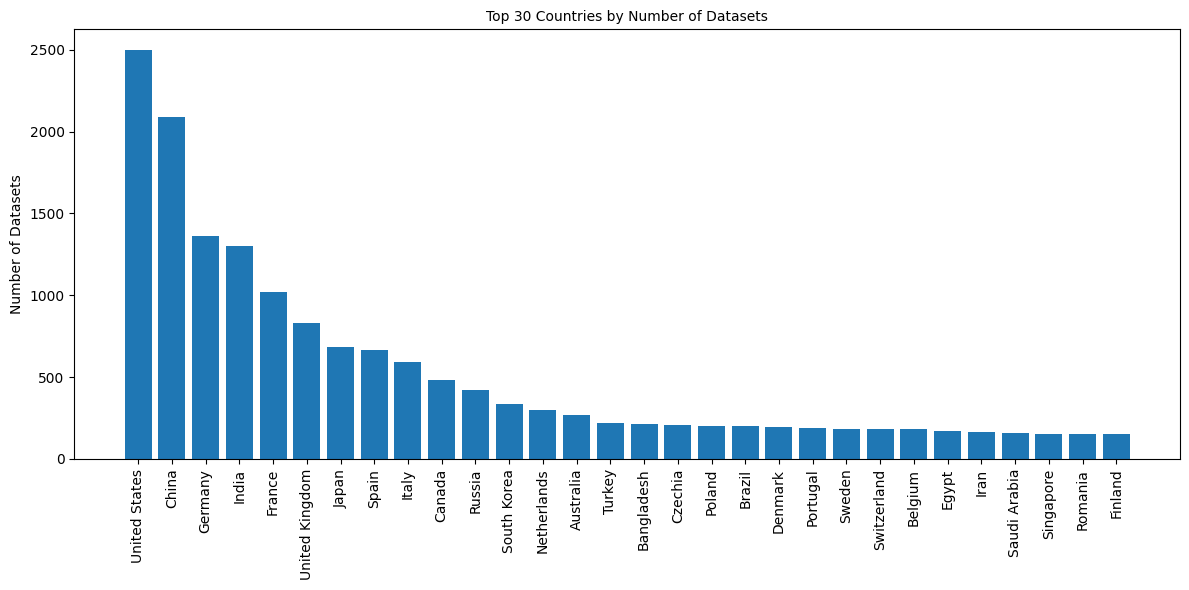

In [53]:
# --- Compute totals ---
country_totals = pivot.sum(axis=1).sort_values(ascending=False)

top30 = country_totals.head(30)

# --- Plot ---
plt.figure(figsize=(12, 6))
plt.bar(top30.index, top30.values)

plt.xticks(rotation=90)
plt.ylabel("Number of Datasets")
plt.title("Top 30 Countries by Number of Datasets")

plt.tight_layout()
plt.show()

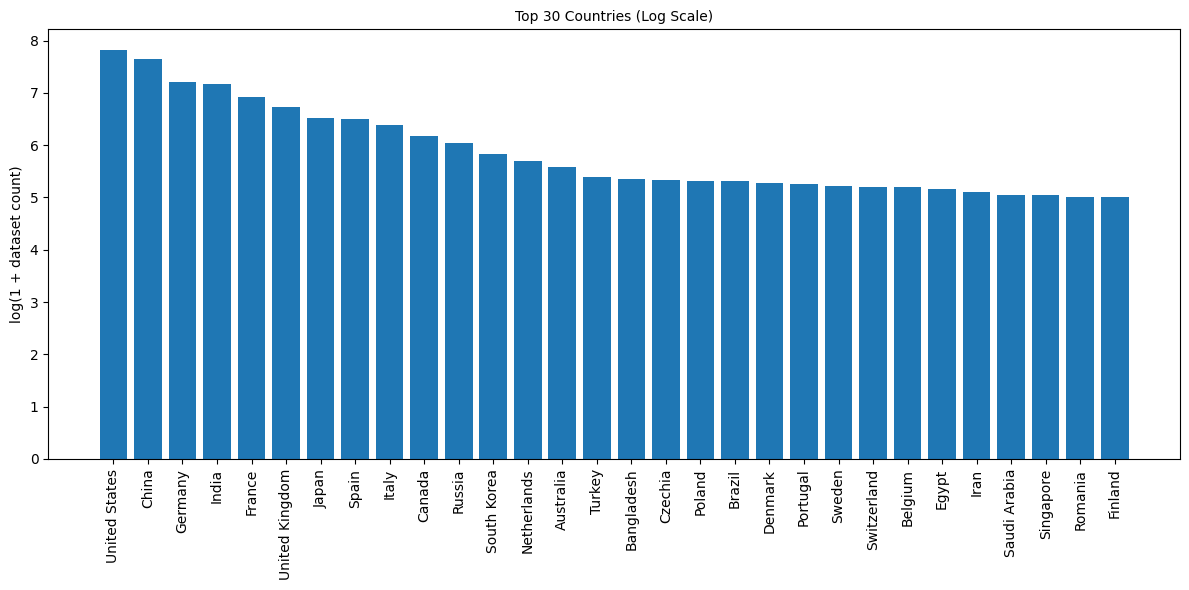

In [54]:
plt.figure(figsize=(12, 6))
plt.bar(top30.index, np.log1p(top30.values))

plt.xticks(rotation=90)
plt.ylabel("log(1 + dataset count)")
plt.title("Top 30 Countries (Log Scale)")

plt.tight_layout()
plt.show()

30 lowest-resources

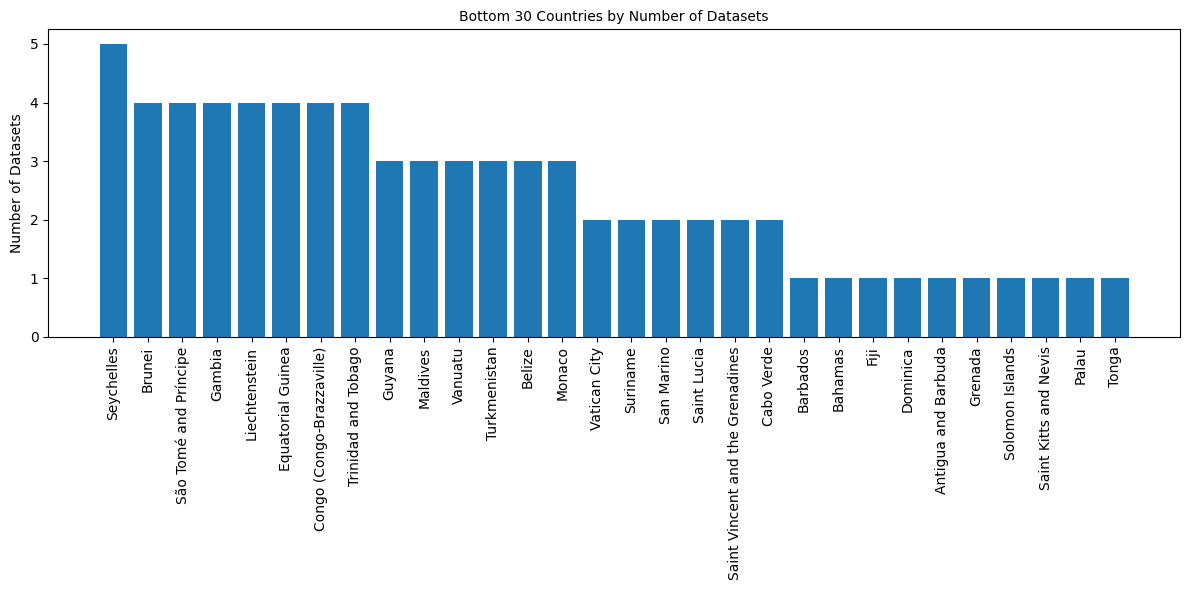

In [55]:
bottom30 = country_totals.tail(30)

plt.figure(figsize=(12, 6))
plt.bar(bottom30.index, bottom30.values)

plt.xticks(rotation=90)
plt.ylabel("Number of Datasets")
plt.title("Bottom 30 Countries by Number of Datasets")

plt.tight_layout()
plt.show()

combined

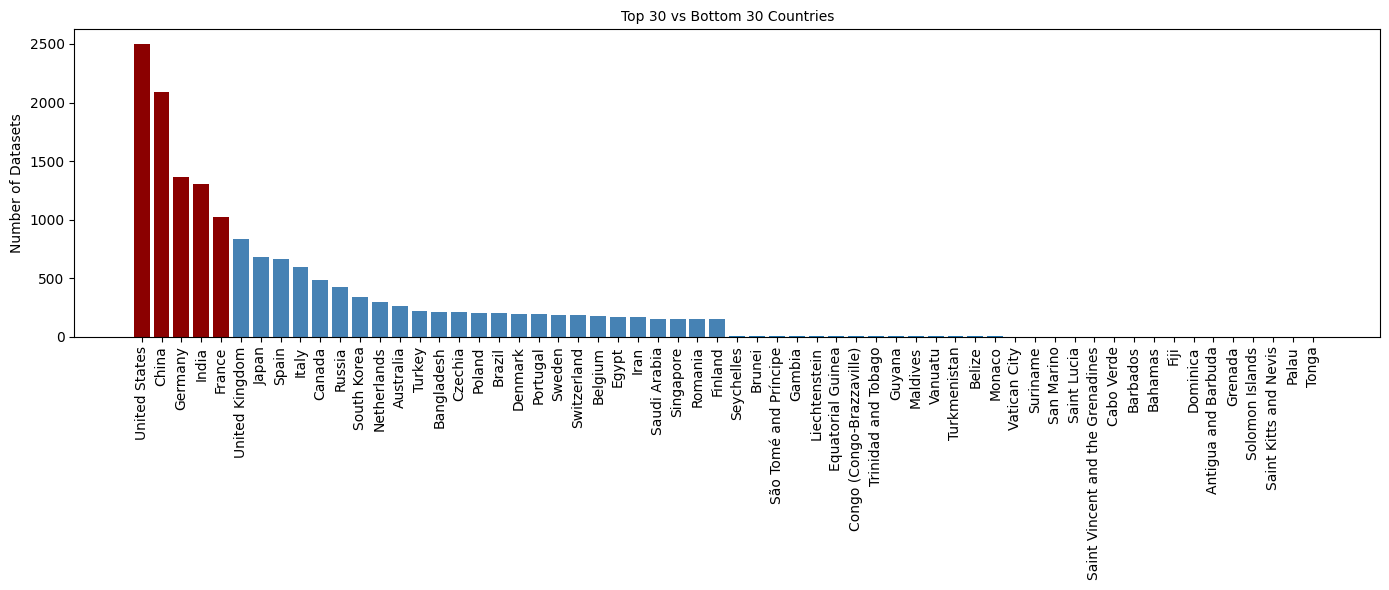

In [56]:
combined = pd.concat([top30, bottom30])

plt.figure(figsize=(14, 6))

# plt.bar(combined.index, np.log1p(combined.values))
# colors = ["darkred" if c in top30.head(5).index else "steelblue" for c in top30.index]
# plt.bar(top30.index, np.log1p(top30.values), color=colors)
# #plt.bar(combined.index, np.log1p(combined.values), color=colors)

plt.bar(combined.index, combined.values)
colors = ["darkred" if c in top30.head(5).index else "steelblue" for c in top30.index]
plt.bar(top30.index, top30.values, color=colors)

plt.xticks(rotation=90)
plt.ylabel("Number of Datasets")
plt.title("Top 30 vs Bottom 30 Countries")

plt.tight_layout()
plt.show()

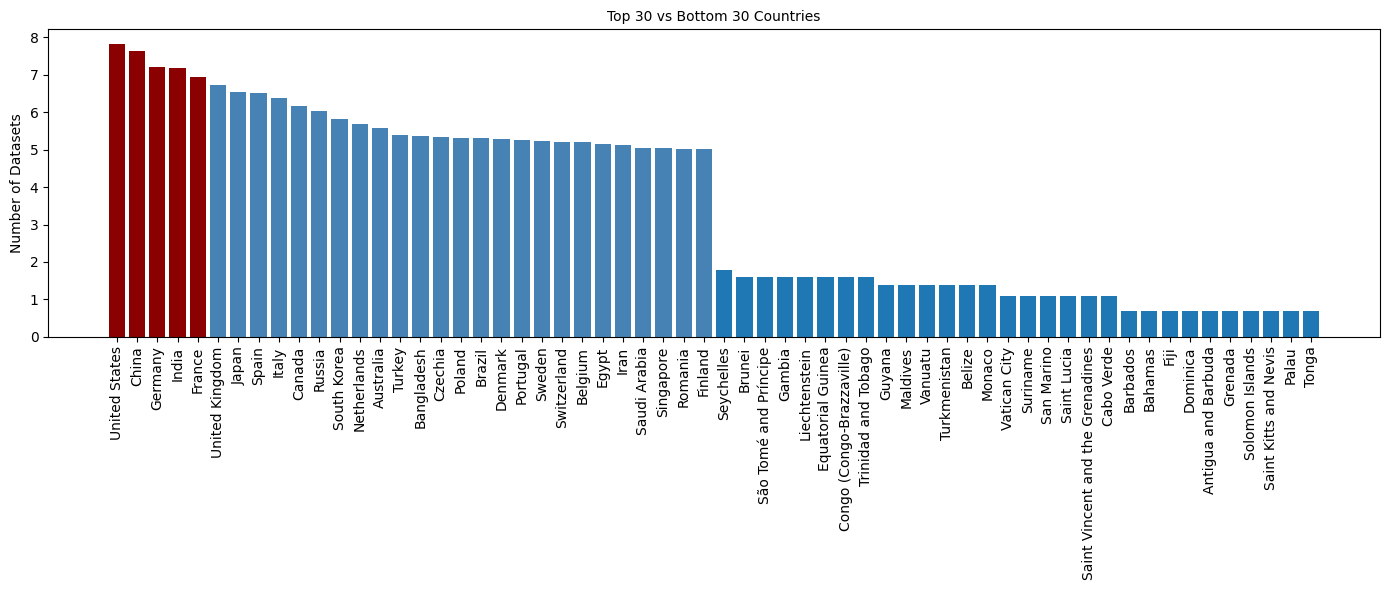

In [57]:
combined = pd.concat([top30, bottom30])

plt.figure(figsize=(14, 6))

plt.bar(combined.index, np.log1p(combined.values))
colors = ["darkred" if c in top30.head(5).index else "steelblue" for c in top30.index]
plt.bar(top30.index, np.log1p(top30.values), color=colors)
#plt.bar(combined.index, np.log1p(combined.values), color=colors)

# plt.bar(combined.index, combined.values)
# colors = ["darkred" if c in top30.head(5).index else "steelblue" for c in top30.index]
# plt.bar(top30.index, top30.values, color=colors)

plt.xticks(rotation=90)
plt.ylabel("Number of Datasets")
plt.title("Top 30 vs Bottom 30 Countries")

plt.tight_layout()
plt.show()

## Key Stats

#### Top country dominance

In [58]:
country_totals = pivot.sum(axis=1).sort_values(ascending=False)

top5_share = country_totals.head(5).sum() / country_totals.sum()
top10_share = country_totals.head(10).sum() / country_totals.sum()

print("Top 5 share:", top5_share)
print("Top 10 share:", top10_share)

Top 5 share: 0.38745318352059926
Top 10 share: 0.5397940074906367


#### US vs the rest

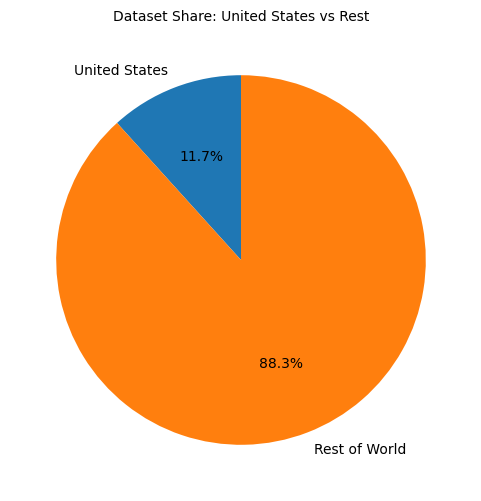

In [59]:
total_datasets = country_totals.sum()
us_count = country_totals["United States"]
rest_count = total_datasets - us_count

labels = ["United States", "Rest of World"]
sizes = [us_count, rest_count]

plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Dataset Share: United States vs Rest")
plt.show()

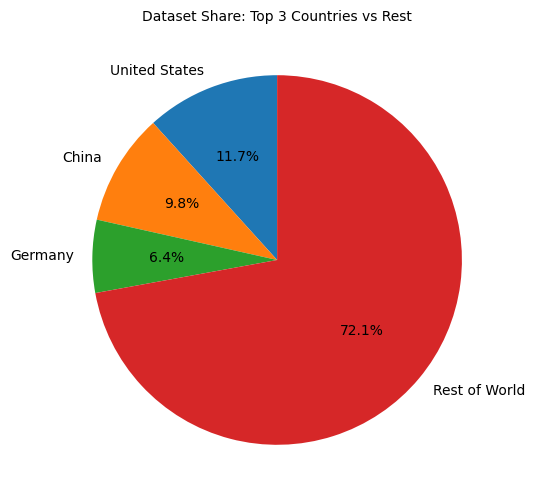

In [60]:
# Top 3 vs rest

top3 = country_totals.head(3)

top3_count = top3.sum()
rest_count = total_datasets - top3_count

labels = list(top3.index) + ["Rest of World"]
sizes = list(top3.values) + [rest_count]

plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Dataset Share: Top 3 Countries vs Rest")
plt.show()

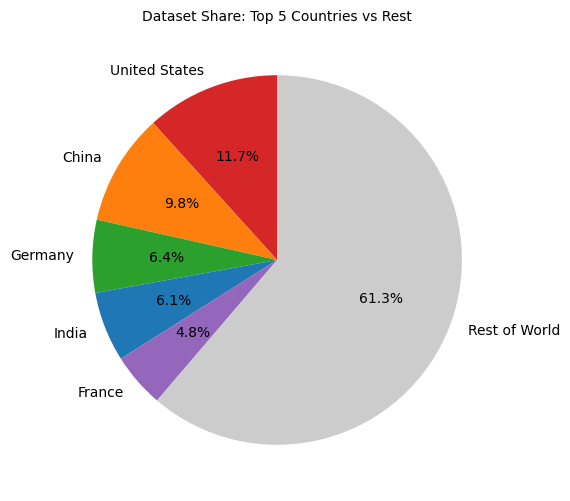

In [61]:
top5 = country_totals.head(5)

top5_count = top5.sum()
rest_count = total_datasets - top5_count

labels = list(top5.index) + ["Rest of World"]
sizes = list(top5.values) + [rest_count]

plt.figure(figsize=(6, 6))

colors = ["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4", "#9467bd", "#cccccc"]

plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors
)
# plt.pie(
#     sizes,
#     labels=labels,
#     autopct='%1.1f%%',
#     startangle=90
# )

plt.title("Dataset Share: Top 5 Countries vs Rest")
plt.savefig('top5_data_share.png')
plt.show()



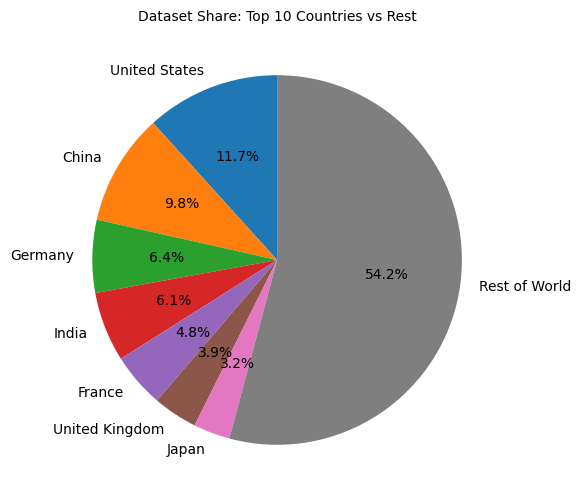

In [62]:
top10 = country_totals.head(7)

top10_count = top10.sum()
rest_count = total_datasets - top10_count

labels = list(top10.index) + ["Rest of World"]
sizes = list(top10.values) + [rest_count]

plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Dataset Share: Top 10 Countries vs Rest")
plt.show()



In [63]:

# Bar chart (top 30)
# Pie chart (top 5 vs rest) 


#### Long-tail distribution

In [64]:
low_1_5 = (country_totals <= 5).sum()
low_10 = (country_totals <= 10).sum()

print("Countries with ≤5 datasets:", low_1_5)
print("Countries with ≤10 datasets:", low_10)

Countries with ≤5 datasets: 34
Countries with ≤10 datasets: 64


#### Countries with zero (sanity check)

In [65]:
valid_countries  = pd.read_csv('/home/jnwatu/Worldbench/compiled_ACL/task_matrix_construction/valid_countries.csv', encoding = 'latin-1')
VALID_COUNTRIES = valid_countries['country'].to_list()

In [66]:

all_countries = set(VALID_COUNTRIES)
present_countries = set(pivot.index)

missing = all_countries - present_countries
print("Missing countries:", missing)

Missing countries: {'Samoa', 'Micronesia', 'Marshall Islands', 'Kiribati', 'Tuvalu', 'Nauru'}


#### Task Distribution

In [67]:
task_totals = pivot.sum(axis=0).sort_values(ascending=False)
print(task_totals.head(10))

Task Category
NLP Applications                                                         4927.0
Information Extraction, Retrieval, and Text Mining                       1855.0
Computational Social Science, Cultural Analytics, NLP for Social Good    1807.0
Machine Translation                                                      1721.0
Dialogue and Interactive Systems                                         1595.0
Natural Language Generation                                              1352.0
Ethics, Bias, and Fairness                                               1222.0
Multimodality and Language Grounding to Vision, Robotics, and Beyond      936.0
Question Answering                                                        890.0
Sentiment Analysis, Stylistic Analysis, and Argument Mining               658.0
dtype: float64


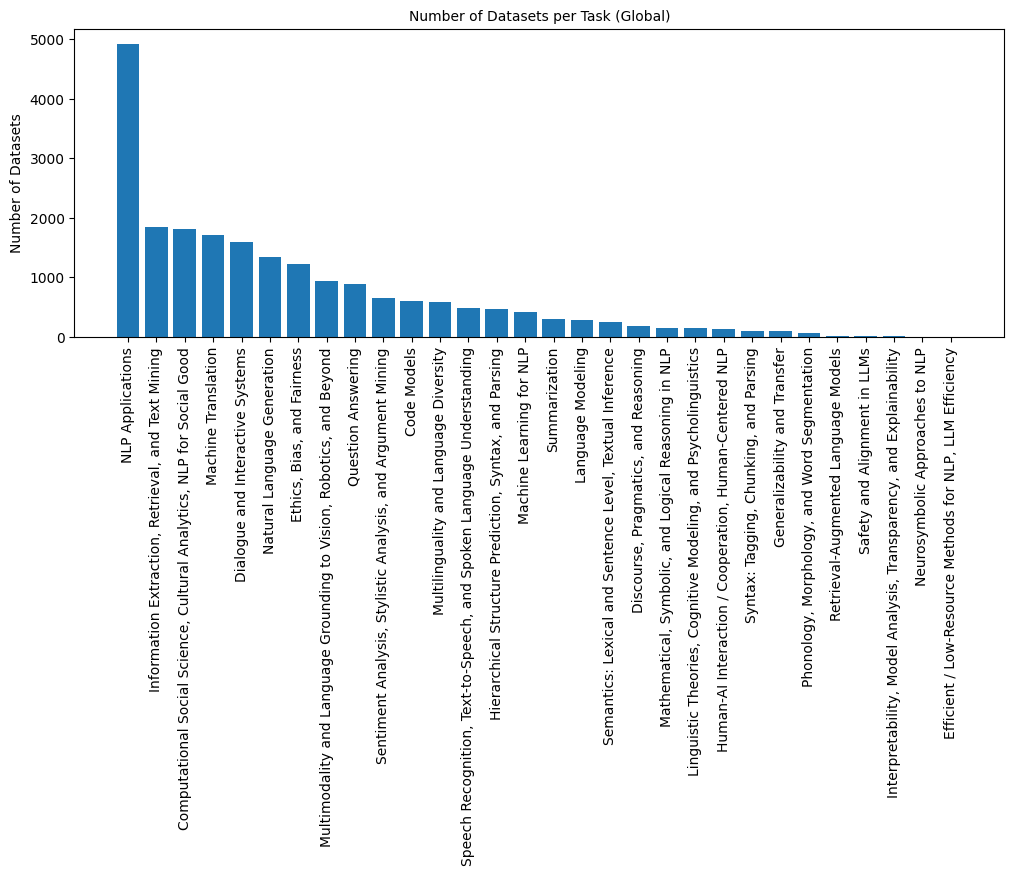

In [68]:


plt.figure(figsize=(12, 4))
plt.bar(task_totals.index, task_totals.values)

plt.xticks(rotation=90)
plt.ylabel("Number of Datasets")
plt.title("Number of Datasets per Task (Global)")

#plt.tight_layout()
plt.savefig('no_of_data_per_task.png')
plt.show()

/tmp/ipykernel_3034639/1484601994.py:12: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


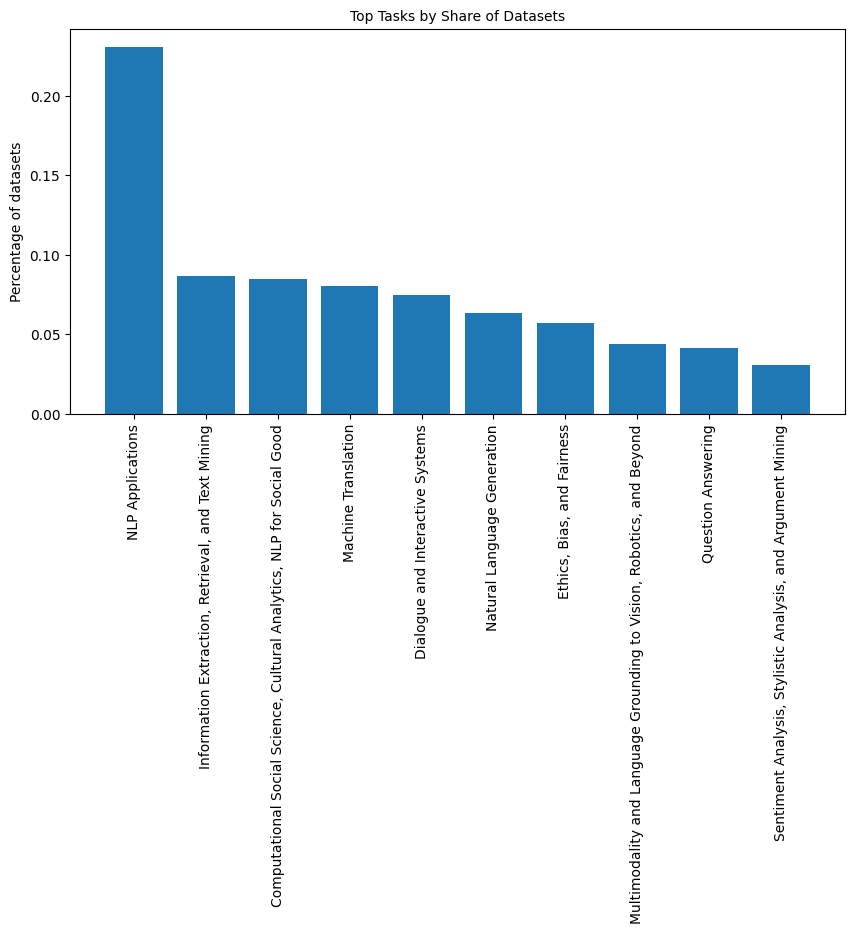

In [69]:
task_percent = task_totals / task_totals.sum()

top_tasks_percent = task_percent.head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_tasks_percent.index, top_tasks_percent.values)

plt.xticks(rotation=90)
plt.ylabel("Percentage of datasets")
plt.title("Top Tasks by Share of Datasets")

plt.tight_layout()
plt.show()

#### Specific Country producers

In [70]:
task_totals = pivot.sum(axis=0).sort_values(ascending=False)

top5_tasks = task_totals.head(5).index
bottom5_tasks = task_totals.tail(5).index

print("Top 5 tasks:", top5_tasks)
print("Bottom 5 tasks:", bottom5_tasks)

Top 5 tasks: Index(['NLP Applications',
       'Information Extraction, Retrieval, and Text Mining',
       'Computational Social Science, Cultural Analytics, NLP for Social Good',
       'Machine Translation', 'Dialogue and Interactive Systems'],
      dtype='str', name='Task Category')
Bottom 5 tasks: Index(['Retrieval-Augmented Language Models', 'Safety and Alignment in LLMs',
       'Interpretability, Model Analysis, Transparency, and Explainability',
       'Neurosymbolic Approaches to NLP',
       'Efficient / Low-Resource Methods for NLP, LLM Efficiency'],
      dtype='str', name='Task Category')


In [71]:
def get_top_countries_for_task(task, k=5):
    return pivot[task].sort_values(ascending=False).head(k)

For the top 5 tasks, which countries contribute the most?

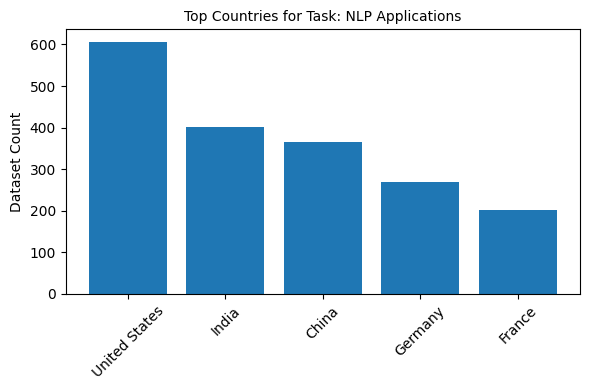

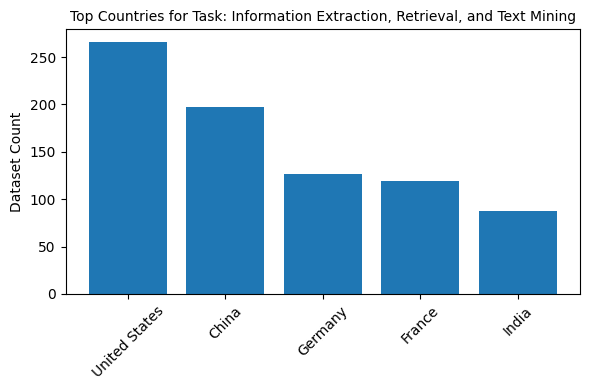

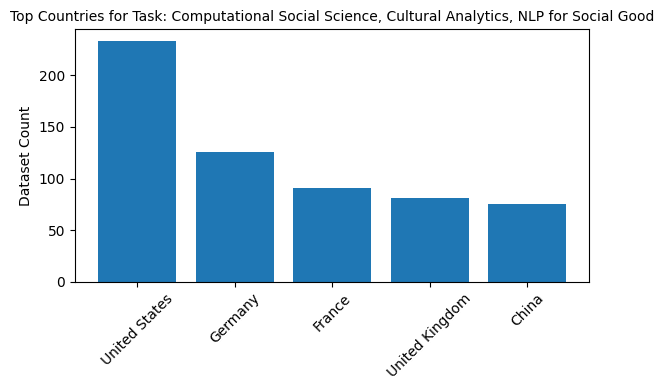

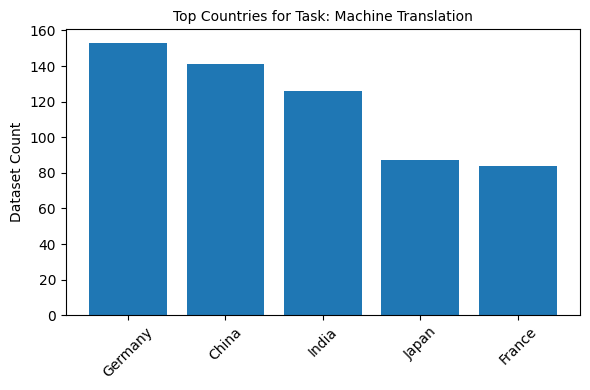

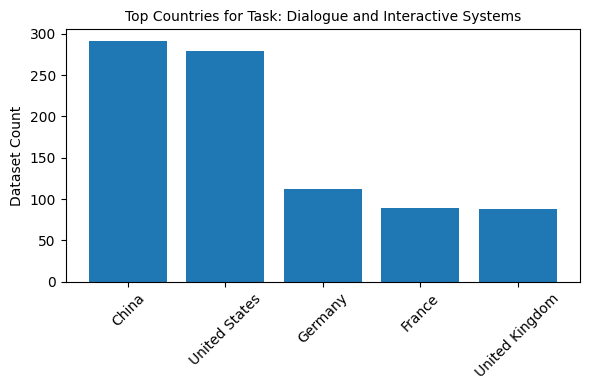

In [72]:
for task in top5_tasks:
    top_countries = get_top_countries_for_task(task)

    plt.figure(figsize=(6, 4))
    plt.bar(top_countries.index, top_countries.values)

    plt.title(f"Top Countries for Task: {task}")
    plt.ylabel("Dataset Count")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

For the bottom 5 tasks, which countries contribute the most?

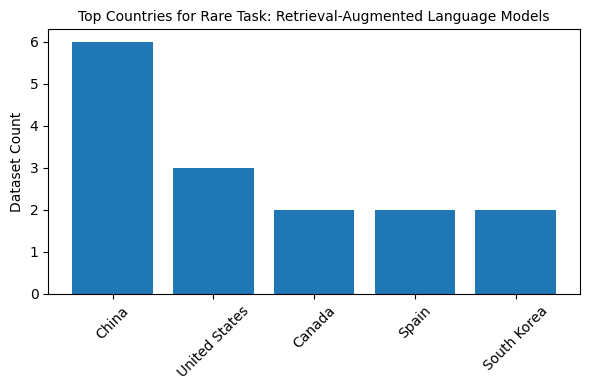

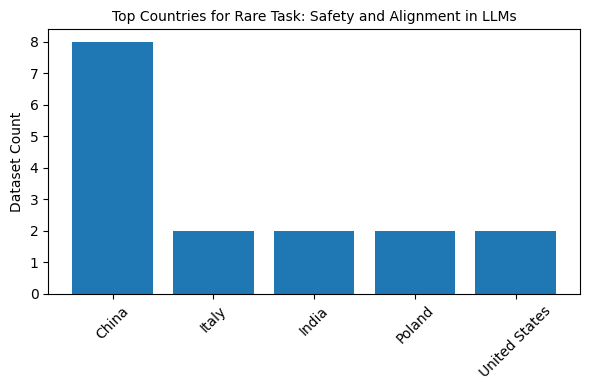

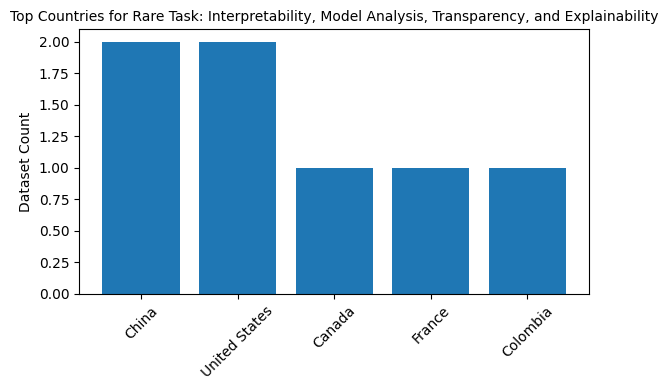

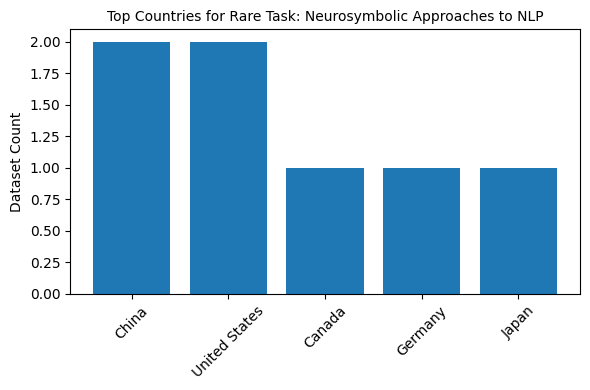

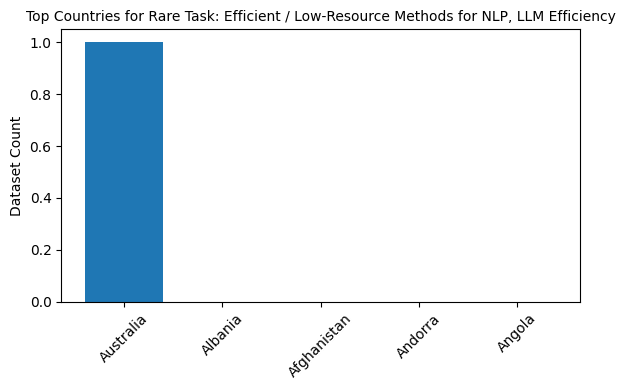

In [73]:
for task in bottom5_tasks:
    top_countries = get_top_countries_for_task(task)

    plt.figure(figsize=(6, 4))
    plt.bar(top_countries.index, top_countries.values)

    plt.title(f"Top Countries for Rare Task: {task}")
    plt.ylabel("Dataset Count")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [74]:
def get_top_country_share_for_task(task, k=5):
    col = pivot[task]
    total = col.sum()
    return (col / total).sort_values(ascending=False).head(k)

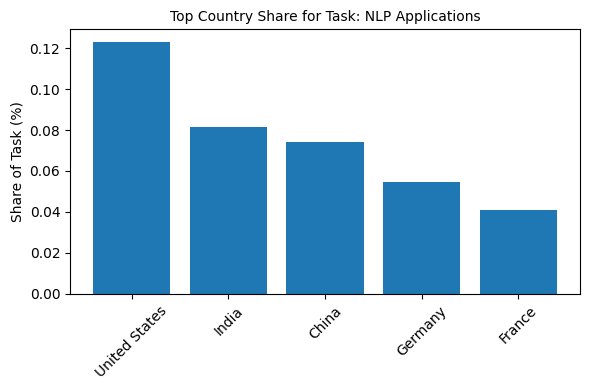

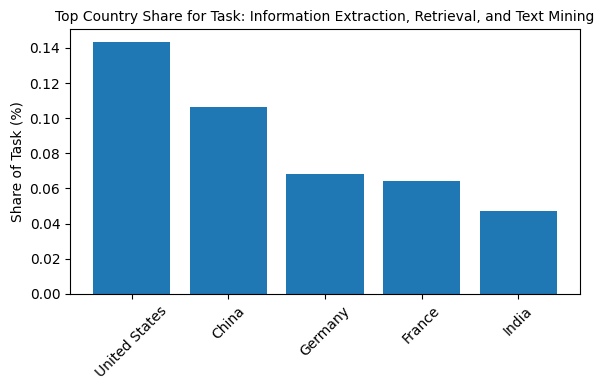

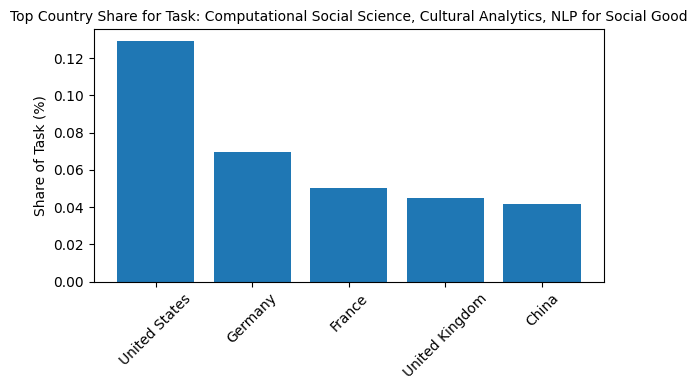

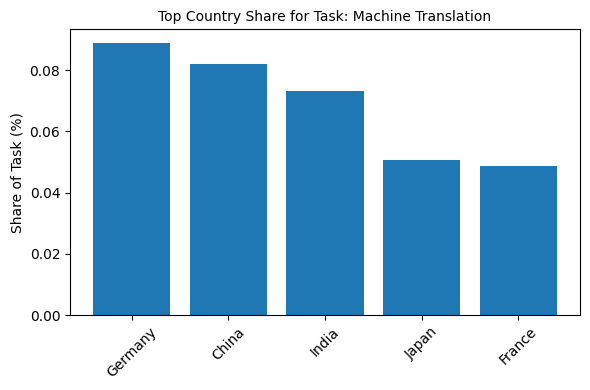

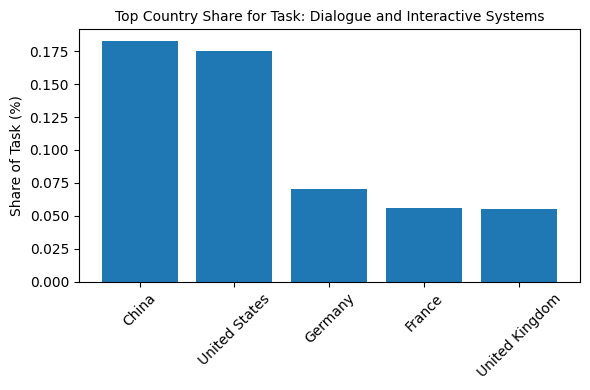

In [75]:




for task in top5_tasks:
    top_countries = get_top_country_share_for_task(task)

    plt.figure(figsize=(6, 4))
    plt.bar(top_countries.index, top_countries.values)

    plt.title(f"Top Country Share for Task: {task}")
    plt.ylabel("Share of Task (%)")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

### How dominated is each task by the top 3 countries? and which countries focus heavily on few tasks (Naive- top 3 share/total for that region)

In [76]:
def task_concentration(task):
    col = pivot[task]
    total = col.sum()
    top3 = col.sort_values(ascending=False).head(3).sum()
    return top3 / total

for task in task_totals.index:
    print(task, task_concentration(task))

NLP Applications 0.27846559772681145
Information Extraction, Retrieval, and Text Mining 0.31805929919137466
Computational Social Science, Cultural Analytics, NLP for Social Good 0.24903154399557278
Machine Translation 0.24404416037187682
Dialogue and Interactive Systems 0.42758620689655175
Natural Language Generation 0.33136094674556216
Ethics, Bias, and Fairness 0.2520458265139116
Multimodality and Language Grounding to Vision, Robotics, and Beyond 0.35149572649572647
Question Answering 0.3595505617977528
Sentiment Analysis, Stylistic Analysis, and Argument Mining 0.22036474164133737
Code Models 0.33444259567387685
Multilinguality and Language Diversity 0.2033898305084746
Speech Recognition, Text-to-Speech, and Spoken Language Understanding 0.20606060606060606
Hierarchical Structure Prediction, Syntax, and Parsing 0.2017167381974249
Machine Learning for NLP 0.3333333333333333
Summarization 0.3536977491961415
Language Modeling 0.16842105263157894
Semantics: Lexical and Sentence Level, 

In [77]:
task_list = [task for task in task_totals.index]
task_conc = [task_concentration(task) for task in task_totals.index]

df_task_conc = pd.DataFrame()
df_task_conc["task"] = task_list
df_task_conc["top3_share"] = task_conc

In [78]:
print(df_task_conc)

                                                 task  top3_share
0                                    NLP Applications    0.278466
1   Information Extraction, Retrieval, and Text Mi...    0.318059
2   Computational Social Science, Cultural Analyti...    0.249032
3                                 Machine Translation    0.244044
4                    Dialogue and Interactive Systems    0.427586
5                         Natural Language Generation    0.331361
6                          Ethics, Bias, and Fairness    0.252046
7   Multimodality and Language Grounding to Vision...    0.351496
8                                  Question Answering    0.359551
9   Sentiment Analysis, Stylistic Analysis, and Ar...    0.220365
10                                        Code Models    0.334443
11             Multilinguality and Language Diversity    0.203390
12  Speech Recognition, Text-to-Speech, and Spoken...    0.206061
13  Hierarchical Structure Prediction, Syntax, and...    0.201717
14        

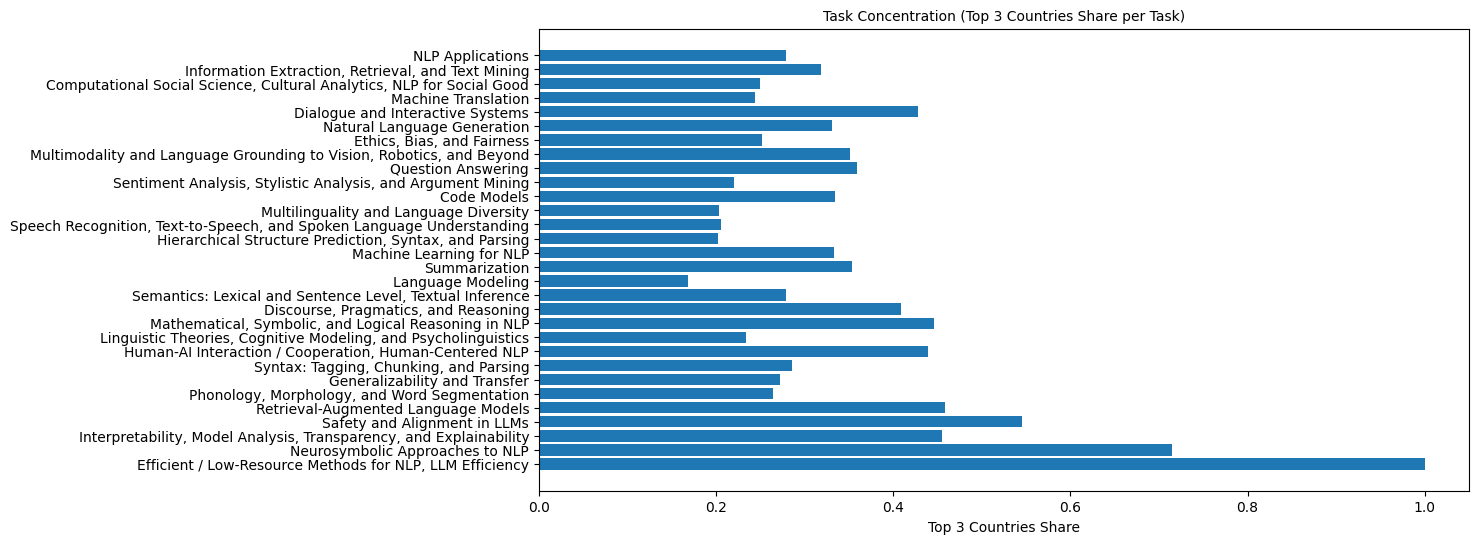

In [79]:

plt.figure(figsize=(12, 6))
plt.barh(df_task_conc["task"], df_task_conc["top3_share"])
plt.xlabel("Top 3 Countries Share")
plt.title("Task Concentration (Top 3 Countries Share per Task)")
plt.gca().invert_yaxis()
plt.show()

In [80]:
def country_concentration(country, k=3):
    row = pivot.loc[country]
    total = row.sum()
    topk = row.sort_values(ascending=False).head(k).sum()
    return topk / total if total > 0 else 0

In [81]:
country_conc = []

for country in pivot.index:
    conc = country_concentration(country)
    country_conc.append((country, conc))

df_country_conc = pd.DataFrame(country_conc, columns=["country", "top3_task_share"])
df_country_conc = df_country_conc.sort_values("top3_task_share", ascending=False)

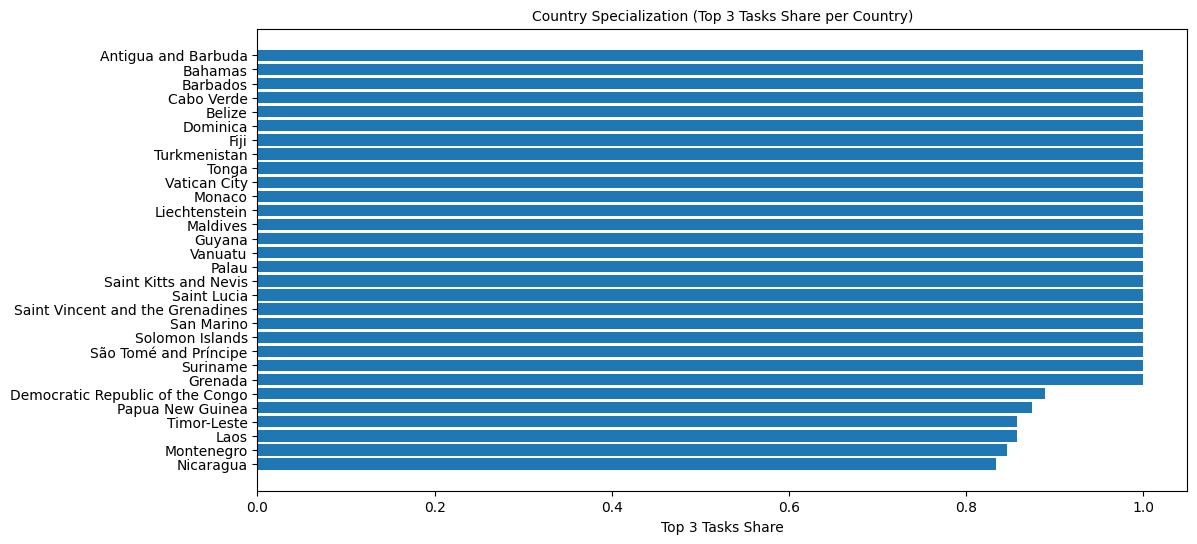

In [82]:
## Specialists

plt.figure(figsize=(12, 6))
plt.barh(df_country_conc["country"].head(30), df_country_conc["top3_task_share"].head(30))
plt.xlabel("Top 3 Tasks Share")
plt.title("Country Specialization (Top 3 Tasks Share per Country)")
plt.gca().invert_yaxis()
plt.show()

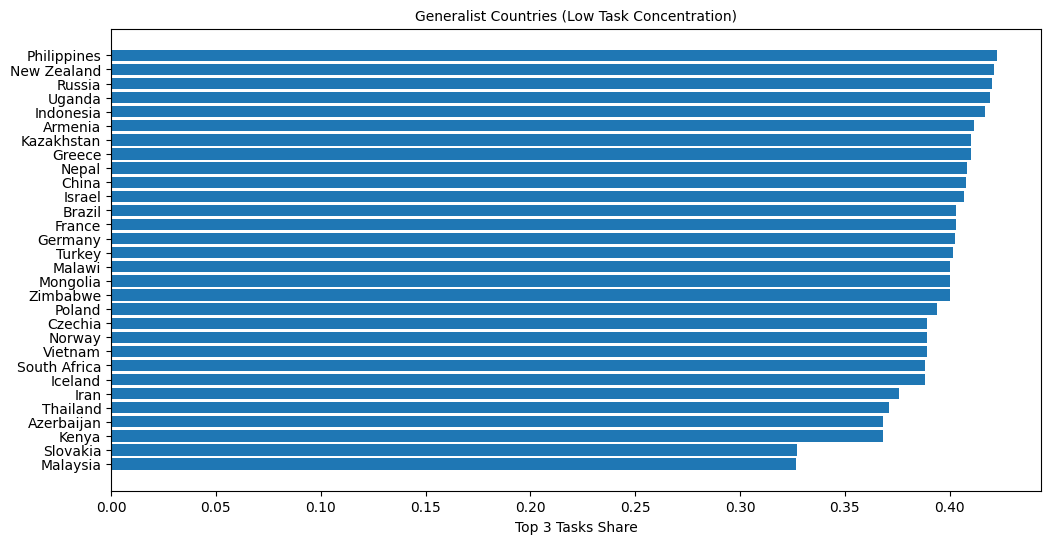

In [83]:
# Generalists

plt.figure(figsize=(12, 6))
plt.barh(df_country_conc["country"].tail(30), df_country_conc["top3_task_share"].tail(30))
plt.xlabel("Top 3 Tasks Share")
plt.title("Generalist Countries (Low Task Concentration)")
plt.gca().invert_yaxis()
plt.show()

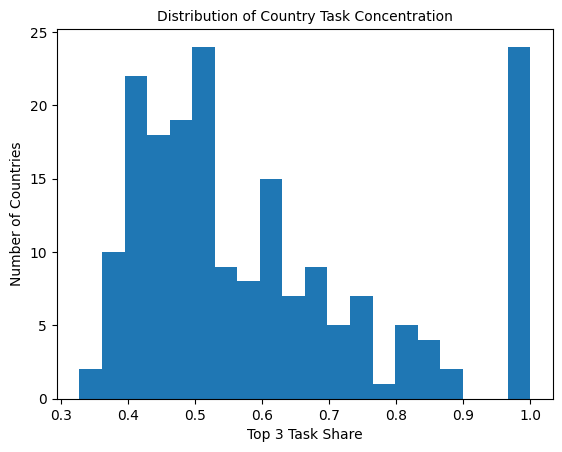

In [84]:

plt.hist(df_country_conc["top3_task_share"], bins=20)
plt.title("Distribution of Country Task Concentration")
plt.xlabel("Top 3 Task Share")
plt.ylabel("Number of Countries")
plt.show()

### Using Entropy 
(to avoid being conditioned by the number of datasets for the country)



In [85]:
def normalized_entropy(row):
    total = row.sum()
    if total == 0:
        return np.nan

    p = row[row > 0] / total
    entropy = -(p * np.log(p)).sum()

    # normalize by max possible entropy given number of task categories
    max_entropy = np.log(len(row))
    return entropy / max_entropy if max_entropy > 0 else np.nan

country_entropy = pivot.apply(normalized_entropy, axis=1)

df_country_entropy = pd.DataFrame({
    "country": pivot.index,
    "normalized_entropy": country_entropy,
    "total_datasets": pivot.sum(axis=1)
}).sort_values("normalized_entropy", ascending=False)

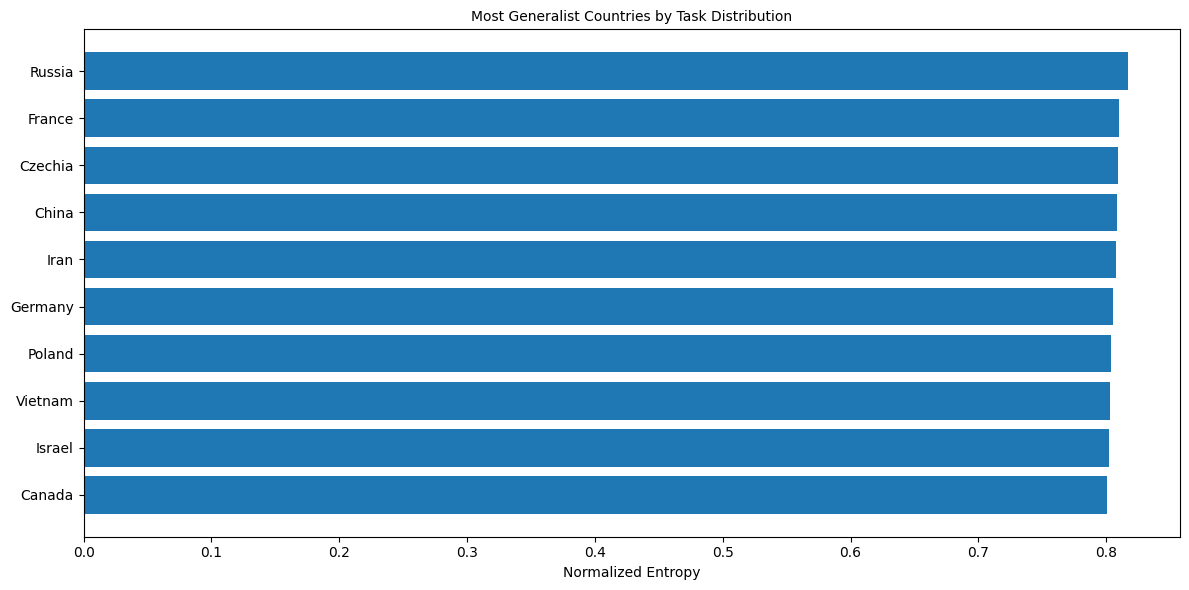

In [86]:
#Generalists

top_generalists = df_country_entropy.head(10)

plt.figure(figsize=(12, 6))
plt.barh(top_generalists["country"], top_generalists["normalized_entropy"])
plt.xlabel("Normalized Entropy")
plt.title("Most Generalist Countries by Task Distribution")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

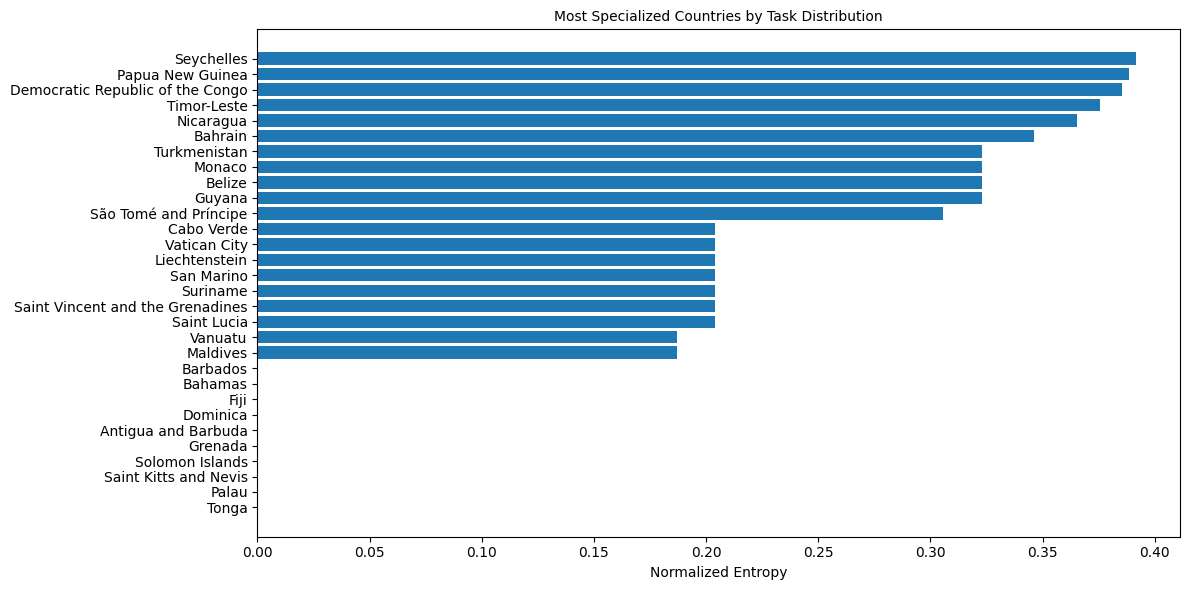

In [87]:
top_specialists = df_country_entropy.tail(30)

plt.figure(figsize=(12, 6))
plt.barh(top_specialists["country"], top_specialists["normalized_entropy"])
plt.xlabel("Normalized Entropy")
plt.title("Most Specialized Countries by Task Distribution")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [88]:
## HHI - Simpson
# high HHI → specialist
# low HHI → generalist

def hhi_concentration(row):
    total = row.sum()
    if total == 0:
        return np.nan
    p = row / total
    return (p ** 2).sum()

country_hhi = pivot.apply(hhi_concentration, axis=1)

df_country_hhi = pd.DataFrame({
    "country": pivot.index,
    "hhi": country_hhi,
    "total_datasets": pivot.sum(axis=1)
}).sort_values("hhi", ascending=False)

In [89]:
df_country_hhi.head(20)

,country,hhi,total_datasets
content_country,,,
Antigua and Barbuda,Antigua and Barbuda,1.000000,1.0
Bahamas,Bahamas,1.000000,1.0
Barbados,Barbados,1.000000,1.0
Dominica,Dominica,1.000000,1.0
Fiji,Fiji,1.000000,1.0
Solomon Islands,Solomon Islands,1.000000,1.0
Grenada,Grenada,1.000000,1.0
Palau,Palau,1.000000,1.0
Saint Kitts and Nevis,Saint Kitts and Nevis,1.000000,1.0


In [90]:
#larger number = more generalist
#smaller number = more specialized


def effective_num_tasks(row):
    total = row.sum()
    if total == 0:
        return np.nan
    p = row / total
    hhi = (p ** 2).sum()
    return 1 / hhi if hhi > 0 else np.nan

country_eff_tasks = pivot.apply(effective_num_tasks, axis=1)

df_country_eff = pd.DataFrame({
    "country": pivot.index,
    "effective_tasks": country_eff_tasks,
    "total_datasets": pivot.sum(axis=1)
}).sort_values("effective_tasks", ascending=False)


In [91]:

df_country_eff.head(10)

,country,effective_tasks,total_datasets
content_country,,,
Slovakia,Slovakia,13.209607,55.0
Vietnam,Vietnam,12.590609,131.0
Malaysia,Malaysia,12.403670,52.0
Iceland,Iceland,12.298630,67.0
Czechia,Czechia,11.938190,208.0
South Africa,South Africa,11.932355,121.0
Norway,Norway,11.856082,113.0
China,China,11.589047,2091.0
Greece,Greece,11.480095,139.0


In [92]:
## Entorpy bubble plot


def normalized_entropy(row):
    total = row.sum()
    if total == 0:
        return np.nan

    p = row[row > 0] / total
    entropy = -(p * np.log(p)).sum()
    max_entropy = np.log(len(row))

    return entropy / max_entropy if max_entropy > 0 else np.nan

country_entropy = pivot.apply(normalized_entropy, axis=1)
country_totals = pivot.sum(axis=1)

df_plot = pd.DataFrame({
    "country": pivot.index,
    "entropy": country_entropy,
    "total_datasets": country_totals
}).dropna()

In [93]:
df_plot = df_plot[df_plot["total_datasets"] >= 10]  # adjust threshold if needed

In [94]:
pivot.head()

Task Category,Code Models,"Computational Social Science, Cultural Analytics, NLP for Social Good",Dialogue and Interactive Systems,"Discourse, Pragmatics, and Reasoning","Efficient / Low-Resource Methods for NLP, LLM Efficiency","Ethics, Bias, and Fairness",Generalizability and Transfer,"Hierarchical Structure Prediction, Syntax, and Parsing","Human-AI Interaction / Cooperation, Human-Centered NLP","Information Extraction, Retrieval, and Text Mining",...,Neurosymbolic Approaches to NLP,"Phonology, Morphology, and Word Segmentation",Question Answering,Retrieval-Augmented Language Models,Safety and Alignment in LLMs,"Semantics: Lexical and Sentence Level, Textual Inference","Sentiment Analysis, Stylistic Analysis, and Argument Mining","Speech Recognition, Text-to-Speech, and Spoken Language Understanding",Summarization,"Syntax: Tagging, Chunking, and Parsing"
content_country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,2.0,2.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0
Albania,0.0,2.0,0.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,1.0
Algeria,3.0,3.0,4.0,0.0,0.0,4.0,0.0,1.0,0.0,2.0,...,0.0,0.0,1.0,0.0,0.0,3.0,12.0,6.0,1.0,1.0
Andorra,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
Angola,0.0,2.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Rich gets richer

In [95]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr, pearsonr

# --------------------------------------------------
# 1. Keep rows with valid years
# --------------------------------------------------

df_time = df_expanded.copy()

df_time = df_time[
    df_time["Year created"].notna()
].copy()

df_time["Year created"] = pd.to_numeric(
    df_time["Year created"],
    errors="coerce"
)

df_time = df_time[
    df_time["Year created"].notna()
]

# --------------------------------------------------
# 2. Split into early / later periods
# --------------------------------------------------

split_year = 2018

early = df_time[df_time["Year created"] <= split_year]
later = df_time[df_time["Year created"] > split_year]

# --------------------------------------------------
# 3. Country-task counts
# --------------------------------------------------

early_counts = (
    early
    .groupby(["content_country", "Task Category"])
    .size()
    .reset_index(name="early_count")
)

later_counts = (
    later
    .groupby(["content_country", "Task Category"])
    .size()
    .reset_index(name="later_count")
)

# --------------------------------------------------
# 4. Merge
# --------------------------------------------------

growth_df = early_counts.merge(
    later_counts,
    on=["content_country", "Task Category"],
    how="outer"
).fillna(0)

# --------------------------------------------------
# 5. Country totals in early period
# --------------------------------------------------

country_early_totals = (
    early
    .groupby("content_country")
    .size()
    .rename("country_early_total")
)

growth_df = growth_df.merge(
    country_early_totals,
    on="content_country",
    how="left"
)

# --------------------------------------------------
# 6. Early task share
# --------------------------------------------------

growth_df["early_share"] = (
    growth_df["early_count"]
    / growth_df["country_early_total"]
)

# --------------------------------------------------
# 7. Log growth
# --------------------------------------------------

growth_df["log_growth"] = (
    np.log1p(growth_df["later_count"])
    - np.log1p(growth_df["early_count"])
)

# --------------------------------------------------
# 8. Threshold
# --------------------------------------------------

growth_df = growth_df[
    growth_df["early_count"] >= 3
].copy()

print(growth_df.head())

print("Rows:", len(growth_df))

# --------------------------------------------------
# 9. Correlations
# --------------------------------------------------

pearson_corr, pearson_p = pearsonr(
    growth_df["early_share"],
    growth_df["log_growth"]
)

spearman_corr, spearman_p = spearmanr(
    growth_df["early_share"],
    growth_df["log_growth"]
)

print("\nPearson:", pearson_corr, "p=", pearson_p)
print("Spearman:", spearman_corr, "p=", spearman_p)

# --------------------------------------------------
# 10. Quartile analysis
# --------------------------------------------------

growth_df["share_quartile"] = pd.qcut(
    growth_df["early_share"],
    4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

quartile_summary = (
    growth_df
    .groupby("share_quartile")["log_growth"]
    .agg(["mean", "median", "count"])
)

print("\nQuartile summary:")
print(quartile_summary)

   content_country                                      Task Category  \
60       Argentina                                   NLP Applications   
80       Australia  Computational Social Science, Cultural Analyti...   
88       Australia  Information Extraction, Retrieval, and Text Mi...   
95       Australia                                   NLP Applications   
98       Australia                                 Question Answering   

    early_count  later_count  country_early_total  early_share  log_growth  
60          4.0         13.0                  8.0     0.500000    1.029619  
80          4.0         24.0                 34.0     0.117647    1.609438  
88          8.0         26.0                 34.0     0.235294    1.098612  
95          6.0         51.0                 34.0     0.176471    2.005334  
98          5.0         13.0                 34.0     0.147059    0.847298  
Rows: 219

Pearson: -0.12060033764885886 p= 0.07491007722784938
Spearman: -0.09769178015083715 p= 0

In [96]:
# --------------------------------------------------
# 1. Keep rows with valid years
# --------------------------------------------------

df_time = df_expanded.copy()

df_time = df_time[
    df_time["Year created"].notna()
].copy()

df_time["Year created"] = pd.to_numeric(
    df_time["Year created"],
    errors="coerce"
)

df_time = df_time[
    df_time["Year created"].notna()
]

# --------------------------------------------------
# 2. Split into early / later periods
# --------------------------------------------------

split_year = 2022

early = df_time[df_time["Year created"] <= split_year]
later = df_time[df_time["Year created"] > split_year]

# --------------------------------------------------
# 3. Country-task counts
# --------------------------------------------------

early_counts = (
    early
    .groupby(["content_country", "Task Category"])
    .size()
    .reset_index(name="early_count")
)

later_counts = (
    later
    .groupby(["content_country", "Task Category"])
    .size()
    .reset_index(name="later_count")
)

# --------------------------------------------------
# 4. Build pivot tables
# --------------------------------------------------

early_pivot = early_counts.pivot(
    index="content_country",
    columns="Task Category",
    values="early_count"
).fillna(0)

later_pivot = later_counts.pivot(
    index="content_country",
    columns="Task Category",
    values="later_count"
).fillna(0)


# --------------------------------------------------
# 5. Compute specialization metrics
# --------------------------------------------------

def compute_metrics(pivot):
    total = pivot.sum(axis=1)
    top3 = pivot.apply(lambda row: row.sort_values(ascending=False).head(3).sum(), axis=1)
    
    top3_share = top3 / total.replace(0, np.nan)
    task_breadth = (pivot > 0).sum(axis=1)
    
    return pd.DataFrame({
        "total": total,
        "top3_share": top3_share,
        "task_breadth": task_breadth
    })

early_metrics = compute_metrics(early_pivot)
later_metrics = compute_metrics(later_pivot)


# --------------------------------------------------
# 6. Filter countries with enough data
# --------------------------------------------------

min_datasets = 10

valid_countries = (
    (early_metrics["total"] >= min_datasets) &
    (later_metrics["total"] >= min_datasets)
)

early_metrics = early_metrics[valid_countries]
later_metrics = later_metrics[valid_countries]


# --------------------------------------------------
# 7. Classify specialist vs generalist
# --------------------------------------------------

def classify(df):
    return np.where(df["top3_share"] >= 0.6, "Specialist", "Generalist")

early_metrics["type_early"] = classify(early_metrics)
later_metrics["type_later"] = classify(later_metrics)


# --------------------------------------------------
# 8. Merge and compute transitions
# --------------------------------------------------

transitions = pd.DataFrame({
    "type_early": early_metrics["type_early"],
    "type_later": later_metrics["type_later"]
})

transition_counts = transitions.value_counts().reset_index(name="count")

print(transition_counts)


# --------------------------------------------------
# 9. Key statistic: Specialist → Generalist
# --------------------------------------------------

num_spec_to_gen = transitions[
    (transitions["type_early"] == "Specialist") &
    (transitions["type_later"] == "Generalist")
].shape[0]

num_total_spec = (transitions["type_early"] == "Specialist").sum()

print(f"Specialist → Generalist: {num_spec_to_gen} / {num_total_spec}")


   type_early  type_later  count
0  Generalist  Generalist     60
1  Specialist  Generalist     22
2  Specialist  Specialist      8
3  Generalist  Specialist      2
Specialist → Generalist: 22 / 30


/tmp/ipykernel_3034639/792947905.py:96: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  early_metrics = early_metrics[valid_countries]
/tmp/ipykernel_3034639/792947905.py:97: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  later_metrics = later_metrics[valid_countries]


In [97]:
quartile_summary

,mean,median,count
share_quartile,,,
Q1,1.444341,1.446919,57
Q2,1.389369,1.488077,55
Q3,1.236727,1.419564,52
Q4,1.239102,1.299283,55


In [98]:
growth_df.head(25)

,content_country,Task Category,early_count,later_count,country_early_total,early_share,log_growth,share_quartile
60,Argentina,NLP Applications,4.0,13.0,8.0,0.500000,1.029619,Q4
80,Australia,"Computational Social Science, Cultural Analyti...",4.0,24.0,34.0,0.117647,1.609438,Q3
88,Australia,"Information Extraction, Retrieval, and Text Mi...",8.0,26.0,34.0,0.235294,1.098612,Q4
95,Australia,NLP Applications,6.0,51.0,34.0,0.176471,2.005334,Q3
98,Australia,Question Answering,5.0,13.0,34.0,0.147059,0.847298,Q3
177,Belgium,"Computational Social Science, Cultural Analyti...",4.0,13.0,44.0,0.090909,1.029619,Q2
182,Belgium,"Information Extraction, Retrieval, and Text Mi...",7.0,17.0,44.0,0.159091,0.810930,Q3
189,Belgium,Multimodality and Language Grounding to Vision...,5.0,3.0,44.0,0.113636,-0.405465,Q3
190,Belgium,NLP Applications,11.0,35.0,44.0,0.250000,1.098612,Q4
191,Belgium,Natural Language Generation,5.0,9.0,44.0,0.113636,0.510826,Q3


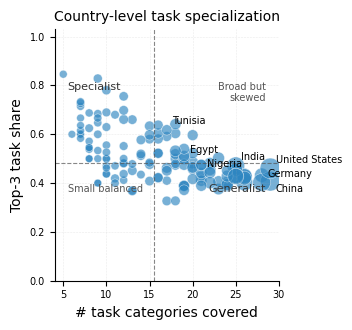

Most generalist countries:
            country  dataset_count  task_breadth  top3_share
24            China         2091.0            29    0.407939
126   United States         2500.0            29    0.460400
42          Germany         1361.0            28    0.402645
22           Canada          481.0            28    0.432432
40           France         1020.0            26    0.402941
98           Russia          421.0            26    0.420428
55            Japan          684.0            26    0.426901
54            Italy          593.0            26    0.430017
80      Netherlands          296.0            25    0.425676
125  United Kingdom          831.0            25    0.427196

Most specialist countries:
                    country  dataset_count  task_breadth  top3_share
74               Montenegro           13.0             5    0.846154
9                   Bahrain           35.0             9    0.828571
87                     Oman           41.0            10    0.78048

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# Country-level task portfolio metrics from pivot
# --------------------------------------------------

min_datasets = 10

task_totals = pivot.sum(axis=1)
pivot_filt = pivot.loc[task_totals >= min_datasets].copy()

task_breadth = (pivot_filt > 0).sum(axis=1)

top3_share = pivot_filt.apply(
    lambda row: row.sort_values(ascending=False).head(3).sum() / row.sum()
    if row.sum() > 0 else np.nan,
    axis=1
)

plot_df = pd.DataFrame({
    "country": pivot_filt.index,
    "dataset_count": pivot_filt.sum(axis=1),
    "task_breadth": task_breadth,
    "top3_share": top3_share
}).reset_index(drop=True)

# --------------------------------------------------
# Regime thresholds
# --------------------------------------------------

breadth_med = plot_df["task_breadth"].median()
concentration_med = plot_df["top3_share"].median()

# --------------------------------------------------
# Bubble sizes
# --------------------------------------------------

sizes = 18 + 4.0 * np.sqrt(plot_df["dataset_count"])

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(3.6, 3.4))

ax.scatter(
    plot_df["task_breadth"],
    plot_df["top3_share"],
    s=sizes,
    alpha=0.65,
    color="#2E86C1",
    edgecolor="white",
    linewidth=0.4
)

# Threshold lines
ax.axvline(
    breadth_med,
    color="#555555",
    linestyle="--",
    linewidth=0.8,
    alpha=0.7
)

ax.axhline(
    concentration_med,
    color="#555555",
    linestyle="--",
    linewidth=0.8,
    alpha=0.7
)

# Quadrant labels
x_min, x_max = plot_df["task_breadth"].min(), plot_df["task_breadth"].max()
y_min, y_max = plot_df["top3_share"].min(), plot_df["top3_share"].max()

ax.text(
    x_max - 0.5,
    y_min + 0.03,
    "Generalist",
    ha="right",
    va="bottom",
    fontsize=8,
    color="#333333"
)

ax.text(
    x_min + 0.5,
    y_max - 0.03,
    "Specialist",
    ha="left",
    va="top",
    fontsize=8,
    color="#333333"
)

ax.text(
    x_max - 0.5,
    y_max - 0.03,
    "Broad but\nskewed",
    ha="right",
    va="top",
    fontsize=7,
    color="#555555"
)

ax.text(
    x_min + 0.5,
    y_min + 0.03,
    "Small balanced",
    ha="left",
    va="bottom",
    fontsize=7,
    color="#555555"
)

# Annotate selected countries
annotate_countries = [
    "United States",
    "China",
    "India",
    "Germany",
    "Nigeria",
    "Egypt",
    "Tunisia"
]

offsets = {
    "United States": (4, 4),
    "China": (4, -8),
    "India": (4, 4),
    "Germany": (4, 4),
    "Nigeria": (4, 4),
    "Egypt": (4, 4),
    "Tunisia": (4, 4),
}

for country in annotate_countries:
    row = plot_df[plot_df["country"] == country]
    if row.empty:
        continue

    row = row.iloc[0]
    ax.annotate(
        country,
        xy=(row["task_breadth"], row["top3_share"]),
        xytext=offsets.get(country, (4, 4)),
        textcoords="offset points",
        fontsize=7
    )

# Labels
ax.set_xlabel("# task categories covered")
ax.set_ylabel("Top-3 task share")
ax.set_title("Country-level task specialization", fontsize=10)

# Axis limits
ax.set_ylim(0, 1.03)
ax.set_xlim(x_min - 1, x_max + 1)

# Clean style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(
    linestyle="--",
    linewidth=0.4,
    alpha=0.25
)

ax.tick_params(axis="both", labelsize=7)

plt.tight_layout()

plt.savefig("fig_country_task_specialization.pdf", bbox_inches="tight")
plt.savefig("fig_country_task_specialization.png", dpi=300, bbox_inches="tight")

plt.show()

# Optional: inspect extremes
print("Most generalist countries:")
print(plot_df.sort_values(["task_breadth", "top3_share"], ascending=[False, True]).head(10))

print("\nMost specialist countries:")
print(plot_df.sort_values(["top3_share", "task_breadth"], ascending=[False, True]).head(10))

In [100]:
plot_df[plot_df['country'] == 'Egypt']

,country,dataset_count,task_breadth,top3_share
36,Egypt,172.0,19,0.5


In [101]:
plot_df[plot_df['country'] == 'Tunisia']

,country,dataset_count,task_breadth,top3_share
120,Tunisia,89.0,17,0.617978


In [102]:
specialists = plot_df.sort_values(
    "top3_share",
    ascending=False
).head(15)["country"]

for country in specialists:
    top_tasks = (
        pivot.loc[country]
        .sort_values(ascending=False)
        .head(3)
    )

    print(country)
    print(top_tasks)

Montenegro
Task Category
Computational Social Science, Cultural Analytics, NLP for Social Good    4.0
NLP Applications                                                         4.0
Multimodality and Language Grounding to Vision, Robotics, and Beyond     3.0
Name: Montenegro, dtype: float64
Bahrain
Task Category
NLP Applications                    25.0
Ethics, Bias, and Fairness           2.0
Dialogue and Interactive Systems     2.0
Name: Bahrain, dtype: float64
Oman
Task Category
NLP Applications                    25.0
Ethics, Bias, and Fairness           4.0
Dialogue and Interactive Systems     3.0
Name: Oman, dtype: float64
Kuwait
Task Category
NLP Applications                    28.0
Ethics, Bias, and Fairness           3.0
Dialogue and Interactive Systems     3.0
Name: Kuwait, dtype: float64
Mozambique
Task Category
Sentiment Analysis, Stylistic Analysis, and Argument Mining              6.0
Machine Translation                                                      3.0
Computational S

In [103]:
import plotly.express as px
import numpy as np

plot_df = df_plot.copy()

# Remove invalid values for log scale
plot_df = plot_df[plot_df["total_datasets"] > 0]

# Optional: remove very tiny countries
plot_df = plot_df[plot_df["total_datasets"] >= 10]

# Bubble size scaling
plot_df["bubble_size"] = (plot_df["total_datasets"] ** 0.7) * 3

fig = px.scatter(
    plot_df,
    x="total_datasets",
    y="entropy",
    size="bubble_size",
    hover_name="country",
    hover_data={
        "total_datasets": True,
        "entropy": ':.3f',
        "bubble_size": False
    },
    log_x=True,
    title="Country Specialization vs Dataset Scale",
    labels={
        "total_datasets": "Total Number of Datasets",
        "entropy": "Normalized Entropy (Task Diversity)"
    }
)

fig.update_traces(marker=dict(line=dict(width=0.5, color="black"), opacity=0.7))

fig.update_layout(
    width=900,
    height=600
)

fig.show()

In [104]:
plot_df["continent"] = plot_df["country"].map(country2continent)
plot_df["income"] = plot_df["country"].map(country2income)
plot_df["num_universities"] = plot_df["country"].map(country2unis)

In [105]:
fig = px.scatter(
    plot_df,
    x="total_datasets",
    y="entropy",
    size="bubble_size",
    color="continent",
    hover_name="country",
    hover_data={
        "income": True,
        "num_universities": True,
        "total_datasets": True,
        "entropy": ':.3f'
    },
    log_x=True
)

fig.show()

In [106]:

fig = px.scatter(
    plot_df,
    x="total_datasets",
    y="entropy",
    size="bubble_size",
    color="income",
    hover_name="country",
    hover_data={
        "continent": True,
        "num_universities": True,
        "total_datasets": True,
        "entropy": ':.3f'
    },
    log_x=True
)

fig.show()

In [107]:
reg_df = plot_df.copy()

reg_df["num_universities"] = pd.to_numeric(reg_df["num_universities"], errors="coerce")
reg_df["total_datasets"] = pd.to_numeric(reg_df["total_datasets"], errors="coerce")

reg_df = reg_df[
    reg_df["num_universities"].notna() &
    reg_df["total_datasets"].notna() &
    (reg_df["num_universities"] > 0) &
    (reg_df["total_datasets"] > 0)
].copy()

In [108]:
import plotly.express as px

fig = px.scatter(
    reg_df,
    x="num_universities",
    y="total_datasets",
    color="income",
    hover_name="country",
    hover_data={
        "num_universities": True,
        "total_datasets": True,
        "income": True
    },
    trendline="ols",
    log_x=True,
    log_y=True,
    title="Number of Universities vs Dataset Count",
    labels={
        "num_universities": "Number of Universities",
        "total_datasets": "Total Number of Datasets",
        "income": "Income Level"
    }
)

fig.update_traces(marker=dict(size=10, opacity=0.75, line=dict(width=0.5, color="black")))
fig.update_layout(width=900, height=600)

fig.show()

ModuleNotFoundError: No module named 'statsmodels'

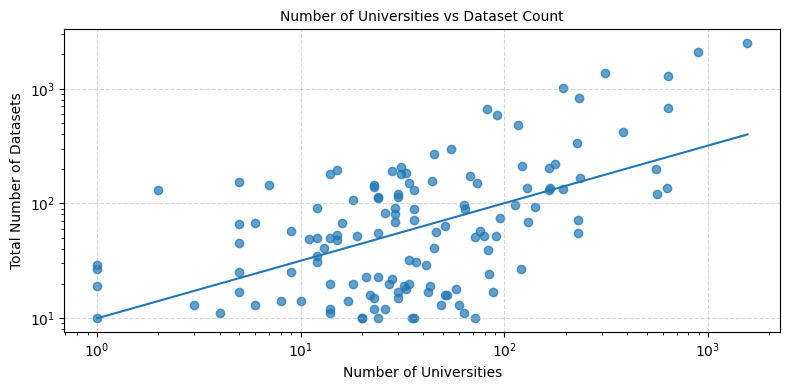

In [109]:
import matplotlib.pyplot as plt
import numpy as np

x = np.log10(reg_df["num_universities"])
y = np.log10(reg_df["total_datasets"])

# Fit line in log-log space
coef = np.polyfit(x, y, 1)
fit_fn = np.poly1d(coef)

plt.figure(figsize=(8, 4))
plt.scatter(reg_df["num_universities"], reg_df["total_datasets"], alpha=0.7)

x_line = np.linspace(reg_df["num_universities"].min(), reg_df["num_universities"].max(), 200)
y_line = 10 ** fit_fn(np.log10(x_line))

plt.plot(x_line, y_line)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Universities")
plt.ylabel("Total Number of Datasets")
plt.title("Number of Universities vs Dataset Count")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("Uni_vs_data.png")
plt.show()

In [110]:
from scipy.stats import spearmanr, pearsonr
import numpy as np

x = np.log10(reg_df["num_universities"])
y = np.log10(reg_df["total_datasets"])

pearson_corr, pearson_p = pearsonr(x, y)
spearman_corr, spearman_p = spearmanr(reg_df["num_universities"], reg_df["total_datasets"])

print("Pearson correlation on log-log values:", pearson_corr, "p=", pearson_p)
print("Spearman correlation:", spearman_corr, "p=", spearman_p)

Pearson correlation on log-log values: 0.5469803705969263 p= 8.040610782213012e-12
Spearman correlation: 0.4684816720332897 p= 1.1397489889894512e-08


Pearson (log–log) ≈ 0.55
→ a moderate positive linear relationship after accounting for scale.
Interpretation: countries with more universities tend to have more datasets, but the relationship is far from deterministic.
Spearman ≈ 0.47
→ a moderate monotonic relationship (rank-based).
Interpretation: higher-ranked countries in university count tend to be higher in dataset count, but with plenty of reordering.
p-values ~ 1e-8 to 1e-12
→ statistically significant, but that’s expected with ~100–200 countries. Don’t overemphasize p-values; emphasize effect size.

Clean takeaway
There is a moderate positive association between national research infrastructure (proxied by number of universities) and dataset production, but substantial variance indicates that infrastructure alone does not explain global dataset distribution.

In [111]:


x = np.log10(reg_df["num_universities"])
y = np.log10(reg_df["total_datasets"])

coef = np.polyfit(x, y, 1)
fit_fn = np.poly1d(coef)

# predicted values
y_pred = fit_fn(x)

# residuals
reg_df["residual"] = y - y_pred

In [112]:
overperformers = reg_df.sort_values("residual", ascending=False).head(10)
underperformers = reg_df.sort_values("residual", ascending=True).head(10)

print("Overperformers:")
print(overperformers[["country", "num_universities", "total_datasets", "residual"]])

print("\nUnderperformers:")
print(underperformers[["country", "num_universities", "total_datasets", "residual"]])

Overperformers:
                        country  num_universities  total_datasets  residual
content_country                                                            
Qatar                     Qatar                 2           131.0  0.968981
Germany                 Germany               312          1361.0  0.883830
Spain                     Spain                82           665.0  0.864333
France                   France               193          1020.0  0.863363
Singapore             Singapore                 5           155.0  0.842132
China                     China               897          2091.0  0.839924
United States     United States              1561          2500.0  0.796637
Italy                     Italy                92           593.0  0.789461
Israel                   Israel                 7           145.0  0.739760
United Kingdom   United Kingdom               232           831.0  0.734209

Underperformers:
                       country  num_universities  tota

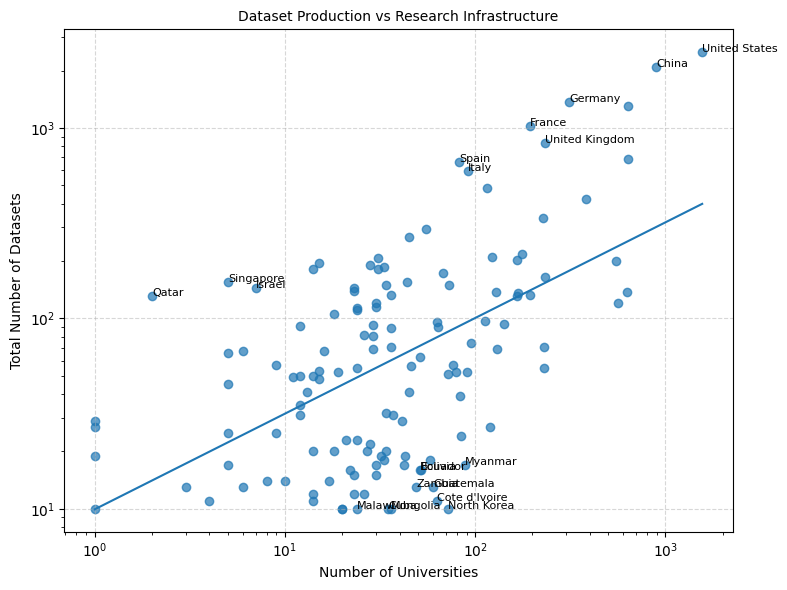

In [113]:


plt.figure(figsize=(8, 6))

plt.scatter(
    reg_df["num_universities"],
    reg_df["total_datasets"],
    alpha=0.7
)

# fitted line
x_line = np.linspace(reg_df["num_universities"].min(), reg_df["num_universities"].max(), 200)
y_line = 10 ** fit_fn(np.log10(x_line))
plt.plot(x_line, y_line)

# label outliers
for _, row in overperformers.iterrows():
    plt.text(row["num_universities"], row["total_datasets"], row["country"], fontsize=8)

for _, row in underperformers.iterrows():
    plt.text(row["num_universities"], row["total_datasets"], row["country"], fontsize=8)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Universities")
plt.ylabel("Total Number of Datasets")
plt.title("Dataset Production vs Research Infrastructure")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

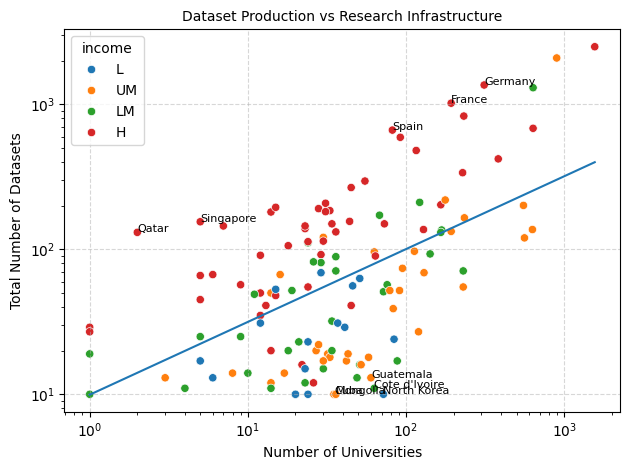

In [114]:
sns.scatterplot(
    data=reg_df,
    x="num_universities",
    y="total_datasets",
    hue="income"
)

# sizes = (reg_df["total_datasets"] ** 0.6) * 10

# sns.scatterplot(
#     reg_df["num_universities"],
#     reg_df["total_datasets"],
#     s=sizes,
#     c=reg_df["income"].map({
#         "H": "red",
#         "UM": "orange",
#         "LM": "green",
#         "L": "blue"
#     }),
#     alpha=0.7
# )

# fitted line
x_line = np.linspace(reg_df["num_universities"].min(), reg_df["num_universities"].max(), 200)
y_line = 10 ** fit_fn(np.log10(x_line))
plt.plot(x_line, y_line)

top_outliers = reg_df.sort_values("residual", ascending=False).head(5)
bottom_outliers = reg_df.sort_values("residual").head(5)

for _, row in top_outliers.iterrows():
    plt.text(row["num_universities"], row["total_datasets"], row["country"], fontsize=8)

for _, row in bottom_outliers.iterrows():
    plt.text(row["num_universities"], row["total_datasets"], row["country"], fontsize=8)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Universities")
plt.ylabel("Total Number of Datasets")
plt.title("Dataset Production vs Research Infrastructure")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("uni_vs_producer_data.png")
plt.show()

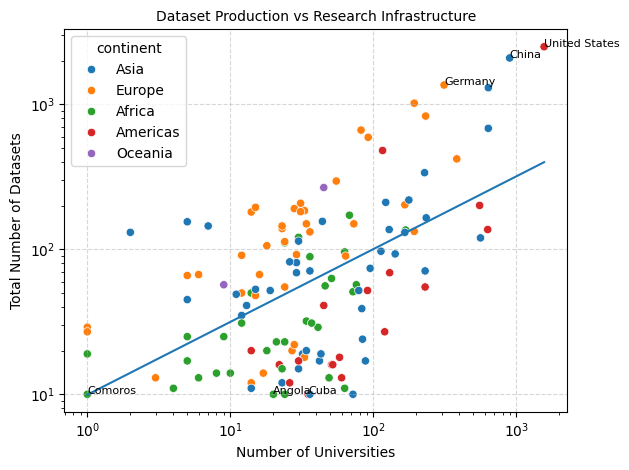

In [115]:
sns.scatterplot(
    data=reg_df,
    x="num_universities",
    y="total_datasets",
    hue="continent"
)

# sizes = (reg_df["total_datasets"] ** 0.6) * 10

# sns.scatterplot(
#     reg_df["num_universities"],
#     reg_df["total_datasets"],
#     s=sizes,
#     c=reg_df["income"].map({
#         "H": "red",
#         "UM": "orange",
#         "LM": "green",
#         "L": "blue"
#     }),
#     alpha=0.7
# )

# fitted line
x_line = np.linspace(reg_df["num_universities"].min(), reg_df["num_universities"].max(), 200)
y_line = 10 ** fit_fn(np.log10(x_line))
plt.plot(x_line, y_line)

top_outliers = reg_df.sort_values("total_datasets", ascending=False).head(3)
bottom_outliers = reg_df.sort_values("total_datasets").head(3)


# top countries by dataset count
for _, row in top_outliers.iterrows():
    plt.text(row["num_universities"], row["total_datasets"], row["country"], fontsize=8)

for _, row in bottom_outliers.iterrows():
    plt.text(row["num_universities"], row["total_datasets"], row["country"], fontsize=8)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Universities")
plt.ylabel("Total Number of Datasets")
plt.title("Dataset Production vs Research Infrastructure")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


1. Infrastructure matters, but only moderately
correlation ≈ 0.5
wide variance
2. Income stratification dominates
high-income countries systematically above trend
low-income countries below
3. Efficiency gap
Countries with similar numbers of universities produce vastly different numbers of datasets.

## Producer Countries vs Content Countries

In [116]:
import ast
import re
import pandas as pd

def safe_parse_list(x):
    if isinstance(x, list):
        return x
    if pd.isna(x):
        return []
    try:
        parsed = ast.literal_eval(x)
        return parsed if isinstance(parsed, list) else []
    except Exception:
        return []

def normalize_country_token(token):
    if token is None:
        return None

    s = str(token).strip()
    s = re.sub(r"\s+", " ", s)

    alias_map = {
        # US
        "USA": "United States",
        "US": "United States",
        "U.S.": "United States",
        "U.S.A.": "United States",
        "United States of America": "United States",

        # UK
        "UK": "United Kingdom",
        "U.K.": "United Kingdom",
        "England": "United Kingdom",
        "Scotland": "United Kingdom",
        "Wales": "United Kingdom",

        # Korea
        "Korea": "South Korea",
        "Republic of Korea": "South Korea",
        "Korea, South": "South Korea",
        "Korea, North": "North Korea",

        # China
        "P.R. China": "China",
        "Mainland China": "China",
        "Hong Kong": "China",
        "Macao": "China",

        # Europe cleanup
        "Czech Republic": "Czechia",
        "Slovak Republic": "Slovakia",

        # Africa / others
        "Ivory Coast": "Cote d'Ivoire",
        "Côte d’Ivoire": "Cote d'Ivoire",
        "Sao Tome and Principe": "São Tomé and Príncipe",

        # Middle East
        "UAE": "United Arab Emirates",

        # Already discussed
        "Viet Nam": "Vietnam",
        "Sultanate of Oman": "Oman",
        "State of Kuwait": "Kuwait",
        "Republic of Guyana": "Guyana",
    }

    return alias_map.get(s, s)

df = df_expanded.copy()

def normalize_producer_list(lst):
    cleaned = []
    for c in lst:
        c = normalize_country_token(c)
        if c and c in VALID_COUNTRIES:
            cleaned.append(c)
    return list(dict.fromkeys(cleaned))

# Parse stringified lists into real lists
df["producer_country_list"] = df["producer_country_list"].apply(safe_parse_list)

# Normalize and filter
df["producer_country_list"] = df["producer_country_list"].apply(normalize_producer_list)

# Flatten to inspect unique producer countries
producer_series = df["producer_country_list"].explode().dropna()
all_producers = sorted(producer_series.unique())

invalid_remaining = [c for c in all_producers if c not in VALID_COUNTRIES]

print("Number of unique producer countries:", len(all_producers))
print("Invalid remaining:", invalid_remaining)

Number of unique producer countries: 120
Invalid remaining: []


In [117]:
producer_series.head()

0          Japan
1        Germany
2        Germany
3          India
3    South Korea
Name: producer_country_list, dtype: str

## Figure 3

In [118]:
import numpy as np
import matplotlib.pyplot as plt

# Keep only rows with usable producer/content country info
plot_df = df.copy()

plot_df = plot_df[
    plot_df["content_country"].notna() &
    plot_df["producer_country_list"].map(len).gt(0)
].copy()

# -----------------------------
# 1. Content self-representation
# -----------------------------
# For a given content country C:
# among datasets about C, what fraction are produced by C itself?

plot_df["content_is_self"] = plot_df.apply(
    lambda row: row["content_country"] in row["producer_country_list"],
    axis=1
)

content_summary = (
    plot_df.groupby("content_country")
    .agg(
        content_self=("content_is_self", "mean"),
        content_count=("content_country", "size")
    )
    .reset_index()
    .rename(columns={"content_country": "country"})
)

# -----------------------------
# 2. Producer self-representation
# -----------------------------
# Explode producers so each row is one (dataset, content_country, producer_country)

prod_df = plot_df.explode("producer_country_list").rename(
    columns={"producer_country_list": "producer_country"}
)

prod_df = prod_df[prod_df["producer_country"].notna()].copy()

# For a given producer country P:
# among datasets produced by P, what fraction are about P itself?

prod_df["producer_is_self"] = (
    prod_df["producer_country"] == prod_df["content_country"]
)

producer_summary = (
    prod_df.groupby("producer_country")
    .agg(
        producer_self=("producer_is_self", "mean"),
        producer_count=("producer_country", "size")
    )
    .reset_index()
    .rename(columns={"producer_country": "country"})
)

# -----------------------------
# 3. Merge into one country-level table
# -----------------------------
country_compare = content_summary.merge(
    producer_summary,
    on="country",
    how="inner"
)

# Optional: add income / continent / university metadata if you already have mappings
if "country2income" in globals():
    country_compare["income"] = country_compare["country"].map(country2income)
if "country2continent" in globals():
    country_compare["continent"] = country_compare["country"].map(country2continent)
if "country2unis" in globals():
    country_compare["num_universities"] = country_compare["country"].map(country2unis)

print(country_compare.shape)
country_compare.head()

(120, 8)


,country,content_self,content_count,producer_self,producer_count,income,continent,num_universities
0,Albania,0.100000,20,0.125000,16,UM,Europe,27
1,Algeria,0.086022,93,0.250000,32,UM,Africa,63
2,Argentina,0.179104,67,0.184615,65,UM,Americas,130
3,Armenia,0.117647,17,0.500000,4,UM,Asia,42
4,Australia,0.460076,263,0.266520,454,H,Oceania,45


In [126]:
country_compare

,country,content_self,content_count,producer_self,producer_count,income,continent,num_universities
0,Albania,0.100000,20,0.125000,16,UM,Europe,27
1,Algeria,0.086022,93,0.250000,32,UM,Africa,63
2,Argentina,0.179104,67,0.184615,65,UM,Americas,130
3,Armenia,0.117647,17,0.500000,4,UM,Asia,42
4,Australia,0.460076,263,0.266520,454,H,Oceania,45
...,...,...,...,...,...,...,...,...
115,Uruguay,0.631579,19,0.226415,53,H,Americas,14
116,Uzbekistan,0.250000,20,0.500000,10,LM,Asia,34
117,Vietnam,0.465116,129,0.535714,112,LM,Asia,166
118,Yemen,0.018868,53,0.052632,19,L,Asia,15


In [119]:
# Top producer countries and their shares (new cell)
# Uses existing `producer_summary` or falls back to `prod_df`
if 'producer_summary' in globals():
    summary = producer_summary.copy()
else:
    summary = prod_df.groupby('producer_country').size().reset_index(name='producer_count')

# Normalize column names
if 'producer_count' not in summary.columns:
    cols = summary.columns.tolist()
    if len(cols) >= 2:
        summary = summary.rename(columns={cols[0]: 'country', cols[1]: 'producer_count'})
    else:
        raise ValueError("Unable to find producer count column in summary")

if 'country' not in summary.columns and 'producer_country' in summary.columns:
    summary = summary.rename(columns={'producer_country': 'country'})

summary = summary[['country', 'producer_count']].sort_values('producer_count', ascending=False).reset_index(drop=True)
total_prod = summary['producer_count'].sum()

top5_producers = summary.head(5).copy()
top10_producers = summary.head(10).copy()

top5_producers['share'] = top5_producers['producer_count'] / total_prod
top10_producers['share'] = top10_producers['producer_count'] / total_prod

top5_producers['share_pct'] = (top5_producers['share'] * 100).round(2)
top10_producers['share_pct'] = (top10_producers['share'] * 100).round(2)

print("Total producer records:", int(total_prod))
print("\nTop 5 producers:")
print(top5_producers[['country', 'producer_count', 'share_pct']].to_string(index=False))

print("\nCumulative top 5 share: {:.2f}%".format(top5_producers['share'].sum() * 100))

print("\nTop 10 producers:")
print(top10_producers[['country', 'producer_count', 'share_pct']].to_string(index=False))

print("\nCumulative top 10 share: {:.2f}%".format(top10_producers['share'].sum() * 100))

Total producer records: 32677

Top 5 producers:
       country  producer_count  share_pct
 United States            6033      18.46
         China            2782       8.51
       Germany            2601       7.96
United Kingdom            2065       6.32
        France            1549       4.74

Cumulative top 5 share: 46.00%

Top 10 producers:
       country  producer_count  share_pct
 United States            6033      18.46
         China            2782       8.51
       Germany            2601       7.96
United Kingdom            2065       6.32
        France            1549       4.74
         India            1391       4.26
        Canada            1216       3.72
         Italy            1088       3.33
         Japan             946       2.90
   Netherlands             710       2.17

Cumulative top 10 share: 62.37%


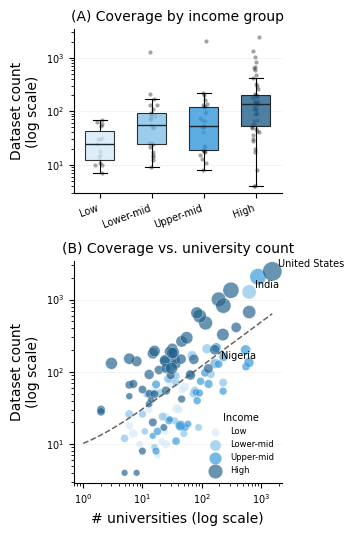

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Prepare data
# -----------------------------
plot_df = country_compare.copy()

# Clean / standardize income labels
income_order = ["L", "LM", "UM", "H"]
income_labels = {
    "L": "Low",
    "LM": "Lower-mid",
    "UM": "Upper-mid",
    "H": "High"
}

plot_df = plot_df[plot_df["income"].isin(income_order)].copy()
plot_df["income_label"] = plot_df["income"].map(income_labels)
plot_df["income_label"] = pd.Categorical(
    plot_df["income_label"],
    categories=[income_labels[x] for x in income_order],
    ordered=True
)

# Log-safe versions for plotting
plot_df["content_count_log"] = np.log1p(plot_df["content_count"])
plot_df["num_universities_log"] = np.log1p(plot_df["num_universities"])
plot_df["producer_count_log"] = np.log1p(plot_df["producer_count"])

# -----------------------------
# Colors
# -----------------------------
income_colors = {
    "Low": "#D6EAF8",
    "Lower-mid": "#85C1E9",
    "Upper-mid": "#3498DB",
    "High": "#21618C"
}
# -----------------------------
# Figure layout
# -----------------------------
fig, axes = plt.subplots(
    2, 1,
    figsize=(3.55, 5.4),
    gridspec_kw={"height_ratios": [1, 1.35]}
)

ax1, ax2 = axes

# ============================================================
# Panel A: Income group boxplot + jittered points
# ============================================================
box_data = [
    plot_df.loc[plot_df["income"] == inc, "content_count"] + 1
    for inc in income_order
]

box = ax1.boxplot(
    box_data,
    patch_artist=True,
    widths=0.55,
    showfliers=False,
    medianprops=dict(color="#1B2631", linewidth=1),
    boxprops=dict(linewidth=0.8),
    whiskerprops=dict(linewidth=0.8),
    capprops=dict(linewidth=0.8)
)

for patch, inc in zip(box["boxes"], income_order):
    patch.set_facecolor(income_colors[income_labels[inc]])
    patch.set_alpha(0.8)

# jittered country points
rng = np.random.default_rng(42)

for i, inc in enumerate(income_order, start=1):
    vals = plot_df.loc[plot_df["income"] == inc, "content_count"] + 1
    jitter = rng.normal(loc=i, scale=0.045, size=len(vals))
    ax1.scatter(
        jitter,
        vals,
        s=9,
        alpha=0.45,
        color="#333333",
        linewidth=0
    )

ax1.set_yscale("log")
ax1.set_xticks(range(1, len(income_order) + 1))
ax1.set_xticklabels([income_labels[x] for x in income_order], rotation=20, ha="right")
ax1.set_ylabel("Dataset count\n(log scale)")
ax1.set_title("(A) Coverage by income group", fontsize=10)

# ============================================================
# Panel B: Universities vs content count
# ============================================================
for label in [income_labels[x] for x in income_order]:
    sub = plot_df[plot_df["income_label"] == label]

    ax2.scatter(
        sub["num_universities"] + 1,
        sub["content_count"] + 1,
        s=20 + 2.2 * np.sqrt(sub["producer_count"].clip(lower=0)),
        alpha=0.68,
        color=income_colors[label],
        edgecolor="#F5F5F5",
        linewidth=0.3,
        label=label
    )

# Regression line in log-log space
reg_df = plot_df[
    (plot_df["num_universities"].notna()) &
    (plot_df["content_count"].notna())
].copy()

x_log = np.log1p(reg_df["num_universities"])
y_log = np.log1p(reg_df["content_count"])

coef = np.polyfit(x_log, y_log, deg=1)
x_line_log = np.linspace(x_log.min(), x_log.max(), 100)
y_line_log = coef[0] * x_line_log + coef[1]

ax2.plot(
    np.expm1(x_line_log),
    np.expm1(y_line_log),
    color="#555555",
    linewidth=1.1,
    linestyle="--",
    alpha=0.9,
)

# Annotate selected countries
annotate_countries = ["United States", "India", "Nigeria"]


for country in annotate_countries:
    row = plot_df[plot_df["country"] == country]
    if len(row) == 0:
        continue

    row = row.iloc[0]
    ax2.annotate(
        country,
        xy=(row["num_universities"] + 1, row["content_count"] + 1),
        xytext= (4, 3),
        textcoords="offset points",
        fontsize=7
    )

ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("# universities (log scale)")
ax2.set_ylabel("Dataset count\n(log scale)")
ax2.set_title("(B) Coverage vs. university count", fontsize=10)

# Optional legend: may be too big for one column
ax2.legend(
    title="Income",
    fontsize=6,
    title_fontsize=7,
    frameon=False,
    loc="lower right"
)

# -----------------------------
# Clean style
# -----------------------------
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", linewidth=0.4, alpha=0.35)
    ax.tick_params(axis="both", labelsize=7)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6
})    
    


plt.tight_layout()

plt.savefig("fig_infrastructure_alignment.pdf", bbox_inches="tight")
plt.savefig("fig_infrastructure_alignment.png", dpi=300, bbox_inches="tight")

plt.show()

In [121]:
spotlight_countries = [
    "United States",
    "China",
    "India",
    "Germany",
    "Nigeria",
    "Egypt",
    "Tunisia",
    "Ukraine"
]

spotlight_table = (
    country_compare[
        country_compare["country"].isin(spotlight_countries)
    ]
    .copy()
)

# Optional: round values for cleaner display
for col in ["content_self", "producer_self"]:
    spotlight_table[col] = spotlight_table[col].round(3)

# Sort in chosen order
spotlight_table["country"] = pd.Categorical(
    spotlight_table["country"],
    categories=spotlight_countries,
    ordered=True
)

spotlight_table = spotlight_table.sort_values("country")

# Display selected columns
spotlight_table = spotlight_table[
    [
        "country",
        "content_self",
        "content_count",
        "producer_self",
        "producer_count",
        "income",
        "continent",
        "num_universities"
    ]
]

spotlight_table

,country,content_self,content_count,producer_self,producer_count,income,continent,num_universities
114,United States,0.715,2455,0.291,6033,H,Americas,1561
18,China,0.792,2071,0.590,2782,UM,Asia,897
39,India,0.690,1277,0.633,1391,LM,Asia,636
32,Germany,0.669,1346,0.346,2601,H,Europe,312
75,Nigeria,0.231,130,0.157,191,LM,Africa,168
26,Egypt,0.186,167,0.225,138,LM,Africa,68
108,Tunisia,0.138,87,0.571,21,LM,Africa,36
111,Ukraine,0.205,127,0.684,38,UM,Europe,193


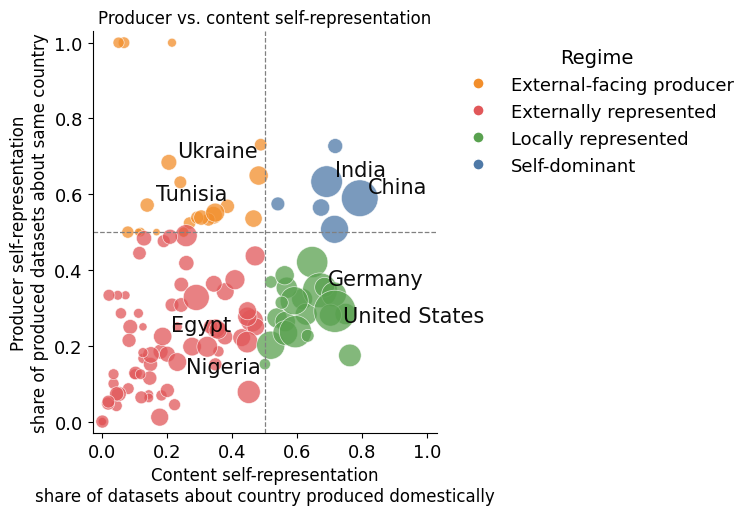

In [122]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# 4. Prepare plotting table
# -----------------------------
plot_cc = country_compare.copy()

# Add total volume for point sizing
plot_cc["total_count"] = plot_cc["content_count"] + plot_cc["producer_count"]

# Optional: filter tiny countries from the main plot if it gets too noisy
# Keep them in appendix or remove this line if you want all countries.
min_content_count = 5
plot_cc_main = plot_cc[plot_cc["content_count"] >= min_content_count].copy()

# Classify regimes using 0.5 thresholds.
def classify_regime(row):
    if row["content_self"] >= 0.5 and row["producer_self"] >= 0.5:
        return "Self-dominant"
    elif row["content_self"] < 0.5 and row["producer_self"] >= 0.5:
        return "External-facing producer"
    elif row["content_self"] >= 0.5 and row["producer_self"] < 0.5:
        return "Locally represented"
    else:
        return "Externally represented"

plot_cc_main["regime"] = plot_cc_main.apply(classify_regime, axis=1)

regime_colors = {
    "Self-dominant": "#4E79A7",
    "External-facing producer": "#F28E2B",
    "Locally represented": "#59A14F",
    "Externally represented": "#E15759",
}

# Size scaling: log prevents US/China from dominating visually




# -----------------------------
# 5. Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(7.6, 5.2))

for regime, sub in plot_cc_main.groupby("regime"):
    ax.scatter(
        sub["content_self"],
        sub["producer_self"],
        s=10*(sub["total_count"]**0.5),
        color=regime_colors[regime],
        alpha=0.75,
        edgecolor="white",
        linewidth=0.5,
        label=regime,
    )

# Reference lines for regimes
ax.axvline(0.5, color="gray", linestyle="--", linewidth=0.9)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.9)

# Axes
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("Content self-representation\nshare of datasets about country produced domestically", fontsize=12)
ax.set_ylabel("Producer self-representation\nshare of produced datasets about same country", fontsize=12)

ax.set_title("Producer vs. content self-representation", fontsize=12)

# Quadrant labels
# ax.text(0.73, 0.93, "Self-dominant", fontsize=8, ha="center")
# ax.text(0.23, 0.93, "External-facing\nproducers", fontsize=8, ha="center")
# ax.text(0.75, 0.06, "Locally\nrepresented", fontsize=8, ha="center")
# ax.text(0.23, 0.06, "Externally\nrepresented", fontsize=8, ha="center")

# Label only representative countries per regime
label_countries = {
    "Self-dominant": ["China", "India"],
    "Locally represented": ["United States", "Germany"],
    "External-facing producer": ["Tunisia", "Ukraine"],  # replace with clearer examples if desired
    "Externally represented": ["Egypt", "Nigeria"],
}

label_list = [c for vals in label_countries.values() for c in vals]
label_df = plot_cc_main[plot_cc_main["country"].isin(label_list)]

# Optional manual offsets to reduce overlap
offsets = {
    "China": (6, 4),
    "India": (6, 4),
    "United States": (6, -8),
    "Germany": (6, 4),
    "Ukraine": (6, 4),
    "Tunisia": (6, 4),
    "Egypt": (6, 4),
    "Nigeria": (6, -8),
}

for _, row in label_df.iterrows():
    dx, dy = offsets.get(row["country"], (5, 5))
    ax.annotate(
        row["country"],
        (row["content_self"], row["producer_self"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=15,
        alpha=0.95
    )
# Legend
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='External-facing producer',
           markerfacecolor="#F28E2B", markersize=8),
    Line2D([0], [0], marker='o', color='w', label='Externally represented',
           markerfacecolor="#E15759", markersize=8),
    Line2D([0], [0], marker='o', color='w', label='Locally represented',
           markerfacecolor="#59A14F", markersize=8),
    Line2D([0], [0], marker='o', color='w', label='Self-dominant',
           markerfacecolor="#4E79A7", markersize=8),
]

ax.legend(
    handles=legend_elements,
    title="Regime",
    fontsize=13,
    title_fontsize=14,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)
# Clean style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=13)
bbox_to_anchor=(1.02, 1.05)

plt.tight_layout()
plt.savefig("fig3_producer_content_self_representation.pdf", bbox_inches="tight")
plt.savefig("fig3_producer_content_self_representation.png", dpi=300, bbox_inches="tight")
plt.show()

In [124]:
plot_cc_main

,country,content_self,content_count,producer_self,producer_count,income,continent,num_universities,total_count,regime
0,Albania,0.100000,20,0.125000,16,UM,Europe,27,36,Externally represented
1,Algeria,0.086022,93,0.250000,32,UM,Africa,63,125,Externally represented
2,Argentina,0.179104,67,0.184615,65,UM,Americas,130,132,Externally represented
3,Armenia,0.117647,17,0.500000,4,UM,Asia,42,21,External-facing producer
4,Australia,0.460076,263,0.266520,454,H,Oceania,45,717,Externally represented
...,...,...,...,...,...,...,...,...,...,...
115,Uruguay,0.631579,19,0.226415,53,H,Americas,14,72,Locally represented
116,Uzbekistan,0.250000,20,0.500000,10,LM,Asia,34,30,External-facing producer
117,Vietnam,0.465116,129,0.535714,112,LM,Asia,166,241,External-facing producer
118,Yemen,0.018868,53,0.052632,19,L,Asia,15,72,Externally represented


In [125]:
plot_cc_main.to_csv("country_self_representation.csv", index=False)

## Figure 3 — Camera-ready (four-label regime scheme)

Regenerated from corrected producer data (`author_affiliation_all_merged_corrected.csv` via `final_merge.py`).
Uses the four-label regime scheme adopted in the camera-ready revision.

**Run Cell 189 first** (computes `country_compare` from the updated `worldbench_country_task_expanded.csv`),
then run the two cells below to produce the camera-ready Figure 3 and save the updated CSV.

Label scheme:
- **Locally produced, self-focused** — content_self >= 0.5 AND producer_self >= 0.5
- **Locally produced, outward-facing** — content_self >= 0.5 AND producer_self < 0.5
- **Externally represented, self-focused** — content_self < 0.5 AND producer_self >= 0.5
- **Externally represented, outward-facing** — content_self < 0.5 AND producer_self < 0.5

Hollow markers = producer_count < 10 (low-confidence producer attribution).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# -- Four-label regime scheme (camera-ready) ----------------------------------
def classify_regime(row):
    if row["content_self"] >= 0.5 and row["producer_self"] >= 0.5:
        return "Locally produced, self-focused"
    elif row["content_self"] >= 0.5 and row["producer_self"] < 0.5:
        return "Locally produced, outward-facing"
    elif row["content_self"] < 0.5 and row["producer_self"] >= 0.5:
        return "Externally represented, self-focused"
    else:
        return "Externally represented, outward-facing"

# -- Prepare plotting table ---------------------------------------------------
plot_cc = country_compare.copy()
plot_cc["total_count"] = plot_cc["content_count"] + plot_cc["producer_count"]

min_content_count = 5
plot_cc_main = plot_cc[(plot_cc["content_count"] >= min_content_count) & (plot_cc["producer_count"] >= 1)].copy()
plot_cc_main["regime"] = plot_cc_main.apply(classify_regime, axis=1)
plot_cc_main["hollow"] = plot_cc_main["producer_count"] < 10

regime_colors = {
    "Locally produced, self-focused":         "#4E79A7",
    "Locally produced, outward-facing":       "#59A14F",
    "Externally represented, self-focused":   "#F28E2B",
    "Externally represented, outward-facing": "#E15759",
}

# -- Plot ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.6, 5.8))

for regime, sub in plot_cc_main.groupby("regime"):
    color = regime_colors[regime]
    solid  = sub[~sub["hollow"]]
    hollow = sub[sub["hollow"]]
    ax.scatter(
        solid["content_self"], solid["producer_self"],
        s=10 * (solid["total_count"] ** 0.5),
        color=color, alpha=0.75, edgecolor="white", linewidth=0.5,
        label=regime,
    )
    ax.scatter(
        hollow["content_self"], hollow["producer_self"],
        s=10 * (hollow["total_count"] ** 0.5),
        facecolors="none", edgecolors=color, linewidth=1.2,
        label="_nolegend_",
    )

# Reference lines
ax.axvline(0.5, color="gray", linestyle="--", linewidth=0.9)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.9)

# Quadrant corner labels
ax.text(0.74, 0.97, "Locally produced\nself-focused",         fontsize=7.5, ha="center", va="top",    color="#333333")
ax.text(0.24, 0.97, "Externally represented\nself-focused",   fontsize=7.5, ha="center", va="top",    color="#333333")
ax.text(0.74, 0.03, "Locally produced\noutward-facing",       fontsize=7.5, ha="center", va="bottom", color="#333333")
ax.text(0.24, 0.03, "Externally represented\noutward-facing", fontsize=7.5, ha="center", va="bottom", color="#333333")

# Annotate representative countries
label_countries = ["China", "India", "United States", "Germany", "Nigeria", "Egypt", "Qatar", "Jordan"]
offsets = {
    "China":         (6,  4), "India":         (6,  4),
    "United States": (6, -8), "Germany":       (6,  4),
    "Nigeria":       (6, -8), "Egypt":         (6,  4),
    "Qatar":         (6,  4), "Jordan":        (6,  4),
}
label_df = plot_cc_main[plot_cc_main["country"].isin(label_countries)]
for _, row in label_df.iterrows():
    dx, dy = offsets.get(row["country"], (5, 5))
    ax.annotate(
        row["country"],
        (row["content_self"], row["producer_self"]),
        xytext=(dx, dy), textcoords="offset points",
        fontsize=9, alpha=0.95,
    )

ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel(
    "Content self-representation\n"
    "(share of datasets about country X produced domestically)",
    fontsize=11
)
ax.set_ylabel(
    "Producer self-representation\n"
    "(share of datasets produced by X that are about X)",
    fontsize=11
)
ax.set_title("Figure 3 — Producer vs. content self-representation (camera-ready)", fontsize=12)

legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=regime_colors[r], markersize=9, label=r)
    for r in [
        "Locally produced, self-focused",
        "Locally produced, outward-facing",
        "Externally represented, self-focused",
        "Externally represented, outward-facing",
    ]
] + [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="none",
           markeredgecolor="#555555", markersize=8, label="Hollow = producer_count < 10"),
]
ax.legend(
    handles=legend_elements, title="Regime",
    fontsize=10, title_fontsize=11,
    loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()
plt.savefig("fig3_producer_content_self_representation_camera_ready.pdf", bbox_inches="tight")
plt.savefig("fig3_producer_content_self_representation_camera_ready.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nRegime counts:")
print(plot_cc_main["regime"].value_counts().to_string())


In [ ]:
# Save updated self-representation table with four-label regime and metadata
save_cols = [
    "country", "content_self", "content_count",
    "producer_self", "producer_count",
    "income", "continent", "num_universities", "total_count", "regime",
]
if "income" not in plot_cc_main.columns and "country2income" in globals():
    plot_cc_main["income"] = plot_cc_main["country"].map(country2income)
if "continent" not in plot_cc_main.columns and "country2continent" in globals():
    plot_cc_main["continent"] = plot_cc_main["country"].map(country2continent)
if "num_universities" not in plot_cc_main.columns and "country2unis" in globals():
    plot_cc_main["num_universities"] = plot_cc_main["country"].map(country2unis)

save_cols_present = [c for c in save_cols if c in plot_cc_main.columns]
plot_cc_main[save_cols_present].to_csv("country_self_representation.csv", index=False)
plot_cc_main[save_cols_present].to_csv("country_self_representation_corrected.csv", index=False)

print(f"Saved {len(plot_cc_main)} rows to:")
print("  country_self_representation.csv")
print("  country_self_representation_corrected.csv")
print()
print(plot_cc_main["regime"].value_counts().to_string())


In [349]:
print(plot_cc_main["total_count"].min(), plot_cc_main["total_count"].max())

8 8488


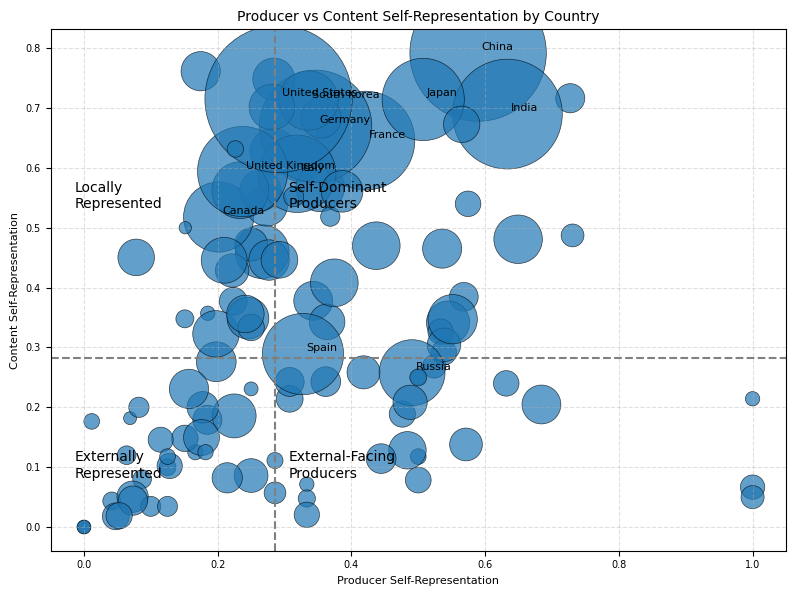

In [350]:
# Filter tiny countries if you want a cleaner plot
scatter_df = country_compare[country_compare["content_count"] >= 10].copy()

# Bubble sizes
sizes = (scatter_df["content_count"] ** 0.9) * 10

# Medians for quadrant lines
x_med = scatter_df["producer_self"].median()
y_med = scatter_df["content_self"].median()

plt.figure(figsize=(8, 6))

plt.scatter(
    scatter_df["producer_self"],
    scatter_df["content_self"],
    s=sizes,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

# Label top countries by content_count
top_countries = scatter_df.sort_values("content_count", ascending=False).head(12)

for _, row in top_countries.iterrows():
    plt.text(
        row["producer_self"] + 0.005,
        row["content_self"] + 0.005,
        row["country"],
        fontsize=8
    )

# Quadrant lines
plt.axvline(x=x_med, linestyle="--", color="gray")
plt.axhline(y=y_med, linestyle="--", color="gray")

# Quadrant labels
plt.text(x_med + 0.02, y_med + 0.25, "Self-Dominant\nProducers", fontsize=10)
plt.text(x_med + 0.02, y_med - 0.20, "External-Facing\nProducers", fontsize=10)
plt.text(x_med - 0.30, y_med - 0.20, "Externally\nRepresented", fontsize=10)
plt.text(x_med - 0.30, y_med + 0.25, "Locally\nRepresented", fontsize=10)

plt.xlabel("Producer Self-Representation")
plt.ylabel("Content Self-Representation")
plt.title("Producer vs Content Self-Representation by Country")
plt.grid(True, linestyle="--", alpha=0.4)
plt.savefig("representation_per_country.png")
plt.tight_layout()
plt.show()

In [351]:
import plotly.express as px

interactive_df = country_compare[country_compare["content_count"] >= 10].copy()
interactive_df["bubble_size"] = (interactive_df["content_count"] ** 0.7) * 4

x_med = interactive_df["producer_self"].median()
y_med = interactive_df["content_self"].median()

fig = px.scatter(
    interactive_df,
    x="producer_self",
    y="content_self",
    size="bubble_size",
    color="income" if "income" in interactive_df.columns else None,
    hover_name="country",
    hover_data={
        "producer_self": ':.3f',
        "content_self": ':.3f',
        "producer_count": True,
        "content_count": True,
        "bubble_size": False
    },
    title="Producer vs Content Self-Representation by Country",
    labels={
        "producer_self": "Producer Self-Representation",
        "content_self": "Content Self-Representation",
        "income": "Income Level"
    }
)

fig.add_vline(x=x_med, line_dash="dash", line_color="gray")
fig.add_hline(y=y_med, line_dash="dash", line_color="gray")

fig.update_traces(
    marker=dict(
        line=dict(width=0.5, color="black"),
        opacity=0.75
    )
)

fig.update_layout(width=900, height=700)
fig.show()

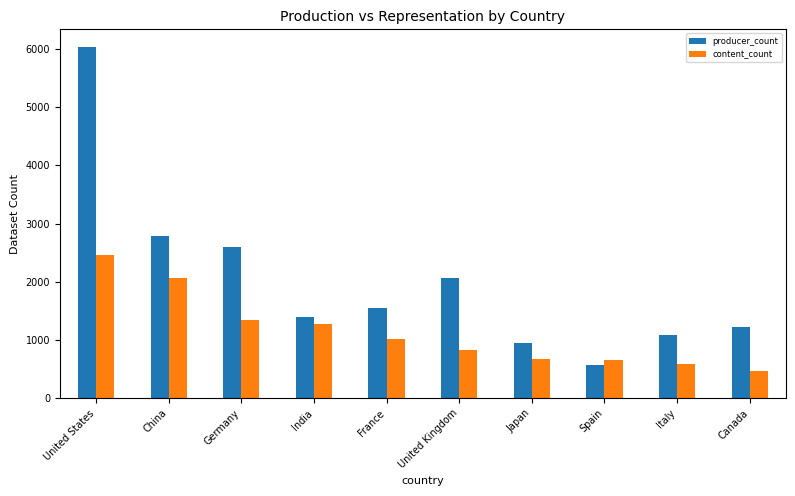

In [352]:
df_compare = country_compare.sort_values("content_count", ascending=False).head(10)

df_compare.set_index("country")[["producer_count", "content_count"]].plot(
    kind="bar", figsize=(8,5)
)

plt.title("Production vs Representation by Country")
plt.ylabel("Dataset Count")
plt.xticks(rotation=45, ha="right")  # ha helps readability
plt.tight_layout()
plt.savefig("Prod_vs_rep_bar.png")
plt.show()

In [353]:
df_raw = df_expanded.copy()
df_raw["producer_country_list"] = df_raw["producer_country_list"].apply(safe_parse_list)

raw_producers = sorted(df_raw["producer_country_list"].explode().dropna().unique())
raw_invalid = [c for c in raw_producers if normalize_country_token(c) not in VALID_COUNTRIES]

print("Raw invalid producer values:", raw_invalid[:50])
print("Count:", len(raw_invalid))

Raw invalid producer values: ['Jersey', 'Réunion']
Count: 2


Producer-country values were normalized using the same deterministic country standardization pipeline applied to content-country metadata. After normalization, the only remaining unmatched values were non-sovereign territories (e.g., Jersey, Réunion), which were excluded from sovereign-country analyses.

In [354]:
df_prod = df.copy()
df_prod = df_prod.explode("producer_country_list").rename(
    columns={"producer_country_list": "producer_country"}
)

df_prod = df_prod[
    df_prod["producer_country"].notna() &
    df_prod["content_country"].notna()
].copy()

In [355]:
# Top producer countries
top_producers = (
    df_prod["producer_country"]
    .value_counts()
    .head(10)
)
print(top_producers)

United States     6033
China             2782
Germany           2601
United Kingdom    2065
France            1549
India             1391
Canada            1216
Italy             1088
Japan              946
Netherlands        710
Name: producer_country, dtype: int64


High overlap across top countries shows that there is strong self representation

In [356]:
top_content = (
    df_prod["content_country"]
    .value_counts()
    .head(10)
)
print(top_content)

print("Overlap:", set(top_producers.index) & set(top_content.index))

United States     3271
China             2623
Germany           1927
India             1743
France            1381
United Kingdom    1299
Spain              956
Italy              905
Japan              886
Canada             666
Name: content_country, dtype: int64
Overlap: {'China', 'Italy', 'India', 'United Kingdom', 'France', 'United States', 'Germany', 'Japan', 'Canada'}


### Producer self representation

In [357]:
df_prod["is_self"] = df_prod["producer_country"] == df_prod["content_country"]

self_share = (
    df_prod.groupby("producer_country")["is_self"]
    .mean()
    .sort_values(ascending=False)
)

In [358]:
# high → country mostly produces datasets about itself
# low → produces datasets about others

df_prod["is_self"] = df_prod["producer_country"] == df_prod["content_country"]

overall_self_share = df_prod["is_self"].mean()
print("Overall self-representation share:", overall_self_share)

self_share_by_producer = (
    df_prod.groupby("producer_country")["is_self"]
    .mean()
    .sort_values(ascending=False)
)

print(self_share_by_producer.head(20))
print(self_share_by_producer.tail(20))

Overall self-representation share: 0.3381889402331915
producer_country
Brunei        1.000000
Guyana        1.000000
Kuwait        1.000000
Mozambique    1.000000
Oman          1.000000
Kazakhstan    0.730769
Iceland       0.727273
Ukraine       0.684211
Bangladesh    0.649351
India         0.633357
Peru          0.631579
China         0.589504
Sri Lanka     0.574468
Tunisia       0.571429
Estonia       0.568182
Taiwan        0.564885
Turkey        0.551471
Iran          0.544554
Pakistan      0.538462
Nepal         0.538462
Name: is_self, dtype: float64
producer_country
Togo                    0.125000
Lithuania               0.114754
Rwanda                  0.100000
Cameroon                0.086957
Uganda                  0.082192
United Arab Emirates    0.078125
Syria                   0.073171
Palestine               0.072727
Cyprus                  0.071429
Namibia                 0.068966
Mauritania              0.063830
Kosovo                  0.062500
Yemen                   0.

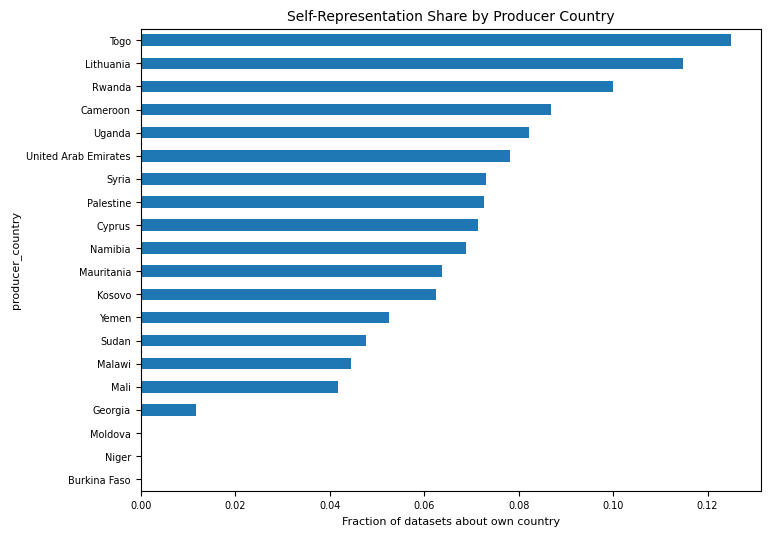

In [359]:
self_share.tail(20).plot(kind="barh", figsize=(8, 6))
plt.title("Self-Representation Share by Producer Country")
plt.xlabel("Fraction of datasets about own country")
plt.gca().invert_yaxis()
plt.show()

### Content self-share

In [360]:
df_prod["is_self"] = df_prod["producer_country"] == df_prod["content_country"]

content_self_share = (
    df_prod.groupby("content_country")["is_self"]
    .mean()
    .sort_values(ascending=False)
)

print(content_self_share.head(20))
# print(content_self_share.tail(20))

content_country
China             0.625238
South Korea       0.573892
Japan             0.541761
Iceland           0.539326
United States     0.536839
India             0.505450
France            0.472122
Taiwan            0.468354
Germany           0.467566
Israel            0.446009
Switzerland       0.442509
Singapore         0.431298
Denmark           0.414384
Czechia           0.411150
Belgium           0.394265
Italy             0.383425
United Kingdom    0.377213
Finland           0.370892
Qatar             0.368030
Canada            0.367868
Name: is_self, dtype: float64


In [361]:
content_external_share = 1 - content_self_share
content_external_share.tail(20)

content_country
Saint Lucia                         1.0
Saint Kitts and Nevis               1.0
Cabo Verde                          1.0
Cambodia                            1.0
Central African Republic            1.0
Chad                                1.0
Comoros                             1.0
Dominican Republic                  1.0
Panama                              1.0
Palau                               1.0
Cote d'Ivoire                       1.0
Cuba                                1.0
North Korea                         1.0
Niger                               1.0
Nicaragua                           1.0
Democratic Republic of the Congo    1.0
Djibouti                            1.0
Dominica                            1.0
Montenegro                          1.0
Congo (Congo-Brazzaville)           1.0
Name: is_self, dtype: float64

In [362]:
overall_content_self = df_prod["is_self"].mean()
print("Overall content-side self-representation:", overall_content_self)

Overall content-side self-representation: 0.3381889402331915


#### Top externally represented countries

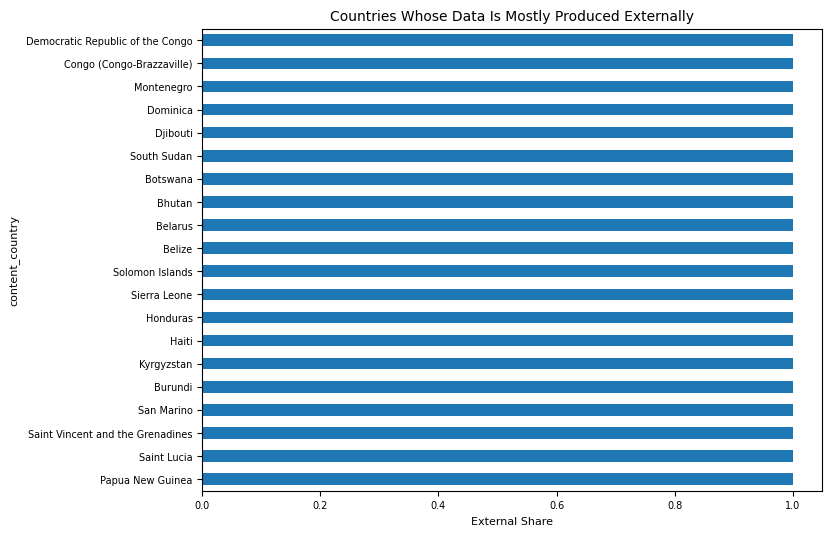

In [363]:
content_external_share.sort_values(ascending=False).head(20).plot(
    kind="barh", figsize=(8,6)
)
plt.title("Countries Whose Data Is Mostly Produced Externally")
plt.xlabel("External Share")
plt.gca().invert_yaxis()
plt.show()

In [364]:
## Countries whose data is all externally produced
content_external_share[content_external_share == 1]

content_country
South Sudan                         1.0
Botswana                            1.0
Bhutan                              1.0
Belarus                             1.0
Belize                              1.0
                                   ... 
Democratic Republic of the Congo    1.0
Djibouti                            1.0
Dominica                            1.0
Montenegro                          1.0
Congo (Congo-Brazzaville)           1.0
Name: is_self, Length: 74, dtype: float64

#### Top self represented countries

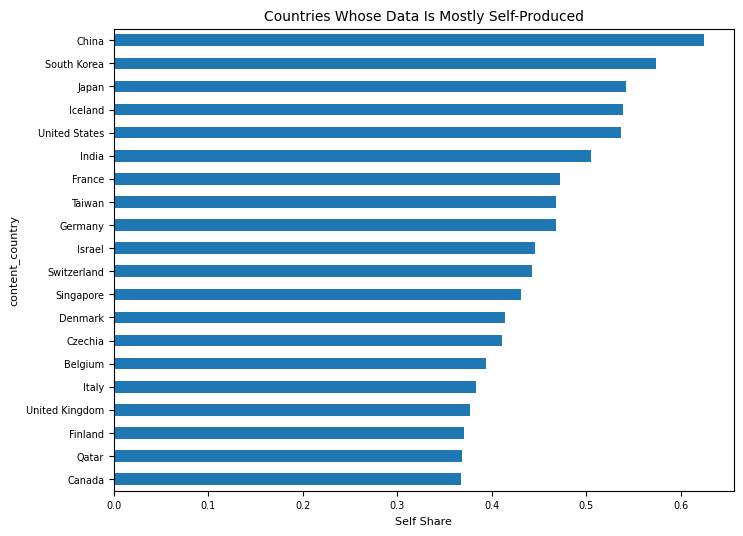

In [365]:
content_self_share.head(20).plot(kind="barh", figsize=(8,6))
plt.title("Countries Whose Data Is Mostly Self-Produced")
plt.xlabel("Self Share")
plt.gca().invert_yaxis()
plt.show()


Spotlight:

Case 1: High producer + high content self

→ self-sufficient ecosystems
(e.g., US, China likely)

Case 2: Low producer + low content self

→ externally represented countries
(this is very important)

Case 3: High producer + low content self

→ countries producing data about others
(global producers)



#### Result
Only ~34% of datasets are self-represented
~66% are externally produced

👉 That’s a very strong global imbalance statement

74 countries have only externally produced data, 38 of those countries have dataset counts less than 10

### Filtering out dataset counts less than 10

In [366]:
content_counts = df_prod["content_country"].value_counts()
valid = content_counts[content_counts >= 10].index

content_self_share = content_self_share.loc[valid]

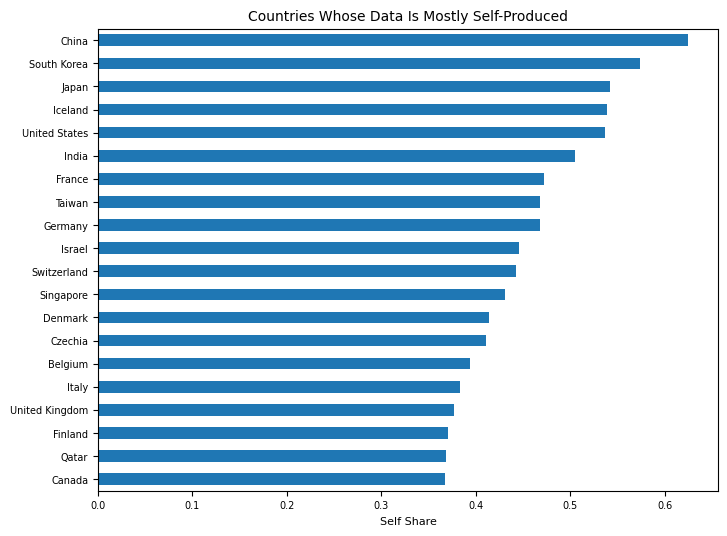

In [367]:
content_self_share.sort_values(ascending=False).head(20).plot(kind="barh", figsize=(8,6))
plt.title("Countries Whose Data Is Mostly Self-Produced")
plt.xlabel("Self Share")
plt.gca().invert_yaxis()
plt.show()

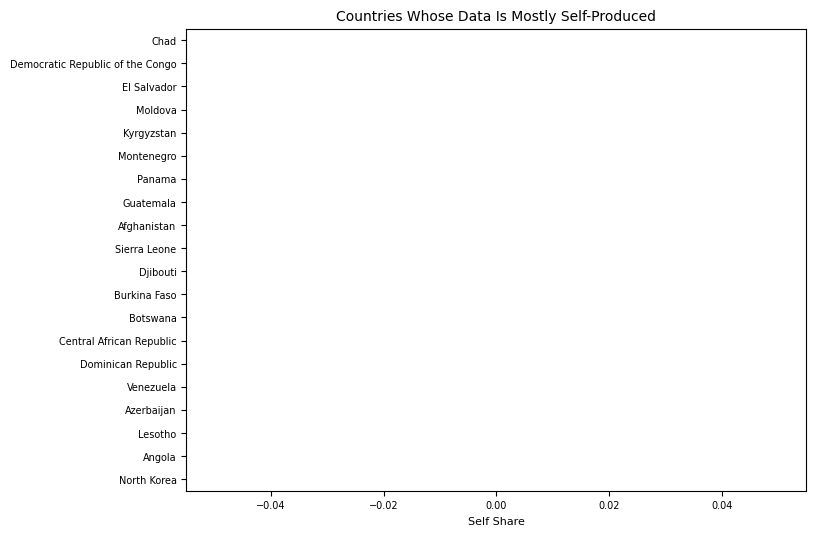

In [368]:
content_self_share.sort_values(ascending=False).tail(20).plot(kind="barh", figsize=(8,6))
plt.title("Countries Whose Data Is Mostly Self-Produced")
plt.xlabel("Self Share")
plt.gca().invert_yaxis()
plt.show()

In [369]:

## Countries whose data is all externally produced
print(len(content_self_share[content_self_share == 0]))
content_self_share[content_self_share == 0]

36


Tanzania                            0.0
Zimbabwe                            0.0
Djibouti                            0.0
Burkina Faso                        0.0
Botswana                            0.0
Afghanistan                         0.0
Dominican Republic                  0.0
Venezuela                           0.0
Azerbaijan                          0.0
Lesotho                             0.0
Angola                              0.0
Comoros                             0.0
Eswatini                            0.0
Burundi                             0.0
Niger                               0.0
Belarus                             0.0
Cote d'Ivoire                       0.0
Bolivia                             0.0
Cambodia                            0.0
Moldova                             0.0
Kyrgyzstan                          0.0
Montenegro                          0.0
Panama                              0.0
Guatemala                           0.0
Tajikistan                          0.0


We find that only 33.8% of dataset instances are self-represented, meaning that the majority of datasets describing a country are produced externally. This asymmetry is further reflected in country-level analysis, where several countries are predominantly represented by external producers, while a smaller subset maintains high levels of self-representation.

  ## Fig 1 Sankey

In [370]:
# !pip install kaleido --upgrade
#!python -m pip install --user kaleido==0.2.1

In [371]:
top_producers = df_prod["producer_country"].value_counts().head(5).index
top_content = df_prod["content_country"].value_counts().head(10).index
df_prod["content_country_simplified"] = df_prod["content_country"].apply(
    lambda x: x if x in top_content else "Other Countries"
)

In [372]:
edges = (
    df_prod.groupby(["producer_country", "content_country_simplified"])
    .size()
    .reset_index(name="value")
)

# keep only top producers
edges = edges[edges["producer_country"].isin(top_producers)]



In [373]:
import plotly.graph_objects as go
import kaleido

producers = list(top_producers)
contents = list(edges["content_country_simplified"].unique())

labels = [f"P: {p}" for p in producers] + [f"R: {c}" for c in contents]

label_to_index = {label: i for i, label in enumerate(labels)}

source = []
target = []
value = []



#producer_color = "#4E79A7"
content_color = "#05472A"
other_color = "#B9CC81"




# --------------------------------------------------
# 2. Color maps
# --------------------------------------------------

# producer_node_color_map = {
#     "P: United States": "#4C78A8",   # blue
#     "P: China": "#54A24B",           # green
#     "P: Germany": "#F58518",         # orange
#     "P: France": "#B279A2",          # purple
#     "P: United Kingdom": "#E45756",  # red
# }

producer_link_color_map = {
    "United States": "rgba(76,120,168,0.28)",
    "China": "rgba(84,162,75,0.28)",
    "Germany": "rgba(245,133,24,0.28)",
    "France": "rgba(178,121,162,0.28)",
    "United Kingdom": "rgba(228,87,86,0.28)",
}



# --------------------------------------------------
# 3. Build links and color each by producer
# --------------------------------------------------


producer_colors = ["#4C78A8", "#54A24B", "#F58518", "#B279A2", "#E45756"]

# Represented-country node colors
content_colors = []
for c in contents:
    if c == "Other Countries":
        content_colors.append("#02D8E9")   # gray for aggregated node
    else:
        content_colors.append("#13BBAF")   # uniform green for represented countries

node__colors = producer_colors + content_colors

source = []
target = []
value = []
link__colors = []

for _, row in edges.iterrows():
    source.append(label_to_index[f"P: {row['producer_country']}"])
    target.append(label_to_index[f"R: {row['content_country_simplified']}"])
    value.append(row["value"])
    producer = row['producer_country']
    if producer in producer_link_color_map.keys():
        link__colors.append(
        producer_link_color_map.get(producer, "rgba(120,120,120,0.25)")                               
        )


fig = go.Figure(go.Sankey(
    node=dict(
        pad=20,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels,
        color=node__colors
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color=link__colors
    )
))

fig.update_layout(
    #title="Dataset Production and Representation Across Countries",
    font_size=18,
    width=800,
    height=500
)

# Side headers
fig.add_annotation(
    x=0.01, y=1.10,
    text="Producer countries",
    showarrow=False,
    xanchor="left",
    font=dict(size=18)
)

fig.add_annotation(
    x=0.99, y=1.10,
    text="Represented countries",
    showarrow=False,
    xanchor="right",
    font=dict(size=18)
)

fig.write_html("producer_content_sankey.html")
fig.write_image("producer_content_sankey.png", scale=3)
fig.write_image("producer_content_sankey.pdf")


fig.show()

In [374]:
import plotly.graph_objects as go
import kaleido

# --------------------------------------------------
# 1. Nodes
# --------------------------------------------------

producers = list(top_producers)
contents = list(edges["content_country_simplified"].unique())

# Internal node IDs: keep producer/content nodes distinct
producer_ids = [f"P::{p}" for p in producers]
content_ids = [f"R::{c}" for c in contents]

node_ids = producer_ids + content_ids

label_to_index = {
    node_id: i
    for i, node_id in enumerate(node_ids)
}

# Display labels: clean names shown in figure
display_labels = producers + contents

# --------------------------------------------------
# 2. Colors
# --------------------------------------------------

producer_colors = [
    "#4C78A8",  # United States
    "#54A24B",  # China
    "#F58518",  # Germany
    "#B279A2",  # France
    "#E45756",  # United Kingdom
]

producer_link_color_map = {
    "United States": "rgba(76,120,168,0.28)",
    "China": "rgba(84,162,75,0.28)",
    "Germany": "rgba(245,133,24,0.28)",
    "France": "rgba(178,121,162,0.28)",
    "United Kingdom": "rgba(228,87,86,0.28)",
}

content_colors = []
for c in contents:
    if c == "Other Countries":
        content_colors.append("#02D8E9")
    else:
        content_colors.append("#13BBAF")

node_colors = producer_colors + content_colors

# --------------------------------------------------
# 3. Links
# --------------------------------------------------

source = []
target = []
value = []
link_colors = []

for _, row in edges.iterrows():
    producer = row["producer_country"]
    content = row["content_country_simplified"]

    source.append(label_to_index[f"P::{producer}"])
    target.append(label_to_index[f"R::{content}"])
    value.append(row["value"])

    link_colors.append(
        producer_link_color_map.get(
            producer,
            "rgba(120,120,120,0.25)"
        )
    )

# --------------------------------------------------
# 4. Sankey
# --------------------------------------------------

fig = go.Figure(go.Sankey(
    node=dict(
        pad=20,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=display_labels,
        color=node_colors
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color=link_colors
    )
))

fig.update_layout(
    font_size=23,
    width=800,
    height=500,
    margin=dict(l=20, r=20, t=60, b=20)
)

# Side headers
fig.add_annotation(
    x=0.01, y=1.10,
    text="Producer countries",
    showarrow=False,
    xanchor="left",
    font=dict(size=23)
)

fig.add_annotation(
    x=0.99, y=1.10,
    text="Represented countries",
    showarrow=False,
    xanchor="right",
    font=dict(size=23)
)

# --------------------------------------------------
# 5. Export
# --------------------------------------------------

fig.write_html("producer_content_sankey.html")
fig.write_image("producer_content_sankey.png", scale=3)
fig.write_image("producer_content_sankey.pdf")

fig.show()

In [375]:
import sys
print(sys.executable)

/sw/pkgs/arc/python3.10-anaconda/2023.03/bin/python


In [376]:
!which python
!pip show kaleido

/sw/pkgs/arc/python3.10-anaconda/2023.03/bin/python
Name: kaleido
Version: 0.2.1
Summary: Static image export for web-based visualization libraries with zero dependencies
Home-page: UNKNOWN
Author: Jon Mease
Author-email: jon@plotly.com
License: MIT
Location: /home/jnwatu/.local/lib/python3.10/site-packages
Requires: 
Required-by: 


In [377]:
import plotly, sys
print(sys.executable)
print(plotly.__version__)

/sw/pkgs/arc/python3.10-anaconda/2023.03/bin/python
5.9.0


In [378]:
import plotly.graph_objects as go
import pandas as pd

# Optional: keep only meaningful flows so the Sankey is readable
min_flow = 3
edges_plot = edges[edges["value"] >= min_flow].copy()

# Order nodes: producers on left, content countries on right
producers = list(top_producers)
contents = list(edges_plot["content_country_simplified"].unique())

# Keep "Other Countries" last
contents = [c for c in contents if c != "Other Countries"] + (
    ["Other Countries"] if "Other Countries" in contents else []
)

labels = [f"P: {p}" for p in producers] + [f"C: {c}" for c in contents]
label_to_idx = {label: i for i, label in enumerate(labels)}


source = []
target = []
value = []

for _, row in edges.iterrows():
    source.append(label_to_index[f"P: {row['producer_country']}"])
    target.append(label_to_index[f"C: {row['content_country_simplified']}"])
    value.append(row["value"])

# # Build source-target-value arrays
# source = edges_plot["producer_country"].map(label_to_idx)
# target = edges_plot["content_country_simplified"].map(label_to_idx)
# value = edges_plot["value"]

# # Build source-target-value arrays
# source = f"P: {edges_plot["producer_country"]}".map(label_to_idx)
# target = f"C: {edges_plot["content_country_simplified"]}".map(label_to_idx)
# value = edges_plot["value"]

# Optional: consistent colors
producer_color = "#4E79A7"
content_color = "#59A14F"
other_color = "#BAB0AC"

node_colors = (
    [producer_color] * len(producers)
    + [
        other_color if c == "Other Countries" else content_color
        for c in contents
    ]
)

# Link colors: light transparent blue
link_colors = ["rgba(78, 121, 167, 0.35)"] * len(edges_plot)

fig = go.Figure(
    data=[
        go.Sankey(
            arrangement="snap",
            node=dict(
                pad=18,
                thickness=18,
                line=dict(color="rgba(0,0,0,0.25)", width=0.5),
                label=labels,
                color=node_colors,
            ),
            link=dict(
                source=source,
                target=target,
                value=value,
                color=link_colors,
                hovertemplate=(
                    "%{source.label} → %{target.label}<br>"
                    "Datasets: %{value}<extra></extra>"
                ),
            ),
        )
    ]
)

fig.update_layout(
    title_text="Producer-to-content country flows",
    font=dict(size=12),
    width=950,
    height=550,
    margin=dict(l=20, r=20, t=50, b=20),
)

# fig.write_html("producer_content_sankey.html")
# fig.write_image("producer_content_sankey.png", scale=3)
# fig.write_image("producer_content_sankey.pdf")

fig.show()

KeyError: 'P: China'

In [379]:
import plotly.graph_objects as go

# --------------------------------------------------
# 1. Prepare nodes
# --------------------------------------------------

# Keep a stable, readable order
producers = list(top_producers)   # should already be the 5 producers you want

# Put "Other Countries" last if present
contents = list(edges["content_country_simplified"].unique())
contents = [c for c in contents if c != "Other Countries"] + (
    ["Other Countries"] if "Other Countries" in contents else []
)

# Internal IDs must stay distinct
producer_ids = [f"P:{p}" for p in producers]
content_ids = [f"C:{c}" for c in contents]

node_ids = producer_ids + content_ids

# Display labels can be clean
labels = producers + contents

id_to_index = {node_id: i for i, node_id in enumerate(node_ids)}

# --------------------------------------------------
# 2. Color maps
# --------------------------------------------------

producer_node_color_map = {
    "United States": "#4C78A8",   # blue
    "China": "#54A24B",           # green
    "Germany": "#F58518",         # orange
    "France": "#B279A2",          # purple
    "United Kingdom": "#E45756",  # red
}

producer_link_color_map = {
    "United States": "rgba(76,120,168,0.28)",
    "China": "rgba(84,162,75,0.28)",
    "Germany": "rgba(245,133,24,0.28)",
    "France": "rgba(178,121,162,0.28)",
    "United Kingdom": "rgba(228,87,86,0.28)",
}

# Producer-side node colors
producer_colors = [
    producer_node_color_map.get(p, "#4C78A8")
    for p in producers
]

# Represented-country node colors
content_colors = []
for c in contents:
    if c == "Other Countries":
        content_colors.append("#B0B0B0")   # gray for aggregated node
    else:
        content_colors.append("#F58518")   # uniform orange for represented countries

node_colors = producer_colors + content_colors

# --------------------------------------------------
# 3. Build links and color each by producer
# --------------------------------------------------

source = []
target = []
value = []
link_colors = []

for _, row in edges.iterrows():
    producer = row["producer_country"]
    content = row["content_country_simplified"]

    # Only keep edges that match current producer/content sets
    if producer not in producers or content not in contents:
        continue

    source.append(id_to_index[f"P:{producer}"])
    target.append(id_to_index[f"C:{content}"])
    value.append(row["value"])
    link_colors.append(
        producer_link_color_map.get(producer, "rgba(120,120,120,0.25)")
    )

# --------------------------------------------------
# 4. Optional: manually place nodes to reduce clutter
# --------------------------------------------------
# These positions assume 5 producers and ~7 content nodes.
# Adjust if your counts change.

x_positions = (
    [0.02] * len(producers) +   # left side
    [0.98] * len(contents)      # right side
)

# Even spacing top-to-bottom
def spaced_positions(n, top=0.05, bottom=0.95):
    if n == 1:
        return [0.5]
    step = (bottom - top) / (n - 1)
    return [top + i * step for i in range(n)]

producer_y = spaced_positions(len(producers), top=0.15, bottom=0.79)
content_y  = spaced_positions(len(contents), top=0.79, bottom=0.1)

y_positions = producer_y + content_y
# --------------------------------------------------
# 5. Create figure
# --------------------------------------------------

fig = go.Figure(go.Sankey(
    arrangement="fixed",
    node=dict(
    pad=30,
    thickness=10,
    line=dict(color="rgba(80,80,80,0.6)", width=0.5),
    label=labels,
    color=node_colors,
    x=x_positions,
    y=y_positions,
    hovertemplate="%{label}<extra></extra>"
),
    link=dict(
        source=source,
        target=target,
        value=value,
        color=link_colors,
        hovertemplate="From %{source.label} to %{target.label}<br>%{value} datasets<extra></extra>"
    )
))

# Side headers
fig.add_annotation(
    x=0.01, y=1.03,
    text="Producer countries",
    showarrow=False,
    xanchor="left",
    font=dict(size=14)
)

fig.add_annotation(
    x=0.99, y=1.03,
    text="Represented countries",
    showarrow=False,
    xanchor="right",
    font=dict(size=14)
)

fig.update_layout(
    title="Dataset Production and Representation Across Countries",
    font=dict(size=12),
    width=950,
    height=460,
    margin=dict(l=40, r=40, t=70, b=20),
)

fig.show()

#### 2 D plot

In [380]:
# Producer-side
producer_self_share = (
    df_prod.groupby("producer_country")["is_self"]
    .mean()
)

# Content-side
content_self_share = (
    df_prod.groupby("content_country")["is_self"]
    .mean()
)

In [381]:
df_compare = pd.DataFrame({
    "producer_self": producer_self_share,
    "content_self": content_self_share
}).dropna()

producer_counts = df_prod["producer_country"].value_counts()
content_counts = df_prod["content_country"].value_counts()

df_compare["producer_count"] = df_compare.index.map(producer_counts)
df_compare["content_count"] = df_compare.index.map(content_counts)

In [382]:
## filter out countries with less than 10

df_compare = df_compare[df_compare["content_count"] >= 10]

In [383]:
df_compare["income"] = df_compare.index.map(country2income)

In [384]:
import plotly.express as px

df_compare["size"] = (df_compare["content_count"] ** 0.7) * 5

fig = px.scatter(
    df_compare,
    x="producer_self",
    y="content_self",
    size="size",
    color="income",
    hover_name=df_compare.index,
    hover_data={
        "producer_self": ':.2f',
        "content_self": ':.2f',
        "producer_count": True,
        "content_count": True,
        "size": False
    },
    title="Producer vs Content Self-Representation"
)

# quadrant lines
x_med = df_compare["producer_self"].median()
y_med = df_compare["content_self"].median()

fig.add_vline(x=x_med, line_dash="dash", line_color="gray")
fig.add_hline(y=y_med, line_dash="dash", line_color="gray")

fig.update_layout(width=800, height=550)

fig.show()

### Interpretation

content_count = number of dataset rows where this country is the content_country
producer_count = number of dataset rows where this country is a producer_country
producer_self = For a given country C: Among datasets produced by C, what fraction are about C itself?
content_self(C) = (# datasets where producer = C AND content = C)/ (# datasets where content = C)

🔵 Top-right

Self-sufficient countries

produce their own data
are represented by themselves

Case 1: High producer_self + high content_self

→ country produces its own data and controls its representation
(self-sufficient)



🟠 Bottom-right

Outward producers

produce a lot
but not about themselves

Case 2: High producer_self + low content_self

→ country produces mostly for itself, but others also dominate representation
(mixed control)



🔴 Bottom-left

Externally represented countries

don’t produce much
are represented by others

👉 this is your key group
Case 3: Low producer_self + low content_self

→ country neither produces nor controls representation
(externally represented) ← 🔥 important



🟢 Top-left

Underproducing but self-represented

rare, interesting edge case

Case 4: Low producer_self + high content_self

→ rare, interesting case
(low output but self-controlled)

In [385]:
x_med = df_compare["producer_self"].median()
y_med = df_compare["content_self"].median()

def assign_quadrant(row):
    if row["producer_self"] >= x_med and row["content_self"] >= y_med:
        return "Self-sufficient"
    elif row["producer_self"] < x_med and row["content_self"] < y_med:
        return "Externally represented"
    elif row["producer_self"] >= x_med and row["content_self"] < y_med:
        return "Outward producers"
    else:
        return "Underproducing but self-represented"

df_compare["quadrant"] = df_compare.apply(assign_quadrant, axis=1)

In [386]:
labels = []

for q in df_compare["quadrant"].unique():
    subset = df_compare[df_compare["quadrant"] == q]
    top = subset.sort_values("content_count", ascending=False).head(3)
    labels.append(top)

df_labels = pd.concat(labels)

In [387]:
fig.update_traces(text=None)  # clear old labels if needed

fig.add_scatter(
    x=df_labels["producer_self"],
    y=df_labels["content_self"],
    mode="text",
    text=df_labels.index,
    textposition="top center",
    showlegend=False
)

### Country-level distribution

→ how many countries fall into each structural type

In [388]:
country_dist = df_compare["quadrant"].value_counts(normalize=True) * 100
print(country_dist)

Externally represented                 32.20339
Self-sufficient                        32.20339
Outward producers                      17.79661
Underproducing but self-represented    17.79661
Name: quadrant, dtype: float64


### Dataset-level distribution

→ how much of the actual data mass lies in each type

In [389]:
dataset_dist = (
    df_compare.groupby("quadrant")["content_count"]
    .sum()
    / df_compare["content_count"].sum()
) * 100

print(dataset_dist)

quadrant
Externally represented                 13.063277
Outward producers                       5.821712
Self-sufficient                        60.690004
Underproducing but self-represented    20.425007
Name: content_count, dtype: float64


### Interpretation (Detailed)

Self-Dominant Producers (top-right,	Self-sufficient) → emphasizes both production and control

External-Facing Producers (bottom-right, Outward producers) → clearer than “outward” (who are they facing? → others)

Externally Represented (bottom-left, Externally represented) → already perfect and important

Locally Represented (top-left, Underproducing but self-represented) → cleaner than the long version, still intuitive


#### 🔍 2. How to read your plot (tight explanation)

Axes:

x (producer_self) → what countries choose to produce
y (content_self) → who controls representation of a country

Bubble size → dataset volume
Color → income level

Dashed lines → medians (divide structural regimes)

#### 🧠 3. Storytelling using your actual countries

Let’s walk through the figure the way a reader would.

🌍 Anchor 1: The global centers (top-right-ish cluster)
🇨🇳 China
producer_self ≈ 0.59
content_self ≈ 0.63
very high counts

👉 Interpretation:

China both produces extensively and retains strong control over how it is represented.

This is a Self-Dominant Producer.

🇺🇸 United States
producer_self ≈ 0.29
content_self ≈ 0.54
largest producer_count (~6000)

👉 Interpretation:

The US produces a massive volume of datasets, but a large share of its output is about other countries. Despite this, it still retains strong representation over itself.

This is interesting:

not purely self-focused
but still highly self-represented

👉 It sits between:

Self-Dominant
and External-Facing

This nuance is very valuable in your paper.

🇬🇧 United Kingdom
producer_self ≈ 0.24
content_self ≈ 0.38

👉 Interpretation:

The UK produces broadly across countries and maintains moderate control over its own representation.

Less dominant than US/China → more balanced global actor.

🌍 Anchor 2: High production, low self-focus
(Right side, below horizontal line)

Examples: Ukraine, Indonesia, Tunisia

👉 Interpretation:

These countries produce datasets, but relatively little of that production is about themselves, and their representation is also largely external.

These are:

👉 External-Facing Producers

🌍 Anchor 3: The most important group (bottom-left)
🇳🇬 Nigeria, 🇪🇬 Egypt, 🇿🇦 South Africa
low producer_self
low content_self

👉 Interpretation:

These countries produce relatively little data about themselves, and most datasets describing them are produced externally.

This is your key finding.

👉 These are:

Externally Represented countries
🌍 Anchor 4: Extreme cases
🇰🇼 Kuwait
producer_self = 1.0
content_self ≈ 0.03
producer_count = 3
content_count = 106

👉 Interpretation:

Kuwait produces only self-focused datasets, but contributes almost nothing relative to the total data about it.

👉 This is a textbook asymmetry case:

total lack of representational control
despite perfect “self-focus” locally
🇲🇼 Malawi
very low on both axes
small counts

👉 Interpretation:

Minimal production and almost entirely external representation.

🌍 Anchor 5: Small but self-controlled
🇮🇸 Iceland
producer_self ≈ 0.73
content_self ≈ 0.54

👉 Interpretation:

Iceland produces mostly for itself and maintains relatively strong control over its representation despite smaller scale.

👉 This is:

Locally Represented
📊 4. Your quantitative results (very strong)
Country-level distribution
~32% Externally Represented
~32% Self-Dominant
~18% External-Facing
~18% Locally Represented

👉 Interpretation:

The world is structurally split across these regimes.

Dataset-level distribution (THIS IS THE PUNCHLINE)
~60.7% → Self-Dominant Producers
~20.4% → Locally Represented
~13.1% → Externally Represented
~5.8% → External-Facing

### Interpretation (Concise)

We analyze the relationship between dataset production and representation by comparing producer-side and content-side self-representation for each country. This reveals four structural regimes. A small set of countries, including China and the United States, emerge as self-dominant producers, combining high output with strong control over their own representation. In contrast, many countries, particularly in lower-income regions such as Nigeria and Egypt, fall into the externally represented category, where both production and representational control are limited. Notably, although these externally represented countries constitute a substantial portion of all countries, they account for a relatively small fraction of total datasets. Instead, over 60% of datasets are concentrated among self-dominant producers, highlighting a structural imbalance in both who produces data and who controls representation.

### How concentrated is global production?

In [390]:
total_production = df_prod["producer_country"].value_counts()

top5_share = total_production.head(5).sum() / total_production.sum()
top10_share = total_production.head(10).sum() / total_production.sum()

print("Top 5 producers share:", top5_share)
print("Top 10 producers share:", top10_share)

Top 5 producers share: 0.45995654435841726
Top 10 producers share: 0.6237108669706521


### Who produces data about other countries?

In [391]:
df_cross = df_prod[df_prod["producer_country"] != df_prod["content_country"]]

In [392]:
cross_production = df_cross["producer_country"].value_counts()

top5_cross_share = cross_production.head(5).sum() / cross_production.sum()
top10_cross_share = cross_production.head(10).sum() / cross_production.sum()

print("Top 5 producers (external data) share:", top5_cross_share)
print("Top 10 producers (external data) share:", top10_cross_share)

Top 5 producers (external data) share: 0.44691574956071395
Top 10 producers (external data) share: 0.598677517802645


### Which countries dominate specific regions?

In [393]:
top_producers = total_production.head(10).index

for c in top_producers:
    subset = df_cross[df_cross["producer_country"] == c]
    top_targets = subset["content_country"].value_counts().head(5)
    
    print("\nProducer:", c)
    print(top_targets)


Producer: United States
China             337
India             306
Germany           197
Spain             189
United Kingdom    166
Name: content_country, dtype: int64

Producer: China
United States     236
Germany            79
United Kingdom     67
France             51
Japan              48
Name: content_country, dtype: int64

Producer: Germany
United States     172
United Kingdom    101
Spain              79
France             73
Italy              69
Name: content_country, dtype: int64

Producer: United Kingdom
United States    180
Germany          106
China             92
Spain             70
France            55
Name: content_country, dtype: int64

Producer: France
United States    65
Germany          56
Spain            52
Italy            49
China            39
Name: content_country, dtype: int64

Producer: India
United States    111
Germany           32
Bangladesh        22
China             21
Spain             21
Name: content_country, dtype: int64

Producer: Canada
Unit

### Producer dominance per country

In [394]:
top_producer_per_country = (
    df_prod.groupby("content_country")["producer_country"]
    .agg(lambda x: x.value_counts().idxmax())
)

top_producer_share = (
    df_prod.groupby("content_country")["producer_country"]
    .agg(lambda x: x.value_counts().max() / len(x))
)

In [395]:
df_dom = pd.DataFrame({
    "top_producer": top_producer_per_country,
    "dominance_share": top_producer_share,
    "total_datasets": df_prod["content_country"].value_counts()
})

In [396]:
df_dom.sort_values("dominance_share", ascending=False).head(20)

,top_producer,dominance_share,total_datasets
Tonga,Netherlands,1.000000,1
Solomon Islands,Netherlands,1.000000,1
Palau,Netherlands,1.000000,1
Fiji,Italy,1.000000,1
China,China,0.625238,2623
South Korea,South Korea,0.573892,406
Japan,Japan,0.541761,886
Iceland,Iceland,0.539326,89
United States,United States,0.536839,3271
India,India,0.505450,1743


In [397]:
df_dom.sort_values("dominance_share", ascending=False)

,top_producer,dominance_share,total_datasets
Tonga,Netherlands,1.000000,1
Solomon Islands,Netherlands,1.000000,1
Palau,Netherlands,1.000000,1
Fiji,Italy,1.000000,1
China,China,0.625238,2623
...,...,...,...
Namibia,United States,0.105263,38
Cambodia,Singapore,0.100000,20
Senegal,France,0.087379,103
Kosovo,Netherlands,0.086957,23


In [398]:
df_dom.sort_values("dominance_share", ascending=False).to_csv('dominant_producer.csv')

Dataset production is highly concentrated, with the top five producer countries accounting for 45% of all datasets and an even larger share of datasets describing other countries. This concentration extends to representation: for many countries, a single external producer accounts for the majority of available datasets, indicating a structural imbalance in who defines and curates data about different regions.

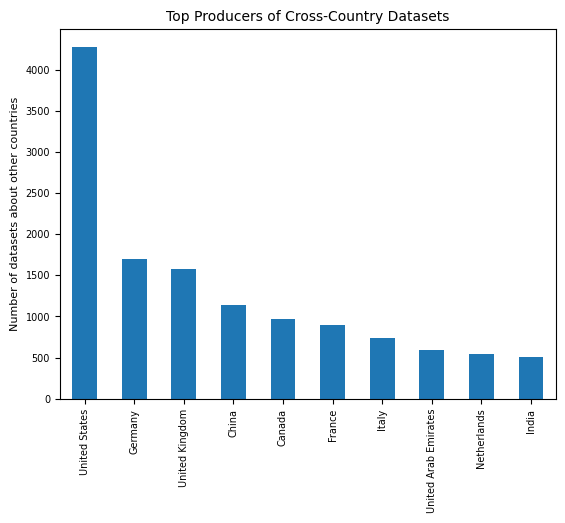

In [399]:
cross_production.head(10).plot(kind="bar")
plt.title("Top Producers of Cross-Country Datasets")
plt.ylabel("Number of datasets about other countries")
plt.show()

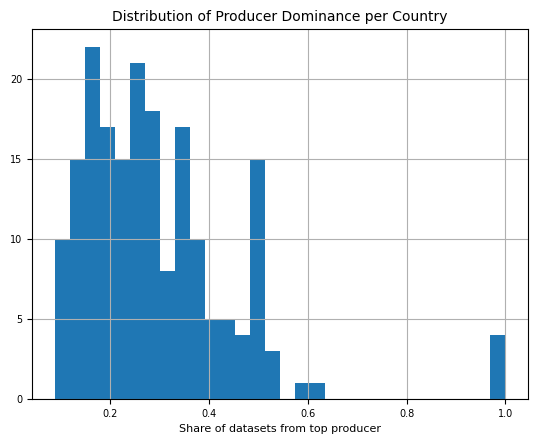

In [400]:
df_dom["dominance_share"].hist(bins=30)
plt.title("Distribution of Producer Dominance per Country")
plt.xlabel("Share of datasets from top producer")
plt.show()

# Thoughts


- Explore fancy plots like maps and simpler chats that get the point of each analysis across directly
- Check correlation between country's income status or GDP and the datasets
- Check Huggingface data as well
- Think critically about why things are missing or over inflated and perhaps do some deeper work to find out more evidence that support your findings
- Based on datasets we can also look at which countries or institutions care about which tasks as well as top producers in each country.


- Do we also want to consider the number of universities present in a country to see how that affects coverage
- We also need to look at languages (which are popular, how many covered, which of them stretch)
- we need to analyse the pool that have no country association but have language associations to see which languages these are for
- We need to look at the producer distribution as well and capture that story
- Beyond, look at the gaps in datasets, what deeper, imapctful insights can we find?

- We need to catalog these datasets in a website/page for easy access to public and share insights there too

- Findings my grow to be a lot so we caould have a longer report version and save highlight for the main paper

In [401]:
# Look into languages, spotlight a few global languages like Spanish and expand to see how many data counts per country for spanish
# arabic 

In [402]:
from scipy.stats import pearsonr

# example (replace with your actual values)
representation = [81, 82, 69, 71]  # Jordan, Palestine, Syria, Lebanon
gpt_acc = [0.972, 0.945, 0.910, 0.780]
qwen_acc = [0.928, 0.857, 0.756, 0.608]

print("GPT:", pearsonr(representation, gpt_acc))
print("Qwen:", pearsonr(representation, qwen_acc))

GPT: PearsonRResult(statistic=0.6794397507933851, pvalue=0.32056024920661486)
Qwen: PearsonRResult(statistic=0.8017722600734137, pvalue=0.19822773992658627)


PLots

## Languages

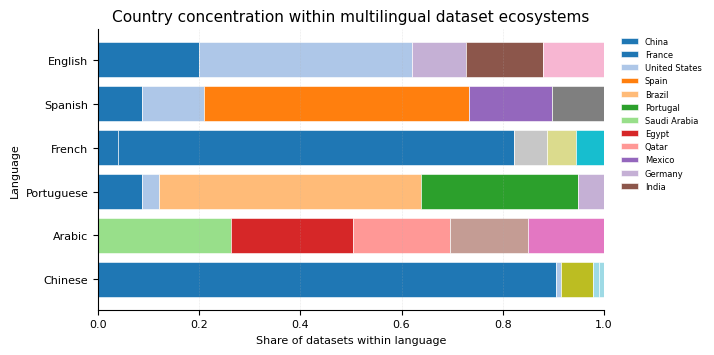

In [403]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# Build dataframe manually from language-country counts
# (replace or load from your actual dataframe if needed)
# --------------------------------------------------

rows = [
    # English
    ("English", "United States", 1940),
    ("English", "China", 923),
    ("English", "India", 709),
    ("English", "United Kingdom", 554),
    ("English", "Germany", 493),

    # Spanish
    ("Spanish", "Spain", 108),
    ("Spanish", "Mexico", 34),
    ("Spanish", "United States", 25),
    ("Spanish", "Peru", 21),
    ("Spanish", "China", 18),
    
     # French
    ("French", "France", 420),
    ("French", "Switzerland", 35),
    ("French", "Canada", 31),
    ("French", "Belgium", 29),
    ("French", "China", 21),
    
    # Portuguese
    ("Portuguese", "Brazil", 60),
    ("Portuguese", "Portugal", 36),
    ("Portuguese", "China", 10),
    ("Portuguese", "Germany", 6),
    ("Portuguese", "United States", 4),

    # Arabic
    ("Arabic", "Saudi Arabia", 113),
    ("Arabic", "Egypt", 104),
    ("Arabic", "Qatar", 83),
    ("Arabic", "Morocco", 66),
    ("Arabic", "Palestine", 65),

    # Chinese
    ("Chinese", "China", 844),
    ("Chinese", "Taiwan", 58),
    ("Chinese", "Japan", 11),
    ("Chinese", "United States", 10),
    ("Chinese", "South Korea", 9),

]

lang_df = pd.DataFrame(rows, columns=["language", "country", "count"])

# --------------------------------------------------
# Normalize within each language
# --------------------------------------------------

lang_df["share"] = (
    lang_df.groupby("language")["count"]
    .transform(lambda x: x / x.sum())
)

# --------------------------------------------------
# Pivot for stacked bar plot
# --------------------------------------------------

pivot_lang = lang_df.pivot(
    index="language",
    columns="country",
    values="share"
).fillna(0)

# Preserve language order
# language_order = [
#     "English",
#     "Spanish",
#     "French",
#     "Portuguese",
#     "Arabic",
#     "Chinese",
# ]
language_order = [
     "Chinese",
    "Arabic",
    "Portuguese",
    "French",
    "Spanish",
    "English",
   
]

pivot_lang = pivot_lang.loc[language_order]

# --------------------------------------------------
# Sort countries globally by total contribution
# --------------------------------------------------

country_order = (
    pivot_lang.sum(axis=0)
    .sort_values(ascending=False)
    .index
)

pivot_lang = pivot_lang[country_order]

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7.2, 3.6))

bottom = np.zeros(len(pivot_lang))

# Color palette
colors = plt.cm.tab20(np.linspace(0, 1, len(pivot_lang.columns)))

for i, country in enumerate(pivot_lang.columns):
    values = pivot_lang[country].values

    ax.barh(
        pivot_lang.index,
        values,
        left=bottom,
        color=colors[i],
        edgecolor="white",
        linewidth=0.4,
        label=country
    )

    bottom += values

# --------------------------------------------------
# Style
# --------------------------------------------------

ax.set_xlim(0, 1)

ax.set_xlabel("Share of datasets within language")
ax.set_ylabel("Language")

ax.set_title(
    "Country concentration within multilingual dataset ecosystems",
    fontsize=11
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.4,
    alpha=0.3
)

ax.tick_params(axis="both", labelsize=8)

# --------------------------------------------------
# Compact legend
# --------------------------------------------------

handles, labels = ax.get_legend_handles_labels()

# keep only top countries appearing prominently
top_legend = 12

ax.legend(
    handles[:top_legend],
    labels[:top_legend],
    fontsize=6,
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "fig_language_country_concentration.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "fig_language_country_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

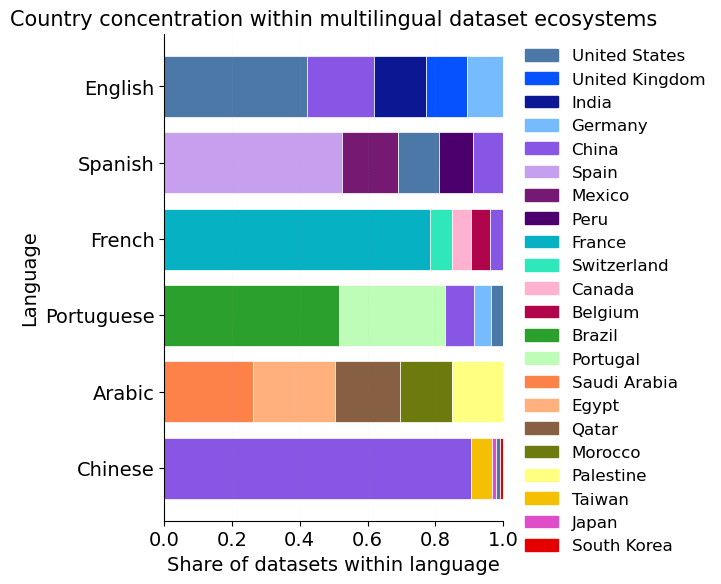

In [425]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

def desaturate_color(color, gray_level=0.6):
    """
    Mix color with gray.
    gray_level: 0 → original color
                1 → fully gray
    """
    rgb = np.array(mcolors.to_rgb(color))
    gray = np.array([0.7, 0.7, 0.7])  # neutral gray
    new_rgb = (1 - gray_level) * rgb + gray_level * gray
    return mcolors.to_hex(new_rgb)

# --------------------------------------------------
# Language-country counts
# --------------------------------------------------

rows = [
    ("English", "United States", 1940),
    ("English", "China", 923),
    ("English", "India", 709),
    ("English", "United Kingdom", 554),
    ("English", "Germany", 493),

    ("Spanish", "Spain", 108),
    ("Spanish", "Mexico", 34),
    ("Spanish", "United States", 25),
    ("Spanish", "Peru", 21),
    ("Spanish", "China", 18),

    ("French", "France", 420),
    ("French", "Switzerland", 35),
    ("French", "Canada", 31),
    ("French", "Belgium", 29),
    ("French", "China", 21),

    ("Portuguese", "Brazil", 60),
    ("Portuguese", "Portugal", 36),
    ("Portuguese", "China", 10),
    ("Portuguese", "Germany", 6),
    ("Portuguese", "United States", 4),

    ("Arabic", "Saudi Arabia", 113),
    ("Arabic", "Egypt", 104),
    ("Arabic", "Qatar", 83),
    ("Arabic", "Morocco", 66),
    ("Arabic", "Palestine", 65),

    ("Chinese", "China", 844),
    ("Chinese", "Taiwan", 58),
    ("Chinese", "Japan", 11),
    ("Chinese", "United States", 10),
    ("Chinese", "South Korea", 9),
]

lang_df = pd.DataFrame(rows, columns=["language", "country", "count"])

language_order = [
    "English",
    "Spanish",
    "French",
    "Portuguese",
    "Arabic",
    "Chinese"
]

lang_df["language"] = pd.Categorical(
    lang_df["language"],
    categories=language_order,
    ordered=True
)

# --------------------------------------------------
# Compute within-language shares
# --------------------------------------------------

lang_df["share"] = (
    lang_df.groupby("language", observed=True)["count"]
    .transform(lambda x: x / x.sum())
)

# --------------------------------------------------
# Country colors
# --------------------------------------------------

# country_colors = {
#     "United States": "#4E79A7",
#     "China": "#F28E2B",
#     "India": "#59A14F",
#     "United Kingdom": "#B07AA1",
#     "Germany": "#9C755F",

#     "Spain": "#E15759",
#     "Mexico": "#76B7B2",
#     "Peru": "#EDC948",

#     "France": "#1B9E77",
#     "Switzerland": "#D95F02",
#     "Canada": "#7570B3",
#     "Belgium": "#E7298A",

#     "Brazil": "#2CA02C",
#     "Portugal": "#98DF8A",

#     "Saudi Arabia": "#D62728",
#     "Egypt": "#FF9896",
#     "Qatar": "#9467BD",
#     "Morocco": "#8C564B",
#     "Palestine": "#E377C2",

#     "Taiwan": "#BCBD22",
#     "Japan": "#17BECF",
#     "South Korea": "#7F7F7F",
# }

fallback_color = "#CCCCCC"

country_colors = {
    # English (Blues)
    "United States": "#4C78A8",
    "United Kingdom": "#0652ff",
    "India": "#0c1793",
    "Germany": "#75bbfd",
    "China": "#8756e4",

    # Spanish (Reds)
    "Spain": "#c79fef",
    "Mexico": "#751973",
    "Peru": "#4b006e",

    # French (Teals)
    "France": "#06b1c4",
    "Switzerland": "#2ee8bb",
    "Canada": "#ffb2d0",
    "Belgium": "#b0054b",

    # Portuguese (Greens)
    "Brazil": "#2CA02C",
    "Portugal": "#befdb7",

    # Arabic (Purples)
    "Saudi Arabia": "#fc824a",
    "Egypt": "#ffb07c",
    "Qatar": "#875f42",
    "Morocco": "#6c7a0e",
    "Palestine": "#ffff81",

    # Chinese (Oranges)
    "Taiwan": "#f5bf03",
    "Japan": "#df4ec8",
    "South Korea": "#e50000",
}


country_colors_soft = {
    country: desaturate_color(color, gray_level=0.7)
    for country, color in country_colors.items()
}


# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7.2, 6))

y_positions = np.arange(len(language_order))

for y, language in zip(y_positions, language_order):
    sub = (
        lang_df[lang_df["language"] == language]
        .sort_values("share", ascending=False)
        .copy()
    )

    left = 0

    for _, row in sub.iterrows():
        country = row["country"]
        share = row["share"]

        ax.barh(
            y,
            share,
            left=left,
            color=country_colors.get(country, fallback_color),
            edgecolor="white",
            linewidth=0.5
        )

        left += share

    # annotate dominant country/share
#     top = sub.iloc[0]
#     ax.text(\centering
#         0.01,
#         y,
#         f"{top['country']} ({top['share']*100:.0f}%)",
#         va="center",
#         ha="left",
#         fontsize=12,
#         color="white" if top["share"] > 0.35 else "black",
#         fontweight="bold"
#    )

# --------------------------------------------------
# Style
# --------------------------------------------------

ax.set_yticks(y_positions)
ax.set_yticklabels(language_order)

# Put English at the top
ax.invert_yaxis()

ax.set_xlim(0, 1)
ax.set_xlabel("Share of datasets within language", fontsize=14)
ax.set_ylabel("Language", fontsize=14)
ax.set_title(
    "Country concentration within multilingual dataset ecosystems",
    fontsize=15
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.4,
    alpha=0.1
)

ax.tick_params(axis="both", labelsize=14)

# Optional: remove legend for cleaner paper figure
# If you want a legend, uncomment below.
handles = [
    plt.Rectangle((0, 0), 1, 1, color=color)
    for country, color in country_colors.items()
    if country in lang_df["country"].unique()
]
labels = [
    country
    for country in country_colors
    if country in lang_df["country"].unique()
]
ax.legend(
    handles,
    labels,
    fontsize=12,
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "fig_language_country_concentration.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "fig_language_country_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

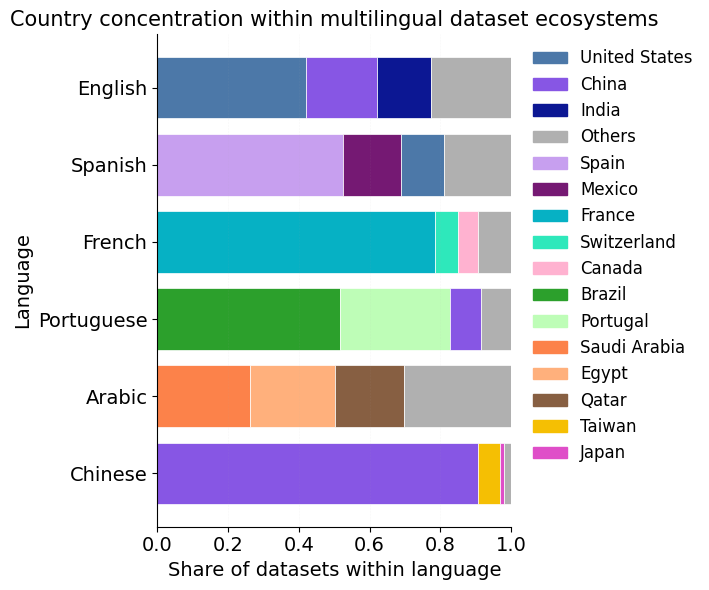

In [143]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def desaturate_color(color, gray_level=0.6):
    rgb = np.array(mcolors.to_rgb(color))
    gray = np.array([0.7, 0.7, 0.7])
    new_rgb = (1 - gray_level) * rgb + gray_level * gray
    return mcolors.to_hex(new_rgb)

# --- Data (reuse from previous cell) ---
rows = [
    ("English", "United States", 1940),
    ("English", "China", 923),
    ("English", "India", 709),
    ("English", "United Kingdom", 554),
    ("English", "Germany", 493),
    ("Spanish", "Spain", 108),
    ("Spanish", "Mexico", 34),
    ("Spanish", "United States", 25),
    ("Spanish", "Peru", 21),
    ("Spanish", "China", 18),
    ("French", "France", 420),
    ("French", "Switzerland", 35),
    ("French", "Canada", 31),
    ("French", "Belgium", 29),
    ("French", "China", 21),
    ("Portuguese", "Brazil", 60),
    ("Portuguese", "Portugal", 36),
    ("Portuguese", "China", 10),
    ("Portuguese", "Germany", 6),
    ("Portuguese", "United States", 4),
    ("Arabic", "Saudi Arabia", 113),
    ("Arabic", "Egypt", 104),
    ("Arabic", "Qatar", 83),
    ("Arabic", "Morocco", 66),
    ("Arabic", "Palestine", 65),
    ("Chinese", "China", 844),
    ("Chinese", "Taiwan", 58),
    ("Chinese", "Japan", 11),
    ("Chinese", "United States", 10),
    ("Chinese", "South Korea", 9),
]
lang_df = pd.DataFrame(rows, columns=["language", "country", "count"])

language_order = [
    "English",
    "Spanish",
    "French",
    "Portuguese",
    "Arabic",
    "Chinese"
]
lang_df["language"] = pd.Categorical(lang_df["language"], categories=language_order, ordered=True)

# --- Compute shares and group top 3 + others ---
def top3_others(df):
    out = []
    for lang, group in df.groupby("language"):
        group = group.sort_values("count", ascending=False)
        top3 = group.head(3)
        others = group.iloc[3:]
        total = group["count"].sum()
        for _, row in top3.iterrows():
            out.append({
                "language": lang,
                "country": row["country"],
                "count": row["count"],
                "share": row["count"] / total
            })
        if not others.empty:
            out.append({
                "language": lang,
                "country": "Others",
                "count": others["count"].sum(),
                "share": others["count"].sum() / total
            })
    return pd.DataFrame(out)

lang_top3 = top3_others(lang_df)

# --- Color map (distinct for each country, gray for 'Others') ---
country_palette = {
    # English
    "United States": "#4C78A8",
    "China": "#8756e4",
    "India": "#0c1793",
    # Spanish
    "Spain": "#c79fef",
    "Mexico": "#751973",
    "United States": "#4C78A8",
    # French
    "France": "#06b1c4",
    "Switzerland": "#2ee8bb",
    "Canada": "#ffb2d0",
    # Portuguese
    "Brazil": "#2CA02C",
    "Portugal": "#befdb7",
    "China": "#8756e4",
    # Arabic
    "Saudi Arabia": "#fc824a",
    "Egypt": "#ffb07c",
    "Qatar": "#875f42",
    # Chinese
    "China": "#8756e4",
    "Taiwan": "#f5bf03",
    "Japan": "#df4ec8",
    # fallback
    "Others": "#B0B0B0"
}
# Make sure all countries in lang_top3 have a color
for c in lang_top3["country"].unique():
    if c not in country_palette:
        country_palette[c] = "#CCCCCC"

# --- Plot ---
fig, ax = plt.subplots(figsize=(7.2, 6))
y_positions = np.arange(len(language_order))

for y, language in zip(y_positions, language_order):
    sub = lang_top3[lang_top3["language"] == language]
    left = 0
    for _, row in sub.iterrows():
        country = row["country"]
        share = row["share"]
        color = country_palette.get(country, "#CCCCCC")
        ax.barh(
            y,
            share,
            left=left,
            color=color,
            edgecolor="white",
            linewidth=0.5
        )
        left += share

ax.set_yticks(y_positions)
ax.set_yticklabels(language_order)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Share of datasets within language", fontsize=14)
ax.set_ylabel("Language", fontsize=14)
ax.set_title(
    "Country concentration within multilingual dataset ecosystems",
    fontsize=15
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.4, alpha=0.1)
ax.tick_params(axis="both", labelsize=14)

# Legend
handles = [
    plt.Rectangle((0, 0), 1, 1, color=country_palette[c])
    for c in lang_top3["country"].unique()
]
labels = list(lang_top3["country"].unique())
ax.legend(
    handles,
    labels,
    fontsize=12,
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "fig_language_country_concentration.pdf",
    bbox_inches="tight"
)

plt.show()